# Predicción de precios de viviendas en Ames: preparación, modelado, optimización de hiperparámetros, ensambles y selección final

**MLY1101 Machine Learning · Caso B: Housing Prices · Evaluación Parcial 3**

El notebook parte de `data/processed/ames_clean.csv`, la salida de la EP1, y llega hasta el modelo final para apoyar la tasación de viviendas. Cada decisión se prueba aquí mismo.

| Parte | Secciones | Contenido |
|---|---|---|
| 1. Preparación de datos | 1 a 18 | EDA y outliers (1 a 6), qué necesitan los árboles (7 y 8), zonas no residenciales, limpieza y variables de la venta (9 a 11), pipelines finales y guardado de los CSV (12 a 18) |
| 2. Modelado (EP2) | 19 a 27 | Criterio de salida y regla de elección, cuatro modelos con parámetros iniciales, test, error por segmento y elección |
| 3. Hiperparámetros (EP3, IE9) | 28 a 40 | Protocolo, línea base, espacios de búsqueda, búsquedas en Random Forest y XGBoost, evidencia de cada valor, Ridge y Lasso, antes y después |
| 4. Ensambles, generalización y selección (EP3, IE10 a IE12) | 41 a 52 | Bagging, boosting, votación y stacking; folds nuevos, validación anidada y curvas de aprendizaje; test final, selección, uso para el tasador y modelo guardado |

Las partes 1 y 2 usan parámetros iniciales fijos (sección 21); la búsqueda de hiperparámetros está en la parte 3.

Entorno y cifras: el notebook corre en local con el `.venv` del proyecto y en Google Colab, con las versiones exactas de `requirements.txt` (numpy 2.1.3, pandas 2.2.3, scikit-learn 1.6.1, xgboost 3.4.1). Todas las salidas y las cifras del texto son de una sola ejecución completa en Windows con Python 3.13. En Linux o Colab, Ridge y Lasso dan lo mismo; Random Forest, XGBoost y los ensambles pueden cambiar algunos dólares, y en XGBoost eso basta para que gane otra configuración de la misma zona plana (sección 35.2). Las conclusiones no cambian.

Estructura del proyecto: `data/`, `notebooks/`, `models/` (búsquedas, resultados de la parte 4 y modelo final), `images/`, `docs/` (informe técnico) y `README.md`.

**Versiones fijas**

En Colab, la celda siguiente lee `requirements.txt` (desde `URL_REQUIREMENTS` o subido a mano) y compara las versiones de numpy, pandas, scikit-learn y xgboost. Si no coinciden, instala las exactas y reinicia la sesión, y hay que volver a ejecutar desde el inicio. En local no instala nada: usa el `.venv` del proyecto (kernel «Housing P3 (.venv)»).

In [1]:
# Versiones fijas: en Colab instala las de requirements.txt y reinicia la sesión; en local no hace nada (usa el .venv)
import os, sys, re, shutil, subprocess, urllib.request
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

EN_COLAB = 'google.colab' in sys.modules
URL_REQUIREMENTS = 'https://raw.githubusercontent.com/<USUARIO>/<REPO>/<RAMA>/requirements.txt'
LIBRERIAS_CLAVE = ['numpy', 'pandas', 'scikit-learn', 'xgboost']

if EN_COLAB:
    REQ = Path('/content/requirements.txt')
    if not REQ.exists() and '<USUARIO>' not in URL_REQUIREMENTS:
        try:
            urllib.request.urlretrieve(URL_REQUIREMENTS, REQ)
        except Exception as e:
            print(f'No se pudo descargar {URL_REQUIREMENTS}: {e}')
    if not REQ.exists():
        from google.colab import files
        print('Sube requirements.txt')
        subido = files.upload()
        shutil.move(str(Path('/content') / next(iter(subido))), REQ)

    fijadas = dict(re.findall(r'^\s*([A-Za-z0-9_.\-]+)\s*==\s*([^\s#;]+)', REQ.read_text(), re.MULTILINE))

    def instalada(lib):
        try:
            return version(lib)
        except PackageNotFoundError:
            return None

    distintas = {lib: (instalada(lib), fijadas.get(lib)) for lib in LIBRERIAS_CLAVE
                 if instalada(lib) != fijadas.get(lib)}
    if distintas:
        print('Versiones distintas (instalada, requerida):', distintas)
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(REQ)], check=True)
        print('Versiones instaladas, la sesión se reinicia: vuelve a ejecutar desde el inicio')
        os.kill(os.getpid(), 9)
    else:
        print('Versiones correctas:', ' | '.join(f'{lib} {instalada(lib)}' for lib in LIBRERIAS_CLAVE))
else:
    print(f'Ejecutando en local con el .venv: {sys.executable}')

Ejecutando en local con el .venv: C:\Users\Gorbash\Desktop\EP3 Machine Learning\.venv\Scripts\python.exe


**Importación de librerías**

In [2]:
import numpy as np
import pandas as pd
from pandas.api.types import CategoricalDtype
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (StandardScaler, RobustScaler, OneHotEncoder,
                                   OrdinalEncoder, FunctionTransformer, TargetEncoder)
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin

from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='Found unknown categories')

RANDOM_STATE = 42

**Entorno, rutas y datos**

En local se trabaja desde `notebooks/`, así que `../data/`, `../models/` e `../images/` apuntan a las carpetas de la raíz del proyecto. En Colab se trabaja bajo `/content` y, si falta `ames_clean.csv`, se pide subirlo. En los dos casos la celda se detiene si las versiones no son las de `requirements.txt`, crea las carpetas de salida e imprime las versiones usadas.

In [3]:
import os, sys, re, shutil, subprocess, json, time
from pathlib import Path
import sklearn, xgboost

EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    BASE = Path('/content')
    REQ = BASE / 'requirements.txt'
else:
    # Raíz del proyecto: la carpeta que contiene notebooks/ (sirve tanto si el cwd es notebooks/ como la raíz)
    BASE = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'notebooks').is_dir()), None)
    assert BASE is not None, f"No se encontró la raíz del proyecto (carpeta con notebooks/) desde {Path.cwd()}"
    REQ = BASE / 'requirements.txt'

# Control de versiones: deben coincidir con requirements.txt
assert REQ.exists(), f"Falta {REQ}" + ("" if not EN_COLAB else ": ejecuta la primera celda")
fijadas = dict(re.findall(r'^\s*([A-Za-z0-9_.\-]+)\s*==\s*([^\s#;]+)', REQ.read_text(), re.MULTILINE))
instaladas = {'numpy': np.__version__, 'pandas': pd.__version__,
              'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__}
distintas = {lib: (v, fijadas.get(lib)) for lib, v in instaladas.items() if v != fijadas.get(lib)}
assert not distintas, (f"Versiones distintas a requirements.txt (instalada, requerida): {distintas}. "
                       + ("Ejecuta la primera celda." if EN_COLAB
                          else "Selecciona el kernel del .venv («Housing P3 (.venv)»)."))

carpetas = ['trabajo', 'data/processed', 'models', 'images'] if EN_COLAB else ['data/processed', 'models', 'images']
for carpeta in carpetas:
    (BASE / carpeta).mkdir(parents=True, exist_ok=True)

DATOS = BASE / 'data/processed/ames_clean.csv'
if not DATOS.exists():
    for candidato in [BASE / 'ames_clean.csv', BASE / 'data/ames_clean.csv', BASE / 'sample_data/ames_clean.csv']:
        if candidato.exists():
            shutil.copy(candidato, DATOS)
            break
if not DATOS.exists() and EN_COLAB:
    from google.colab import files
    subido = files.upload()
    shutil.move(str(BASE / next(iter(subido))), DATOS)
assert DATOS.exists(), f"Falta {DATOS}"

# Las rutas del notebook son relativas ('../data', '../models', '../images'): se trabaja desde una subcarpeta de BASE
os.chdir(BASE / ('trabajo' if EN_COLAB else 'notebooks'))
print('Carpeta de trabajo:', os.getcwd(), '| datos:', DATOS, '| resultados:', (BASE / 'models').resolve(),
      '| figuras:', (BASE / 'images').resolve())
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__}")

Carpeta de trabajo: C:\Users\Gorbash\Desktop\EP3 Machine Learning\notebooks | datos: C:\Users\Gorbash\Desktop\EP3 Machine Learning\data\processed\ames_clean.csv | resultados: C:\Users\Gorbash\Desktop\EP3 Machine Learning\models | figuras: C:\Users\Gorbash\Desktop\EP3 Machine Learning\images
Python 3.13.6 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | xgboost 3.4.1


`TargetEncoder` viene de scikit-learn y no de `category_encoders` porque su `fit_transform` hace *cross-fitting* (cada casa de train se codifica sin su propio precio). Era la mejora pendiente de la EP1, y dentro de un `Pipeline` no deja fuga de datos en la validación cruzada.

## 1. EDA simple (revisión de los datos heredados del archivo EP1)

In [4]:
df_clean = pd.read_csv('../data/processed/ames_clean.csv',
                       keep_default_na=False, na_values=[''])

df_clean = df_clean.drop(columns=['Unnamed: 0'], errors='ignore')

In [5]:
print(f"Dimensiones: {df_clean.shape}")              # esperado: (2925, 80)
print(f"Nulos totales: {df_clean.isnull().sum().sum()}")  # esperado: 0
print(f"¿MS SubClass es columna?: {'MS SubClass' in df_clean.columns}")

Dimensiones: (2925, 80)
Nulos totales: 0
¿MS SubClass es columna?: True


In [6]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2925 entries, 0 to 2924
Data columns (total 80 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MS SubClass      2925 non-null   int64  
 1   MS Zoning        2925 non-null   object 
 2   Lot Frontage     2925 non-null   float64
 3   Lot Area         2925 non-null   int64  
 4   Street           2925 non-null   object 
 5   Alley            2925 non-null   object 
 6   Lot Shape        2925 non-null   object 
 7   Land Contour     2925 non-null   object 
 8   Utilities        2925 non-null   object 
 9   Lot Config       2925 non-null   object 
 10  Land Slope       2925 non-null   object 
 11  Neighborhood     2925 non-null   object 
 12  Condition 1      2925 non-null   object 
 13  Condition 2      2925 non-null   object 
 14  Bldg Type        2925 non-null   object 
 15  House Style      2925 non-null   object 
 16  Overall Qual     2925 non-null   int64  
 17  Overall Cond  

## 2. Detección de outliers: IQR vs Z-score

In [7]:
cols_continuas = ['SalePrice', 'Lot Frontage', 'Lot Area', 'Mas Vnr Area',
                  'BsmtFin SF 1', 'Bsmt Unf SF', 'Total Bsmt SF', '2nd Flr SF',
                  'Gr Liv Area', 'Wood Deck SF', 'Open Porch SF']

In [8]:
def outliers_iqr(df, cols, k=1.5):
    resultados = {}
    for col in cols:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lim_inf, lim_sup = q1 - k * iqr, q3 + k * iqr
        resultados[col] = (df[col] < lim_inf) | (df[col] > lim_sup)
    return pd.DataFrame(resultados)

In [9]:
def outliers_zscore(df, cols, umbral=3):
    resultados = {}
    for col in cols:
        z = (df[col] - df[col].mean()) / df[col].std()
        resultados[col] = z.abs() > umbral
    return pd.DataFrame(resultados)

In [10]:
mask_iqr = outliers_iqr(df_clean, cols_continuas)
mask_z = outliers_zscore(df_clean, cols_continuas)

comparacion = pd.DataFrame({
    'IQR (n)': mask_iqr.sum(),
    'IQR (%)': (mask_iqr.mean() * 100).round(2),
    'Z-score (n)': mask_z.sum(),
    'Z-score (%)': (mask_z.mean() * 100).round(2),
    'Ambos métodos': (mask_iqr & mask_z).sum(),
    'Asimetría (skew)': df_clean[cols_continuas].skew().round(2)
}).sort_values('IQR (n)', ascending=False)

print(comparacion.to_string())

filas_ambos = (mask_iqr & mask_z).any(axis=1)
print(f"\nCasas outlier por ambos métodos en al menos una variable: {filas_ambos.sum()} "
      f"({filas_ambos.mean()*100:.1f}%)")

               IQR (n)  IQR (%)  Z-score (n)  Z-score (%)  Ambos métodos  Asimetría (skew)
Lot Frontage       202     6.91           28         0.96             28              1.09
Mas Vnr Area       200     6.84           63         2.15             63              2.58
Open Porch SF      156     5.33           50         1.71             50              2.50
SalePrice          135     4.62           46         1.57             46              1.59
Lot Area           125     4.27           26         0.89             26             13.20
Total Bsmt SF      120     4.10           18         0.62             18              0.40
Gr Liv Area         70     2.39           23         0.79             23              0.88
Wood Deck SF        66     2.26           41         1.40             41              1.85
Bsmt Unf SF         56     1.91           16         0.55             16              0.93
BsmtFin SF 1        11     0.38           15         0.51             11              0.82

El IQR marca más casos que el z-score en 9 de las 11 variables (202 frente a 28 en `Lot Frontage`); solo en `BsmtFin SF 1` y `2nd Flr SF` marca menos. Antes de decidir qué hacer con cada outlier revisamos de qué tipo es: un artefacto del método, una cola larga natural o una casa que el modelo predice mal (sección 5).

### 2.1 Variables con muchos ceros

Si una cuarta parte o más de las casas tiene 0, Q1 queda en 0 y el IQR mezcla las casas sin la característica con las que sí la tienen. Comparamos el IQR de toda la variable con el IQR de los valores distintos de cero.

In [11]:
def outliers_iqr_sin_ceros(serie, k=1.5):
    nz = serie[serie > 0]
    q1, q3 = nz.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((nz < q1 - k * iqr) | (nz > q3 + k * iqr)).sum()

ceros = pd.DataFrame({
    '% casas con 0': ((df_clean[cols_continuas] == 0).mean() * 100).round(1),
    'IQR (n) toda la variable': mask_iqr.sum(),
    'IQR (n) solo valores > 0': [outliers_iqr_sin_ceros(df_clean[c]) for c in cols_continuas]
}).sort_values('% casas con 0', ascending=False)

print(ceros.to_string())

               % casas con 0  IQR (n) toda la variable  IQR (n) solo valores > 0
Mas Vnr Area            60.5                       200                        63
2nd Flr SF              57.3                         6                        32
Wood Deck SF            52.2                        66                        68
Open Porch SF           44.4                       156                        86
BsmtFin SF 1            31.8                        11                        23
Bsmt Unf SF              8.4                        56                        58
Total Bsmt SF            2.7                       120                        40
Lot Area                 0.0                       125                       125
Lot Frontage             0.0                       202                       202
SalePrice                0.0                       135                       135
Gr Liv Area              0.0                        70                        70


En cinco variables, entre el 32 % y el 61 % de las casas tiene 0. Sin los ceros, los outliers bajan de 200 a 63 en `Mas Vnr Area` y de 156 a 86 en `Open Porch SF`: ahí el IQR exageraba, y lo que marcaba eran casas que sí tienen la característica, no errores. En `2nd Flr SF`, `Wood Deck SF` y `BsmtFin SF 1` el conteo no baja (en `2nd Flr SF` sube de 6 a 32), así que los ceros no inflan el número.

### 2.2 Colas largas: ¿qué variables mejoran con `log1p`?

En un modelo lineal, unos pocos valores extremos tiran del coeficiente. En vez de eliminar filas, probamos el logaritmo. Criterio: se aplica si reduce la asimetría al menos a la mitad y la correlación con el precio no cae más de 0,10.

In [12]:
log_precio = np.log1p(df_clean['SalePrice'])
predictoras = [c for c in cols_continuas if c != 'SalePrice']   # el target se trata aparte

asimetria = pd.DataFrame({
    'Skew original': df_clean[predictoras].skew(),
    'Skew con log1p': np.log1p(df_clean[predictoras]).skew(),
    'Corr. con precio': df_clean[predictoras].corrwith(df_clean['SalePrice']),
    'Corr. log vs log precio': np.log1p(df_clean[predictoras]).corrwith(log_precio)
}).round(2)

reduce_skew = asimetria['Skew con log1p'].abs() < 0.5 * asimetria['Skew original'].abs()
no_pierde_senal = (asimetria['Corr. log vs log precio'] - asimetria['Corr. con precio']) > -0.10
asimetria['¿Aplicar log?'] = np.where(reduce_skew & no_pierde_senal, 'Sí', 'No')

print(asimetria.sort_values('Skew original', ascending=False).to_string())

               Skew original  Skew con log1p  Corr. con precio  Corr. log vs log precio ¿Aplicar log?
Lot Area               13.20           -0.53              0.27                     0.37            Sí
Mas Vnr Area            2.58            0.54              0.51                     0.44            Sí
Open Porch SF           2.50           -0.04              0.32                     0.46            Sí
Wood Deck SF            1.85            0.16              0.33                     0.35            Sí
Lot Frontage            1.09           -1.07              0.36                     0.34            No
Bsmt Unf SF             0.93           -2.14              0.19                     0.19            No
Gr Liv Area             0.88           -0.06              0.72                     0.73            Sí
2nd Flr SF              0.85            0.31              0.26                     0.13            No
BsmtFin SF 1            0.82           -0.62              0.44                    

Cumplen `Lot Area` (asimetría de 13,2 a −0,5), `Mas Vnr Area`, `Open Porch SF`, `Wood Deck SF` y `Gr Liv Area`. El resto queda con `RobustScaler`:

- `Total Bsmt SF` y `Bsmt Unf SF`: la asimetría empeora (−4,96 y −2,14) porque los ceros quedan muy lejos del resto.
- `Lot Frontage`: la asimetría solo cambia de lado (1,09 a −1,07).
- `2nd Flr SF`: la correlación con el precio cae a la mitad (0,26 a 0,13).
- `BsmtFin SF 1`: la asimetría casi no mejora (0,82 a −0,62) y la correlación cae de 0,44 a 0,24.

`SalePrice` no está en la tabla porque los modelos se entrenan directamente sobre `log1p(SalePrice)` (sección 4).

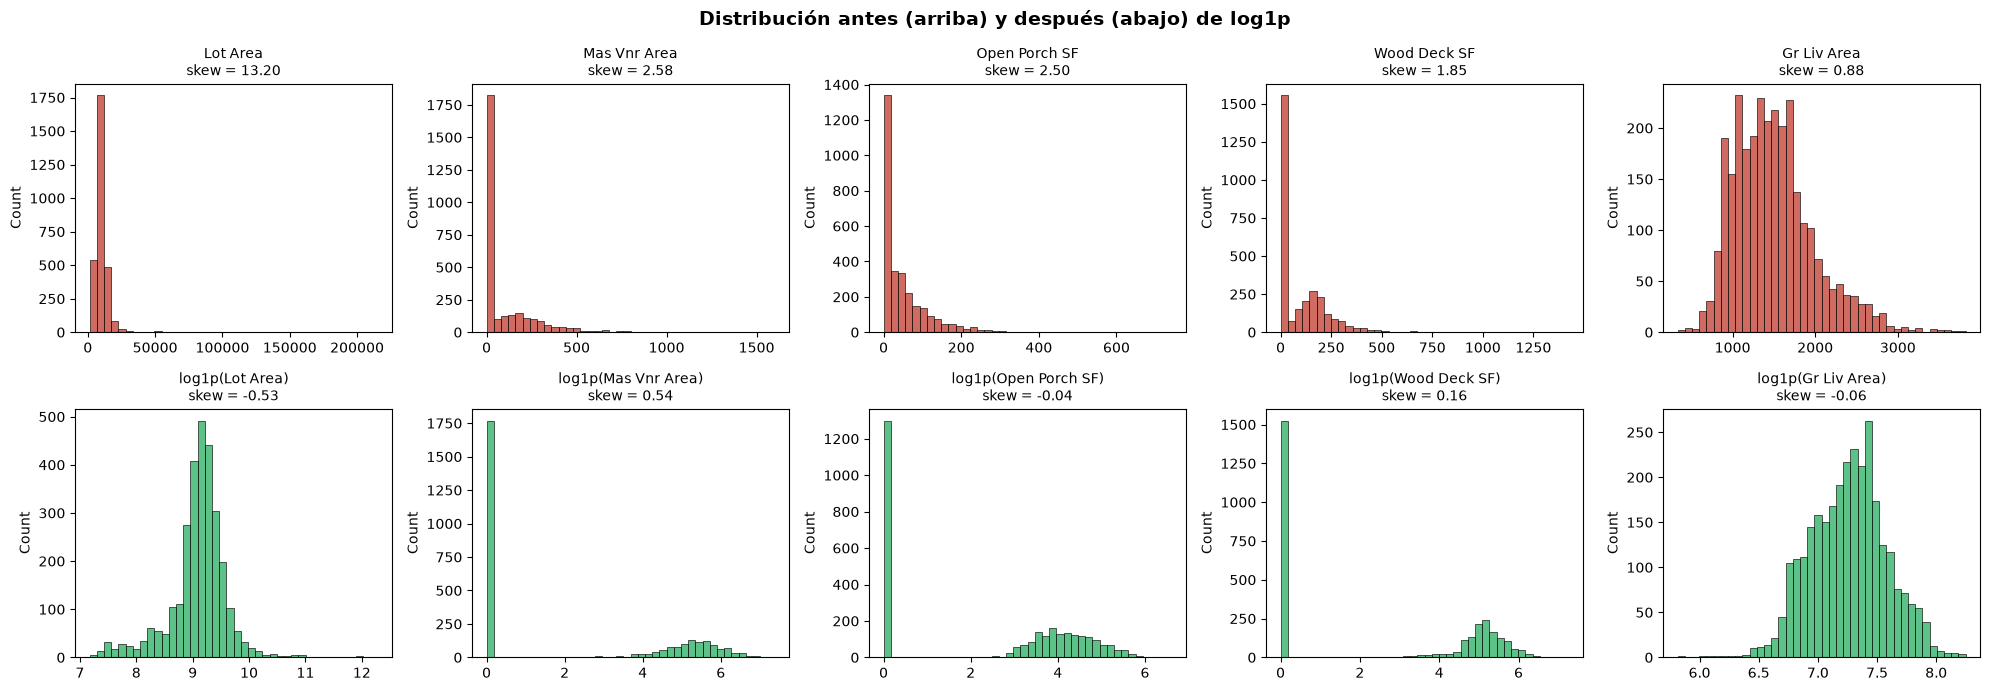

In [13]:
vars_log = ['Lot Area', 'Mas Vnr Area', 'Open Porch SF', 'Wood Deck SF', 'Gr Liv Area']

fig, axes = plt.subplots(2, len(vars_log), figsize=(20, 7))
for i, col in enumerate(vars_log):
    sns.histplot(df_clean[col], ax=axes[0, i], color='#c0392b', bins=40)
    axes[0, i].set_title(f'{col}\nskew = {df_clean[col].skew():.2f}', fontsize=10)
    sns.histplot(np.log1p(df_clean[col]), ax=axes[1, i], color='#27ae60', bins=40)
    axes[1, i].set_title(f'log1p({col})\nskew = {np.log1p(df_clean[col]).skew():.2f}', fontsize=10)
    axes[0, i].set_xlabel(''); axes[1, i].set_xlabel('')
plt.suptitle('Distribución antes (arriba) y después (abajo) de log1p', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.3 Inspección de los casos extremos

¿Los valores extremos son errores de registro o propiedades reales?

In [14]:
print("=== Lotes más grandes (Lot Area) ===")
print(df_clean.nlargest(6, 'Lot Area')[['Lot Area', 'Lot Frontage', 'Gr Liv Area', 'SalePrice',
                                        'Neighborhood', 'Land Contour', 'Sale Condition']].to_string())

print("\n=== Frentes de lote más largos (Lot Frontage) ===")
print(df_clean.nlargest(6, 'Lot Frontage')[['Lot Frontage', 'Lot Area', 'Gr Liv Area', 'SalePrice',
                                            'Neighborhood', 'Lot Config']].to_string())

print("\n=== Precios más bajos (SalePrice) ===")
print(df_clean.nsmallest(6, 'SalePrice')[['SalePrice', 'Gr Liv Area', 'Overall Qual', 'Functional',
                                          'MS Zoning', 'Sale Condition', 'Neighborhood']].to_string())

=== Lotes más grandes (Lot Area) ===
      Lot Area  Lot Frontage  Gr Liv Area  SalePrice Neighborhood Land Contour Sale Condition
956     215245         150.0         2036     375000       Timber          Low         Normal
1569    164660          82.0         1786     228950       Timber          HLS         Normal
2112    159000          80.5         2144     277000      ClearCr          Low         Normal
2068    115149          80.5         1824     302000      ClearCr          Low         Normal
2761     70761          62.0         1533     280000      ClearCr          Low         Normal
314      57200          82.0         1687     160000       Timber          Bnk         Normal

=== Frentes de lote más largos (Lot Frontage) ===
      Lot Frontage  Lot Area  Gr Liv Area  SalePrice Neighborhood Lot Config
1265         313.0     27650         2069     242000        NAmes     Inside
2273         200.0     43500         2034     130000      Mitchel     Inside
1637         195.0     

- Los lotes más grandes son ventas `Normal` en terrenos bajos o con pendiente (`Low`, `HLS`, `Bnk`). Son reales: se tratan con `log1p` y no se eliminan.
- De las 6 ventas más baratas, 5 son `Abnorml`, 3 están en zonas no residenciales y una es una propiedad para demolición (`Functional = Sal`). Ese patrón se revisa a continuación.

In [15]:
zonas_no_residenciales = ['A (agr)', 'C (all)', 'I (all)']

zonificacion = df_clean.groupby('MS Zoning')['SalePrice'].agg(['size', 'median']).sort_values('median')
print("=== Precio por tipo de zonificación ===")
print(zonificacion.to_string())

no_res = df_clean[df_clean['MS Zoning'].isin(zonas_no_residenciales)]
print(f"\nPropiedades en zona no residencial: {len(no_res)}")
print("Barrio de esas propiedades:")
print(no_res['Neighborhood'].value_counts().to_string())

=== Precio por tipo de zonificación ===
           size    median
MS Zoning                
A (agr)       2   47300.0
C (all)      25   78000.0
I (all)       2   80312.5
RM          462  120750.0
RH           27  140000.0
RL         2268  171962.5
FV          139  209000.0

Propiedades en zona no residencial: 29
Barrio de esas propiedades:
Neighborhood
IDOTRR     25
OldTown     2
SWISU       1
Mitchel     1


Hay 29 propiedades en zona comercial, industrial o agrícola, con medianas de 47.300 a 80.313 USD, frente a 120.750 USD en `RM`, la zona residencial más barata. 25 están en `IDOTRR`, el barrio con peor error en la auditoría de equidad de la EP1.

## 3. Encoding determinista (mismo criterio de la EP1)

Para probar los tratamientos con modelos lineales hacen falta variables numéricas. Repetimos los pasos de la EP1 que no aprenden de los datos y por eso pueden ir antes del split: `MS SubClass` a texto, mapeo ordinal manual y one-hot. El target encoding y el escalado van dentro del pipeline.

In [16]:
df_encoded = df_clean.copy()

df_encoded['MS SubClass'] = df_encoded['MS SubClass'].astype(str)

map_calidad = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
cols_calidad = ['Exter Qual', 'Exter Cond', 'Bsmt Qual', 'Bsmt Cond', 'Heating QC',
                'Kitchen Qual', 'Fireplace Qu', 'Garage Qual', 'Garage Cond', 'Pool QC']
for col in cols_calidad:
    df_encoded[col] = df_encoded[col].map(map_calidad)

mapeos = {
    'Bsmt Exposure':  {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4},
    'BsmtFin Type 1': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'BsmtFin Type 2': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'Garage Finish':  {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3},
    'Functional':     {'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3, 'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7},
    'Fence':          {'None': 0, 'MnWw': 1, 'GdWo': 2, 'MnPrv': 3, 'GdPrv': 4},
    'Paved Drive':    {'N': 0, 'P': 1, 'Y': 2},
    'Lot Shape':      {'IR3': 0, 'IR2': 1, 'IR1': 2, 'Reg': 3},
    'Land Slope':     {'Sev': 0, 'Mod': 1, 'Gtl': 2},
    'Utilities':      {'ELO': 0, 'NoSeWa': 1, 'NoSewr': 2, 'AllPub': 3},
}
for col, mapa in mapeos.items():
    df_encoded[col] = df_encoded[col].map(mapa)

cols_ordinales = cols_calidad + list(mapeos.keys())
print(f"NaN tras el mapeo ordinal (debe ser 0): {df_encoded[cols_ordinales].isnull().sum().sum()}")

nominales_baja_card = ['MS SubClass', 'MS Zoning', 'Street', 'Alley', 'Land Contour',
                       'Lot Config', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl',
                       'Mas Vnr Type', 'Foundation', 'Heating', 'Central Air', 'Electrical',
                       'Garage Type', 'Misc Feature', 'Sale Type', 'Sale Condition',
                       'Condition 1', 'Condition 2']
df_encoded = pd.get_dummies(df_encoded, columns=nominales_baja_card, drop_first=True, dtype=int)

y = df_encoded['SalePrice']
X = df_encoded.drop(columns=['SalePrice'])
print(f"X: {X.shape} | y: {y.shape}")

NaN tras el mapeo ordinal (debe ser 0): 0
X: (2925, 169) | y: (2925,)


In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")

X_train: (2340, 169) | X_test: (585, 169)


## 4. Efecto de cada tratamiento en Ridge y Lasso (validación cruzada)

Cuatro variantes, validación cruzada de 5 folds solo sobre train. Todo lo que aprende de los datos (target encoding, escalado, recorte) va dentro del `Pipeline` y se ajusta de nuevo en cada fold. `TransformedTargetRegressor` entrena sobre `log1p(SalePrice)` y devuelve dólares.

| Variante | Tratamiento |
|---|---|
| A | Como en la EP1: `RobustScaler` + `StandardScaler` |
| B | A + `log1p` en las 5 variables con cola larga |
| C | B + recorte al percentil 99 de las 5 superficies sin `log1p` (`Lot Frontage`, `BsmtFin SF 1`, `Bsmt Unf SF`, `Total Bsmt SF`, `2nd Flr SF`) |
| D | C + excluir propiedades en zona no residencial |

In [18]:
cols_target_enc = ['Neighborhood', 'Exterior 1st', 'Exterior 2nd']

cols_robust = ['Lot Frontage', 'Lot Area', 'Mas Vnr Area', 'BsmtFin SF 1', 'Bsmt Unf SF',
               'Total Bsmt SF', '2nd Flr SF', 'Gr Liv Area', 'Wood Deck SF', 'Open Porch SF']

cols_standard = ['Year Built', 'Year Remod/Add', 'Overall Qual', 'Overall Cond',
                 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath',
                 'Bedroom AbvGr', 'Kitchen AbvGr', 'Fireplaces', 'Garage Cars',
                 'Mo Sold', 'Yr Sold', 'BsmtFin SF 2', 'Low Qual Fin SF', 'Enclosed Porch',
                 '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val']


class RecortePercentil(BaseEstimator, TransformerMixin):
    """Recorta cada columna en su percentil q, calculado solo con los datos de entrenamiento."""
    def __init__(self, q=0.99):
        self.q = q
    def fit(self, X, y=None):
        self.limite_ = np.quantile(np.asarray(X, dtype=float), self.q, axis=0)
        return self
    def transform(self, X):
        return np.minimum(np.asarray(X, dtype=float), self.limite_)


def construir_modelo(variante, regresor):
    if variante == 'A':
        transformadores = [('robust', RobustScaler(), cols_robust)]
    else:
        resto_robust = [c for c in cols_robust if c not in vars_log]
        rama_log = Pipeline([('log', FunctionTransformer(np.log1p)), ('scaler', StandardScaler())])
        rama_robust = (Pipeline([('recorte', RecortePercentil(0.99)), ('scaler', RobustScaler())])
                       if variante in ('C', 'D') else RobustScaler())
        transformadores = [('log', rama_log, vars_log), ('robust', rama_robust, resto_robust)]

    transformadores += [
        ('standard', StandardScaler(), cols_standard),
        ('target', Pipeline([('te', TargetEncoder(target_type='continuous', random_state=RANDOM_STATE)),
                             ('scaler', StandardScaler())]), cols_target_enc),
    ]
    preprocesador = ColumnTransformer(transformadores, remainder='passthrough')
    return TransformedTargetRegressor(
        regressor=Pipeline([('pre', preprocesador), ('modelo', regresor)]),
        func=np.log1p, inverse_func=np.expm1)

In [19]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metricas = {'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error',
            'mape': 'neg_mean_absolute_percentage_error', 'r2': 'r2'}

es_residencial = ~df_clean.loc[X_train.index, 'MS Zoning'].isin(zonas_no_residenciales)

regresores = {
    'Ridge': RidgeCV(alphas=np.logspace(-2, 3, 30)),
    'Lasso': LassoCV(alphas=np.logspace(-5, -1, 30), max_iter=50000, random_state=RANDOM_STATE),
}

filas = []
for nombre, regresor in regresores.items():
    for variante in ['A', 'B', 'C', 'D']:
        X_v, y_v = (X_train[es_residencial], y_train[es_residencial]) if variante == 'D' else (X_train, y_train)
        res = cross_validate(construir_modelo(variante, regresor), X_v, y_v,
                             cv=cv, scoring=metricas, return_train_score=True)
        filas.append({
            'Modelo': nombre, 'Variante': variante, 'n': len(y_v),
            'RMSE': -res['test_rmse'].mean(),
            'Desv. RMSE entre folds': res['test_rmse'].std(),
            'MAE': -res['test_mae'].mean(),
            'MAPE %': -res['test_mape'].mean() * 100,
            'R² (val)': res['test_r2'].mean(),
            'R² (train)': res['train_r2'].mean(),
        })

resultados_outliers = pd.DataFrame(filas)
print(resultados_outliers.round(3).to_string(index=False))

Modelo Variante    n      RMSE  Desv. RMSE entre folds       MAE  MAPE %  R² (val)  R² (train)
 Ridge        A 2340 20438.843                1866.384 14044.156   8.542     0.929       0.940
 Ridge        B 2340 20334.964                1780.321 13949.853   8.430     0.930       0.939
 Ridge        C 2340 20598.640                1759.474 14028.192   8.452     0.928       0.938
 Ridge        D 2314 20503.814                1058.003 13842.291   8.085     0.928       0.938
 Lasso        A 2340 20545.911                1655.201 14139.810   8.592     0.929       0.937
 Lasso        B 2340 20625.243                1687.141 14111.175   8.503     0.928       0.936
 Lasso        C 2340 20907.225                1668.130 14213.309   8.535     0.926       0.934
 Lasso        D 2314 20687.004                1185.798 13946.129   8.123     0.926       0.936


- B baja el MAPE de los dos modelos en unos 0,1 puntos. El RMSE baja unos 100 USD en Ridge y sube unos 80 en Lasso, menos que la variación entre folds. Adoptamos B porque corrige la asimetría sin empeorar el modelo.
- C sube el RMSE de los dos en unos 270 USD respecto de B: se descarta.
- D baja el MAPE de 8,5 a 8,1 % y la desviación entre folds entre un 29 % y un 40 % respecto de C. Pero parte de esa mejora es que las casas difíciles dejan de evaluarse, así que D no es comparable con las demás.

### 4.1 ¿Escalar también las columnas ordinales?

En A a D las ordinales (calidades de 0 a 5, `Functional` de 0 a 7) y las binarias pasan sin escalar. Ridge y Lasso penalizan todos los coeficientes por igual, así que la escala de una variable cambia cuánto se la penaliza. Comparamos B con E = B + `StandardScaler` en las ordinales.

In [20]:
def construir_modelo_e(regresor):
    resto_robust = [c for c in cols_robust if c not in vars_log]
    preprocesador = ColumnTransformer([
        ('log', Pipeline([('log', FunctionTransformer(np.log1p)), ('scaler', StandardScaler())]), vars_log),
        ('robust', RobustScaler(), resto_robust),
        ('standard', StandardScaler(), cols_standard + cols_ordinales),
        ('target', Pipeline([('te', TargetEncoder(target_type='continuous', random_state=RANDOM_STATE)),
                             ('scaler', StandardScaler())]), cols_target_enc),
    ], remainder='passthrough')
    return TransformedTargetRegressor(
        regressor=Pipeline([('pre', preprocesador), ('modelo', regresor)]),
        func=np.log1p, inverse_func=np.expm1)


def resumir_cv(res, **etiquetas):
    fila = dict(etiquetas)
    fila.update({'RMSE': -res['test_rmse'].mean(),
                 'Desv. RMSE entre folds': res['test_rmse'].std(),
                 'MAE': -res['test_mae'].mean(),
                 'MAPE %': -res['test_mape'].mean() * 100,
                 'R² (val)': res['test_r2'].mean()})
    if 'train_r2' in res:
        fila['R² (train)'] = res['train_r2'].mean()
    return fila


filas = []
for nombre, regresor in regresores.items():
    for variante, modelo in [('B', construir_modelo('B', regresor)), ('E', construir_modelo_e(regresor))]:
        res = cross_validate(modelo, X_train, y_train, cv=cv, scoring=metricas, return_train_score=True)
        filas.append(resumir_cv(res, Modelo=nombre, Variante=variante))

print(pd.DataFrame(filas).round(3).to_string(index=False))

Modelo Variante      RMSE  Desv. RMSE entre folds       MAE  MAPE %  R² (val)  R² (train)
 Ridge        B 20334.964                1780.321 13949.853   8.430     0.930       0.939
 Ridge        E 20352.351                1795.359 13951.673   8.430     0.930       0.939
 Lasso        B 20625.243                1687.141 14111.175   8.503     0.928       0.936
 Lasso        E 20629.986                1701.002 14112.839   8.501     0.928       0.936


- E rinde igual que B: menos de 20 USD de diferencia. Con los `alpha` que eligen `RidgeCV` y `LassoCV` la penalización es chica y la escala casi no influye.
- Adoptamos E igual: deja todas las variables en la misma escala frente a la penalización (importaría si una búsqueda probara `alpha` grandes) y hace comparables los coeficientes.

## 5. ¿Qué casas predice peor el modelo?

Los outliers que importan para un modelo son las casas que predice mal, no necesariamente los valores extremos de X. Con `cross_val_predict` (Ridge, variante B) vemos dónde se concentra el error.

In [21]:
pred_cv = cross_val_predict(construir_modelo('B', RidgeCV(alphas=np.logspace(-2, 3, 30))),
                            X_train, y_train, cv=cv)

residuos = pd.DataFrame({'Real': y_train, 'Predicho': pred_cv.round(0)})
residuos['Error %'] = (np.abs(residuos['Real'] - residuos['Predicho']) / residuos['Real'] * 100).round(1)
residuos = residuos.join(df_clean[['MS Zoning', 'Sale Condition', 'Neighborhood',
                                   'Overall Qual', 'Gr Liv Area', 'Functional']])

print("=== Las 15 casas con mayor error porcentual ===")
print(residuos.sort_values('Error %', ascending=False).head(15).to_string())

=== Las 15 casas con mayor error porcentual ===
        Real  Predicho  Error % MS Zoning Sale Condition Neighborhood  Overall Qual  Gr Liv Area Functional
181    12789   62554.0    389.1        RM        Abnorml      OldTown             2          832        Typ
1552   13100   42406.0    223.7   A (agr)        Abnorml       IDOTRR             1          733        Sal
372    82500  187846.0    127.7        RL         Family       NWAmes             7         1411        Typ
1554   40000   84493.0    111.2   C (all)         Normal       IDOTRR             4         1317        Typ
1182  150000  301392.0    100.9        RL         Family      Veenker             9         2944        Typ
726    34900   66651.0     91.0   C (all)        Abnorml       IDOTRR             4          720        Typ
125    84900  161576.0     90.3        RL        Abnorml        NAmes             5         1728        Typ
561    62383  116644.0     87.0        RL         Normal       Sawyer             5     

In [22]:
print("=== MAPE por condición de venta ===")
print(residuos.groupby('Sale Condition')['Error %'].agg(n='size', MAPE='mean')
      .sort_values('MAPE').round(1).to_string())

print("\n=== MAPE según zonificación ===")
print(residuos.groupby(residuos['MS Zoning'].isin(zonas_no_residenciales)
                       .map({False: 'Residencial', True: 'No residencial'}))['Error %']
      .agg(n='size', MAPE='mean').round(1).to_string())

=== MAPE por condición de venta ===
                   n  MAPE
Sale Condition            
Normal          1927   7.2
Partial          187   8.9
AdjLand           10  13.3
Family            41  16.5
Alloca            20  17.2
Abnorml          155  19.1

=== MAPE según zonificación ===
                   n  MAPE
MS Zoning                 
No residencial    26  33.6
Residencial     2314   8.1


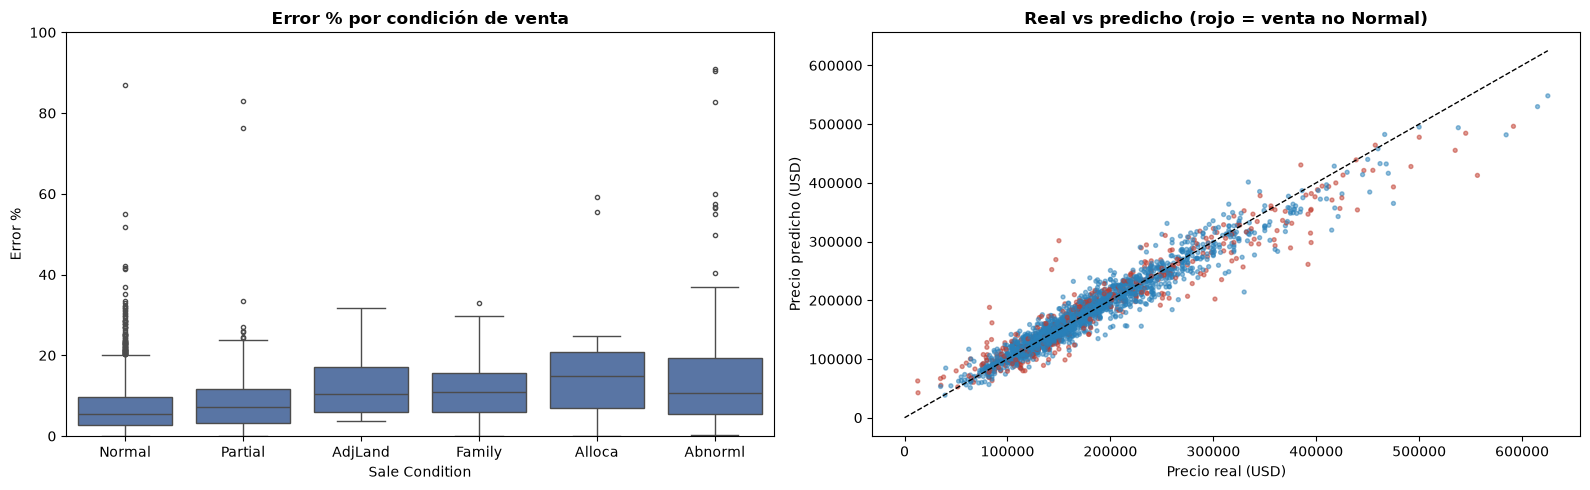

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

orden = residuos.groupby('Sale Condition')['Error %'].mean().sort_values().index
sns.boxplot(data=residuos, x='Sale Condition', y='Error %', order=orden, ax=axes[0],
            color='#4C72B0', fliersize=3)
axes[0].set_ylim(0, 100)
axes[0].set_title('Error % por condición de venta', fontweight='bold')

axes[1].scatter(residuos['Real'], residuos['Predicho'], s=8, alpha=0.5,
                c=residuos['Sale Condition'].eq('Normal').map({True: '#2980b9', False: '#c0392b'}))
lim = [0, residuos[['Real', 'Predicho']].max().max()]
axes[1].plot(lim, lim, 'k--', lw=1)
axes[1].set_xlabel('Precio real (USD)'); axes[1].set_ylabel('Precio predicho (USD)')
axes[1].set_title('Real vs predicho (rojo = venta no Normal)', fontweight='bold')

plt.tight_layout()
plt.show()

## 6. Conclusiones y decisiones sobre outliers para Ridge y Lasso

1. No se eliminan filas por IQR ni por z-score. El 7,9 % que marcan los dos métodos son propiedades reales, y en `Mas Vnr Area` y `Open Porch SF` el IQR exagera por los ceros.
2. `log1p` dentro del pipeline para `Lot Area`, `Gr Liv Area`, `Mas Vnr Area`, `Wood Deck SF` y `Open Porch SF`; el resto de las superficies con `RobustScaler`.
3. No se recorta nada: el recorte al percentil 99 subió el RMSE en unos 270 USD (variante C).
4. Ordinales con `StandardScaler` (variante E).
5. Zonas no residenciales (29 propiedades): queda pendiente. Que el MAPE baje al sacarlas es esperable, porque son las más difíciles y dejan de evaluarse. La pregunta real es si entrenar con ellas empeora a las residenciales, y eso se prueba en la sección 9.
6. Las ventas `Abnorml`, `Alloca` y `Family` se quedan y se reportan como limitación: tienen el mayor error (MAPE de 19,1 %, 17,2 % y 16,5 %, frente a 7,2 % en las `Normal`). No se pueden derivar a tasación manual porque la condición de venta no se conoce antes de vender. Las variables de la venta se deciden en la sección 11.
7. Random Forest y XGBoost se analizan en la sección 8; las variables redundantes y casi constantes, en la 10.

## 7. Preparación común: poblaciones, split y transformadores

### 7.1 Poblaciones y split

Usamos el mismo split de la sección 3. El EDA descriptivo de las secciones 2 y 10.1 se calculó sobre todo el dataset, pero todas las comparaciones de modelos usan solo train y el test no entra en ningún ajuste. Hay dos versiones de train:

- `X_train_todo`: todas las casas. `A (agr)`, `C (all)` e `I (all)` se agrupan como `No residencial`, porque `A (agr)` e `I (all)` tienen 2 casas cada una.
- `X_train_res`: solo residenciales, la población de la sección 8.

In [24]:
df_clean.index.name = 'id'   # se conserva para rastrear cada casa hasta ames_clean.csv

df_todo = df_clean.copy()
df_todo['MS Zoning'] = df_todo['MS Zoning'].replace({z: 'No residencial' for z in zonas_no_residenciales})
es_residencial_todo = ~df_clean['MS Zoning'].isin(zonas_no_residenciales)

X_todo = df_todo.drop(columns=['SalePrice'])
y_todo = df_todo['SalePrice']

X_train_todo, y_train_todo = X_todo.loc[X_train.index], y_todo.loc[X_train.index]
X_test_todo, y_test_todo = X_todo.loc[X_test.index], y_todo.loc[X_test.index]
res_train = es_residencial_todo.loc[X_train.index]
res_test = es_residencial_todo.loc[X_test.index]

X_train_res, y_train_res = X_train_todo[res_train], y_train_todo[res_train]

print(f"Train todas: {X_train_todo.shape} ({(~res_train).sum()} no residenciales) | "
      f"Test todas: {X_test_todo.shape} ({(~res_test).sum()} no residenciales)")
print(f"Train solo residenciales: {X_train_res.shape}")
print(X_train_todo['MS Zoning'].value_counts().to_string())

Train todas: (2340, 79) (26 no residenciales) | Test todas: (585, 79) (3 no residenciales)
Train solo residenciales: (2314, 79)
MS Zoning
RL                1809
RM                 373
FV                 107
No residencial      26
RH                  25


### 7.2 Grupos de columnas

Reutilizamos las listas de la sección 3 y completamos las que faltan. El control del final comprueba que cada predictor está en un solo grupo. `COLS_LIMPIEZA` son las columnas candidatas a quitar en la sección 10.

In [25]:
mapeos_ordinales = {**{col: map_calidad for col in cols_calidad}, **mapeos}

cols_robust_sin_log = [c for c in cols_robust if c not in vars_log]
cols_binarias = ['Tiene_Piscina', 'Tiene_Sotano', 'Tiene_Garage', 'Tiene_Chimenea']
cols_nominales = nominales_baja_card + cols_target_enc
cols_numericas = vars_log + cols_robust_sin_log + cols_standard

grupos = cols_ordinales + cols_nominales + cols_numericas + cols_binarias
assert len(grupos) == len(set(grupos)), "Hay columnas repetidas entre grupos"
assert set(grupos) == set(X_todo.columns), set(X_todo.columns) ^ set(grupos)
print(f"Predictores: {len(grupos)} = {len(cols_ordinales)} ordinales + {len(cols_nominales)} nominales "
      f"({len(nominales_baja_card)} de baja cardinalidad, {len(cols_target_enc)} de alta) "
      f"+ {len(cols_numericas)} numéricas + {len(cols_binarias)} binarias")

COLS_LIMPIEZA = ['Utilities', 'Street', 'Pool QC', 'Pool Area', 'BsmtFin SF 2']
MIN_FRECUENCIA = 10   # categorías con menos casas en train se agrupan en "infrecuente"


def filtrar(cols, limpieza, quitar=()):
    return [c for c in cols if not (limpieza and c in COLS_LIMPIEZA) and c not in quitar]

Predictores: 79 = 20 ordinales + 24 nominales (21 de baja cardinalidad, 3 de alta) + 31 numéricas + 4 binarias


### 7.3 Transformadores y preprocesadores

- `MapeoOrdinal`: los pasos deterministas de la sección 3, pero dentro del pipeline, para que una casa nueva reciba exactamente la misma preparación.
- `ACategoria`: para la codificación nativa de XGBoost (sección 8). Aprende las categorías en train y deja como `NaN` una categoría que solo aparezca en test.
- `construir_pre_lineal` y `construir_pre_arbol`: preprocesadores de los lineales y de los árboles. `limpieza` activa el paquete de la sección 10 y `quitar` saca columnas adicionales (sección 11).

In [26]:
class MapeoOrdinal(BaseEstimator, TransformerMixin):
    def __init__(self, mapeos):
        self.mapeos = mapeos
    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self
    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_
    def transform(self, X):
        X = X.copy()
        X['MS SubClass'] = X['MS SubClass'].astype(str)
        for col, mapa in self.mapeos.items():
            X[col] = X[col].map(mapa)
        if X[list(self.mapeos)].isnull().any().any():
            raise ValueError("Hay valores ordinales que no están en los mapeos")
        return X


class ACategoria(BaseEstimator, TransformerMixin):
    def __init__(self, cols):
        self.cols = cols
    def fit(self, X, y=None):
        self.categorias_ = {c: sorted(X[c].astype(str).unique()) for c in self.cols}
        return self
    def transform(self, X):
        X = X.copy()
        for c in self.cols:
            valores = X[c].astype(str)
            valores = valores.where(valores.isin(self.categorias_[c]))   # no vistas en train -> NaN
            X[c] = valores.astype(CategoricalDtype(self.categorias_[c]))
        return X


def codificador(tipo, min_frecuencia=None, drop=None):
    if tipo == 'ordinal':
        return OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1,
                              min_frequency=min_frecuencia, dtype=int)
    if tipo == 'onehot':
        return OneHotEncoder(drop=drop, min_frequency=min_frecuencia, sparse_output=False, dtype=int,
                             handle_unknown='infrequent_if_exist' if min_frecuencia else 'ignore')
    if tipo == 'target':
        return TargetEncoder(target_type='continuous', random_state=RANDOM_STATE)
    raise ValueError(tipo)


def construir_pre_lineal(limpieza=False, quitar=()):
    min_frec = MIN_FRECUENCIA if limpieza else None
    columnas = ColumnTransformer([
        ('log', Pipeline([('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                          ('scaler', StandardScaler())]), vars_log),
        ('robust', RobustScaler(), cols_robust_sin_log),
        ('standard', StandardScaler(), filtrar(cols_standard + cols_ordinales, limpieza, quitar)),
        ('target', Pipeline([('te', codificador('target')), ('scaler', StandardScaler())]), cols_target_enc),
        ('onehot', codificador('onehot', min_frec, drop='first'), filtrar(nominales_baja_card, limpieza, quitar)),
        ('binarias', 'passthrough', cols_binarias),
    ], remainder='drop', verbose_feature_names_out=False)
    return Pipeline([('mapeo', MapeoOrdinal(mapeos_ordinales)), ('columnas', columnas)]).set_output(transform='pandas')


def construir_pre_arbol(baja, alta, limpieza=False, quitar=()):
    min_frec = MIN_FRECUENCIA if limpieza else None
    columnas = ColumnTransformer([
        ('baja', codificador(baja, min_frec), filtrar(nominales_baja_card, limpieza, quitar)),
        ('alta', codificador(alta, min_frec), cols_target_enc),
        ('numericas', 'passthrough', filtrar(cols_numericas + cols_ordinales + cols_binarias, limpieza, quitar)),
    ], remainder='drop', verbose_feature_names_out=False)
    return Pipeline([('mapeo', MapeoOrdinal(mapeos_ordinales)), ('columnas', columnas)]).set_output(transform='pandas')


def construir_pre_xgb():
    return Pipeline([('mapeo', MapeoOrdinal(mapeos_ordinales)), ('categorias', ACategoria(cols_nominales))])


def con_log(regresor):
    return TransformedTargetRegressor(regressor=regresor, func=np.log1p, inverse_func=np.expm1)


def nuevo_rf():
    return RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)


def nuevo_xgb(**kw):
    return XGBRegressor(tree_method='hist', n_estimators=500, learning_rate=0.05,
                        random_state=RANDOM_STATE, **kw)

## 8. ¿Qué necesitan Random Forest y XGBoost?

Lo comprobamos con validación cruzada (mismos 5 folds, solo train residencial, preparación dentro del pipeline) en vez de suponerlo. Los parámetros son los iniciales de la sección 21: aquí se decide la preparación, no se ajustan los modelos.

### 8.1 ¿Les afecta el `log1p` o la escala de X?

Un árbol solo usa el orden de los valores para cortar, así que una transformación monótona como `log1p` o el escalado debería dar el mismo modelo. Entrenamos cada modelo con y sin `log1p` en las 5 variables de cola larga.

In [27]:
X_train_log = X_train_res.copy()
X_train_log[vars_log] = np.log1p(X_train_log[vars_log])

pruebas_log = {
    'Random Forest': lambda: Pipeline([('pre', construir_pre_arbol('ordinal', 'target')), ('modelo', nuevo_rf())]),
    'XGBoost': lambda: Pipeline([('pre', construir_pre_xgb()), ('modelo', nuevo_xgb(enable_categorical=True))]),
}

filas = []
for nombre, modelo in pruebas_log.items():
    for etiqueta, X_v in [('Sin log1p', X_train_res), ('Con log1p', X_train_log)]:
        res = cross_validate(con_log(modelo()), X_v, y_train_res, cv=cv, scoring=metricas)
        filas.append(resumir_cv(res, Modelo=nombre, X=etiqueta))
print(pd.DataFrame(filas).round(3).to_string(index=False))

       Modelo         X      RMSE  Desv. RMSE entre folds       MAE  MAPE %  R² (val)
Random Forest Sin log1p 25133.979                2503.374 15809.211   9.235     0.891
Random Forest Con log1p 25130.880                2503.872 15804.186   9.237     0.891
      XGBoost Sin log1p 23084.992                1753.869 14495.938   8.467     0.909
      XGBoost Con log1p 23084.992                1753.869 14495.938   8.467     0.909


- Random Forest cambia 3 USD de RMSE, ruido por la posición de los umbrales. XGBoost da lo mismo al dólar.
- Los árboles no necesitan `log1p` ni escalado. Por la misma razón, los valores extremos de X no les afectan y no se recortan.

### 8.2 Codificación de las nominales en Random Forest

Random Forest de scikit-learn necesita entrada numérica. Cuatro opciones:

| Opción | Baja cardinalidad (21) | Alta cardinalidad (`Neighborhood`, `Exterior 1st/2nd`) |
|---|---|---|
| 1 | Ordinal | Ordinal |
| 2 | One-hot | One-hot |
| 3 | One-hot | Target encoding |
| 4 | Ordinal | Target encoding |

In [28]:
opciones_rf = {1: ('ordinal', 'ordinal'), 2: ('onehot', 'onehot'),
               3: ('onehot', 'target'), 4: ('ordinal', 'target')}

filas = []
for opcion, (baja, alta) in opciones_rf.items():
    n_cols = construir_pre_arbol(baja, alta).fit_transform(X_train_res, np.log1p(y_train_res)).shape[1]
    modelo = con_log(Pipeline([('pre', construir_pre_arbol(baja, alta)), ('modelo', nuevo_rf())]))
    res = cross_validate(modelo, X_train_res, y_train_res, cv=cv, scoring=metricas)
    filas.append(resumir_cv(res, Opción=opcion, Baja=baja, Alta=alta, Columnas=n_cols))

print(pd.DataFrame(filas).round(3).to_string(index=False))

 Opción    Baja    Alta  Columnas      RMSE  Desv. RMSE entre folds       MAE  MAPE %  R² (val)
      1 ordinal ordinal        79 25133.750                2571.216 15871.702   9.280     0.891
      2  onehot  onehot       241 25116.362                2517.717 15822.795   9.247     0.892
      3  onehot  target       185 25095.713                2523.933 15785.854   9.208     0.892
      4 ordinal  target        79 25133.979                2503.374 15809.211   9.235     0.891


- Las cuatro quedan a menos de 100 USD de RMSE entre sí, con una desviación entre folds de unos 2.500 USD: en Random Forest la codificación casi no importa.
- La 2 tiene el menor RMSE y la 3 el menor MAPE, siempre por muy poco. Elegimos la 3 porque es la misma de XGBoost (sección 8.3) y usa 185 columnas en vez de 241.
- La 4 rinde igual con 79 columnas y deja la importancia de cada variable en una sola columna. Es la alternativa si se prioriza interpretar.

### 8.3 Codificación de las nominales en XGBoost

XGBoost puede usar columnas `category` directamente (`enable_categorical=True`): en cada corte reparte las categorías en dos lados. Lo comparamos con las dos codificaciones con target encoding de la sección 8.2.

In [29]:
pruebas_xgb = {
    'Nativa (category)': Pipeline([('pre', construir_pre_xgb()),
                                   ('modelo', nuevo_xgb(enable_categorical=True))]),
    'Ordinal + target': Pipeline([('pre', construir_pre_arbol('ordinal', 'target')), ('modelo', nuevo_xgb())]),
    'One-hot + target': Pipeline([('pre', construir_pre_arbol('onehot', 'target')), ('modelo', nuevo_xgb())]),
}

filas = []
for nombre, modelo in pruebas_xgb.items():
    res = cross_validate(con_log(modelo), X_train_res, y_train_res, cv=cv, scoring=metricas)
    filas.append(resumir_cv(res, Codificación=nombre))
print(pd.DataFrame(filas).round(3).to_string(index=False))

     Codificación      RMSE  Desv. RMSE entre folds       MAE  MAPE %  R² (val)
Nativa (category) 23084.992                1753.869 14495.938   8.467     0.909
 Ordinal + target 22688.587                1430.975 14429.094   8.455     0.912
 One-hot + target 22411.845                1324.377 14378.209   8.446     0.914


- La codificación nativa no es la mejor con estos parámetros: one-hot + target baja el RMSE en unos 670 USD (2,9 %) y es más estable entre folds (desviación de 1.324 frente a 1.754). MAE y MAPE casi no cambian.
- Una explicación posible: con `Neighborhood` como `category`, cada corte busca la mejor partición de 28 barrios con pocas casas cada uno, y eso tiende a sobreajustar. El target encoding resume el barrio en un solo valor ordenado por precio.
- Adoptamos one-hot + target. Como la diferencia es chica, la opción nativa se podría volver a comparar en una búsqueda de hiperparámetros (sección 18).

## 9. Zonas no residenciales: ¿entrenar con ellas empeora las residenciales?

Comparar el MAPE con y sin estas casas (variante D) no responde la pregunta, porque al sacarlas también se dejan de evaluar. La prueba es otra: en cada fold entrenamos un modelo con todas las casas y otro solo con las residenciales, y evaluamos los dos sobre las mismas casas residenciales de validación. Usamos los cuatro modelos con la preparación elegida hasta aquí y la zona agrupada como `No residencial`.

Criterio, escrito antes de ver los resultados: las no residenciales empeoran a un modelo si el RMSE sobre residenciales sube en promedio y en al menos 4 de los 5 folds. Se excluyen si eso pasa en la mayoría de los modelos. Si no empeoran, se conservan, con métricas aparte y la recomendación de tasarlas a mano.

La decisión queda fija en el código (`EXCLUIR_NO_RESIDENCIAL`), igual que las de las secciones 10.2 y 11. La prueba se recalcula en cada ejecución y avisa si en otro entorno da otro resultado, para que una diferencia de pocos dólares entre versiones no cambie la preparación sin que nadie lo note.

In [30]:
modelos_finales = {
    'Ridge': lambda limpieza=False, quitar=(): con_log(Pipeline([('pre', construir_pre_lineal(limpieza, quitar)),
                                                      ('modelo', RidgeCV(alphas=np.logspace(-2, 3, 30)))])),
    'Lasso': lambda limpieza=False, quitar=(): con_log(Pipeline([('pre', construir_pre_lineal(limpieza, quitar)),
                                                      ('modelo', LassoCV(alphas=np.logspace(-5, -1, 30), max_iter=50000,
                                                                         random_state=RANDOM_STATE))])),
    'Random Forest': lambda limpieza=False, quitar=(): con_log(Pipeline([('pre', construir_pre_arbol('onehot', 'target', limpieza, quitar)),
                                                              ('modelo', nuevo_rf())])),
    'XGBoost': lambda limpieza=False, quitar=(): con_log(Pipeline([('pre', construir_pre_arbol('onehot', 'target', limpieza, quitar)),
                                                        ('modelo', nuevo_xgb())])),
}


def metricas_dolares(real, pred):
    return {'RMSE': root_mean_squared_error(real, pred), 'MAE': mean_absolute_error(real, pred),
            'MAPE %': mean_absolute_percentage_error(real, pred) * 100}


def revisar_decision(nombre, segun_prueba, decision):
    print(f"{nombre}: según la prueba = {segun_prueba} | decisión fija = {decision}")
    if segun_prueba != decision:
        print(f"  Aviso: en este entorno la prueba no coincide con la decisión fija de {nombre}; revisar la tabla.")


predicciones = []
for nombre, construir in modelos_finales.items():
    for fold, (tr, va) in enumerate(cv.split(X_train_todo)):
        ids_tr, ids_va = X_train_todo.index[tr], X_train_todo.index[va]
        entrenamientos = {'Con no residenciales': ids_tr,
                          'Solo residenciales': ids_tr[res_train.loc[ids_tr].values]}
        for entrenamiento, ids in entrenamientos.items():
            modelo = construir().fit(X_train_todo.loc[ids], y_train_todo.loc[ids])
            predicciones.append(pd.DataFrame({
                'Modelo': nombre, 'Entrenamiento': entrenamiento, 'Fold': fold,
                'Real': y_train_todo.loc[ids_va], 'Predicho': modelo.predict(X_train_todo.loc[ids_va]),
                'Residencial': res_train.loc[ids_va]}))

predicciones = pd.concat(predicciones)
print(f"Predicciones fuera de muestra: {len(predicciones)} "
      f"({len(modelos_finales)} modelos x 2 entrenamientos x {len(X_train_todo)} casas)")

Predicciones fuera de muestra: 18720 (4 modelos x 2 entrenamientos x 2340 casas)


In [31]:
pred_res = predicciones[predicciones['Residencial']]

rmse_fold = (pred_res.groupby(['Modelo', 'Entrenamiento', 'Fold'])[['Real', 'Predicho']]
             .apply(lambda g: root_mean_squared_error(g['Real'], g['Predicho']))
             .unstack('Entrenamiento'))
diferencia = rmse_fold['Con no residenciales'] - rmse_fold['Solo residenciales']

mape = (pred_res.groupby(['Modelo', 'Entrenamiento'])[['Real', 'Predicho']]
        .apply(lambda g: mean_absolute_percentage_error(g['Real'], g['Predicho']) * 100)
        .unstack('Entrenamiento'))

prueba_zonas = pd.DataFrame({
    'RMSE con no res.': rmse_fold['Con no residenciales'].groupby('Modelo').mean(),
    'RMSE solo res.': rmse_fold['Solo residenciales'].groupby('Modelo').mean(),
    'Diferencia RMSE (con − solo)': diferencia.groupby('Modelo').mean(),
    'Folds en que empeora (de 5)': (diferencia > 0).groupby('Modelo').sum(),
    'MAPE % con no res.': mape['Con no residenciales'],
    'MAPE % solo res.': mape['Solo residenciales'],
}).loc[list(modelos_finales)]
prueba_zonas['¿Empeora?'] = ((prueba_zonas['Diferencia RMSE (con − solo)'] > 0)
                             & (prueba_zonas['Folds en que empeora (de 5)'] >= 4))

print("=== Error sobre casas residenciales según con qué se entrenó ===")
print(prueba_zonas.round(2).to_string())

excluir_segun_prueba = bool(prueba_zonas['¿Empeora?'].sum() > len(prueba_zonas) / 2)
print(f"\nModelos que empeoran: {prueba_zonas['¿Empeora?'].sum()} de {len(prueba_zonas)}")

EXCLUIR_NO_RESIDENCIAL = True   # decisión fija, justificada en el texto bajo esta prueba
revisar_decision('EXCLUIR_NO_RESIDENCIAL', excluir_segun_prueba, EXCLUIR_NO_RESIDENCIAL)

=== Error sobre casas residenciales según con qué se entrenó ===
               RMSE con no res.  RMSE solo res.  Diferencia RMSE (con − solo)  Folds en que empeora (de 5)  MAPE % con no res.  MAPE % solo res.  ¿Empeora?
Modelo                                                                                                                                                     
Ridge                  20345.68        20275.03                         70.64                            4                8.18              8.11       True
Lasso                  20727.26        20540.02                        187.24                            4                8.25              8.20       True
Random Forest          24696.54        24829.60                       -133.07                            2                9.09              9.16      False
XGBoost                22317.90        22166.80                        151.10                            4                8.18              8.19       True

In [32]:
pred_nores = predicciones[~predicciones['Residencial']]
error_nores = (pred_nores.groupby(['Modelo', 'Entrenamiento'])[['Real', 'Predicho']]
               .apply(lambda g: pd.Series(metricas_dolares(g['Real'], g['Predicho'])))
               .unstack('Entrenamiento').loc[list(modelos_finales)])

print(f"=== Error sobre casas no residenciales (n = {pred_nores.index.nunique()}) ===")
print(error_nores.round(1).to_string())

=== Error sobre casas no residenciales (n = 26) ===
                              RMSE                                     MAE                                  MAPE %                   
Entrenamiento Con no residenciales Solo residenciales Con no residenciales Solo residenciales Con no residenciales Solo residenciales
Modelo                                                                                                                               
Ridge                      22552.5            23791.4              18422.2            17896.2                 33.7               37.0
Lasso                      23614.3            23450.6              19000.8            17785.5                 34.3               36.5
Random Forest              25437.2            26382.3              19181.4            20627.8                 42.6               43.9
XGBoost                    23832.8            23421.3              18163.8            17119.4                 36.1               38.7


Resultado: las zonas no residenciales se excluyen.

- Entrenar con ellas empeora a las residenciales en 3 de los 4 modelos (Ridge, Lasso y XGBoost), en 4 de 5 folds en cada uno. Random Forest mejora levemente, en 3 de 5 folds.
- El daño es pequeño pero consistente: entre 70 y 190 USD de RMSE (0,3 % a 0,9 %). En MAPE la diferencia es de menos de 0,1 puntos. Las residenciales no ganan nada a cambio.
- Entrenar con ellas tampoco las vuelve tasables: su MAPE queda entre 34 % y 44 % en los dos casos, de 4 a 5 veces el de las residenciales. Con 26 casas en train no hay datos para aprender ese mercado.

El modelo tasa viviendas en zonas residenciales; una propiedad en zona comercial, industrial o agrícola va a tasación manual. La zonificación sirve como criterio de alcance porque se conoce antes de tasar. La condición de venta (`Abnorml`, `Family`) no, porque solo se conoce después de vender, y por eso esas ventas se quedan.

Para el análisis de sesgos: la exclusión saca 25 de las 93 casas de `IDOTRR` (mediana de 75.000 USD, frente a 117.450 USD en las residenciales del barrio). Las 68 residenciales siguen en el modelo, y `segmentos.csv` (sección 17) permite reportar su error por separado.

## 10. Variables redundantes y casi constantes

### 10.1 Diagnóstico

Comprobamos las redundancias con los datos en vez de suponerlas desde la descripción de las variables.

In [33]:
print("=== Identidades exactas (proporción de casas en que se cumplen) ===")
suma_sotano = df_clean['BsmtFin SF 1'] + df_clean['BsmtFin SF 2'] + df_clean['Bsmt Unf SF']
identidades = {
    'Total Bsmt SF = BsmtFin SF 1 + BsmtFin SF 2 + Bsmt Unf SF': np.isclose(suma_sotano, df_clean['Total Bsmt SF']),
    'Tiene_Piscina = (Pool Area > 0)': df_clean['Tiene_Piscina'].eq((df_clean['Pool Area'] > 0).astype(int)),
    'Tiene_Sotano = (Total Bsmt SF > 0)': df_clean['Tiene_Sotano'].eq((df_clean['Total Bsmt SF'] > 0).astype(int)),
    'Tiene_Garage = (Garage Cars > 0)': df_clean['Tiene_Garage'].eq((df_clean['Garage Cars'] > 0).astype(int)),
    'Tiene_Chimenea = (Fireplaces > 0)': df_clean['Tiene_Chimenea'].eq((df_clean['Fireplaces'] > 0).astype(int)),
    "(Pool QC != 'None') = (Pool Area > 0)": df_clean['Pool QC'].ne('None').eq(df_clean['Pool Area'] > 0),
}
for nombre, cumple in identidades.items():
    print(f"  {np.mean(cumple):.3f}  {nombre}")

print("\n=== Pares numéricos más correlacionados ===")
corr = df_clean.select_dtypes('number').drop(columns='SalePrice').corr().abs()
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().sort_values(ascending=False)
print(pares.head(6).round(2).to_string())

print(f"\nBsmtFin SF 2 -> corr. con SalePrice: {df_clean['BsmtFin SF 2'].corr(df_clean['SalePrice']):.3f} "
      f"| casas con 0: {(df_clean['BsmtFin SF 2'] == 0).mean() * 100:.0f} %")

print("\n=== Variables casi constantes ===")
for col in ['Utilities', 'Street', 'Pool QC', 'Condition 2', 'Roof Matl', 'Heating']:
    frec = df_clean[col].value_counts()
    print(f"  {col:12s} moda = {frec.index[0]:8s} ({frec.iloc[0] / len(df_clean) * 100:.1f} %) | "
          f"casas distintas de la moda: {len(df_clean) - frec.iloc[0]:3d} | categorías con < 10 casas: {(frec < 10).sum()}")
print(f"  Pool Area    casas con piscina: {(df_clean['Pool Area'] > 0).sum()}")

=== Identidades exactas (proporción de casas en que se cumplen) ===
  1.000  Total Bsmt SF = BsmtFin SF 1 + BsmtFin SF 2 + Bsmt Unf SF
  1.000  Tiene_Piscina = (Pool Area > 0)
  1.000  Tiene_Sotano = (Total Bsmt SF > 0)
  1.000  Tiene_Garage = (Garage Cars > 0)
  1.000  Tiene_Chimenea = (Fireplaces > 0)
  1.000  (Pool QC != 'None') = (Pool Area > 0)

=== Pares numéricos más correlacionados ===
Pool Area     Tiene_Piscina     0.93
Fireplaces    Tiene_Chimenea    0.90
2nd Flr SF    Gr Liv Area       0.66
BsmtFin SF 1  Bsmt Full Bath    0.65
Gr Liv Area   Full Bath         0.64
2nd Flr SF    Half Bath         0.61

BsmtFin SF 2 -> corr. con SalePrice: 0.008 | casas con 0: 88 %

=== Variables casi constantes ===
  Utilities    moda = AllPub   (99.9 %) | casas distintas de la moda:   3 | categorías con < 10 casas: 2
  Street       moda = Pave     (99.6 %) | casas distintas de la moda:  12 | categorías con < 10 casas: 0
  Pool QC      moda = None     (99.6 %) | casas distintas de la moda:  1

Qué entra al paquete de limpieza:

- Quitar `Utilities` y `Street` (casi todas las casas tienen el mismo valor), `Pool QC` y `Pool Area` (con 11 piscinas no se aprende ni calidad ni tamaño; queda `Tiene_Piscina`) y `BsmtFin SF 2` (correlación de 0,008 con el precio, 88 % de ceros y rompe la identidad exacta del sótano).
- Agrupar las categorías con menos de 10 casas en train (`min_frequency=10`). Las categorías que solo aparecen en test caen en ese grupo en vez de quedar con todas las dummies en 0.

Qué no entra:

- Las variables `Tiene_*` se mantienen. En los lineales capturan el salto entre no tener y tener la característica. En los árboles solo reparten la importancia, y para interpretarlos usaremos importancia por permutación.
- No calculamos el VIF: con dummies e identidades exactas da infinito en varias columnas y no agrega nada a la tabla de identidades.
- No sumamos los porches en uno solo: sería ingeniería de variables nueva.

### 10.2 Prueba del paquete de limpieza

El paquete se evalúa entero contra la preparación actual, con los mismos folds y la población de la sección 9. Criterio, escrito antes: se adopta salvo que empeore el RMSE en promedio y en al menos 4 de 5 folds (en Ridge y Lasso, que comparten conjunto, basta con que empeore uno). Si rinde igual o mejor, se adopta porque deja menos columnas. La decisión queda fija en `LIMPIEZA`.

In [34]:
if EXCLUIR_NO_RESIDENCIAL:
    X_train_base, y_train_base = X_train_res, y_train_res
    X_test_base, y_test_base = X_test_todo[res_test], y_test_todo[res_test]
else:
    X_train_base, y_train_base = X_train_todo, y_train_todo
    X_test_base, y_test_base = X_test_todo, y_test_todo
print(f"Población final -> train: {X_train_base.shape} | test: {X_test_base.shape}")

filas, rmse_variantes = [], {}
for nombre, construir in modelos_finales.items():
    for variante, limpieza in [('Actual', False), ('Limpieza', True)]:
        res = cross_validate(construir(limpieza), X_train_base, y_train_base, cv=cv, scoring=metricas)
        rmse_variantes[(nombre, variante)] = -res['test_rmse']
        filas.append(resumir_cv(res, Modelo=nombre, Variante=variante))
print(pd.DataFrame(filas).round(3).to_string(index=False))

prueba_limpieza = pd.DataFrame({
    nombre: {'Diferencia RMSE (limpieza − actual)':
                 (rmse_variantes[(nombre, 'Limpieza')] - rmse_variantes[(nombre, 'Actual')]).mean(),
             'Folds en que empeora (de 5)':
                 int((rmse_variantes[(nombre, 'Limpieza')] > rmse_variantes[(nombre, 'Actual')]).sum())}
    for nombre in modelos_finales}).T
prueba_limpieza['¿Empeora?'] = ((prueba_limpieza['Diferencia RMSE (limpieza − actual)'] > 0)
                                & (prueba_limpieza['Folds en que empeora (de 5)'] >= 4))
print()
print(prueba_limpieza.round(2).to_string())

limpieza_segun_prueba = {
    'ridge_lasso': not (prueba_limpieza.loc['Ridge', '¿Empeora?'] or prueba_limpieza.loc['Lasso', '¿Empeora?']),
    'random_forest': not prueba_limpieza.loc['Random Forest', '¿Empeora?'],
    'xgboost': not prueba_limpieza.loc['XGBoost', '¿Empeora?'],
}
print()

LIMPIEZA = {'ridge_lasso': True, 'random_forest': True, 'xgboost': True}   # decisión fija, ver el texto bajo esta prueba
revisar_decision('LIMPIEZA', limpieza_segun_prueba, LIMPIEZA)

Población final -> train: (2314, 79) | test: (582, 79)


       Modelo Variante      RMSE  Desv. RMSE entre folds       MAE  MAPE %  R² (val)
        Ridge   Actual 20225.745                1143.233 13769.776   8.078     0.929
        Ridge Limpieza 20159.271                 996.412 13743.744   8.064     0.930
        Lasso   Actual 20419.769                1244.082 13875.607   8.118     0.928
        Lasso Limpieza 20198.985                1032.249 13761.390   8.076     0.930
Random Forest   Actual 25095.713                2523.933 15785.854   9.208     0.892
Random Forest Limpieza 25150.809                2526.795 15793.500   9.215     0.891
      XGBoost   Actual 22411.845                1324.377 14378.209   8.446     0.914
      XGBoost Limpieza 22350.781                1350.357 14309.726   8.393     0.914

               Diferencia RMSE (limpieza − actual)  Folds en que empeora (de 5)  ¿Empeora?
Ridge                                       -66.47                          2.0      False
Lasso                                      -220.78  

Resultado: el paquete no empeora a ningún modelo y se adopta en los tres conjuntos.

- Ridge y Lasso mejoran 66 y 221 USD, y su desviación entre folds baja de unos 1.200 a unos 1.000 USD. En Lasso tiene sentido: las columnas casi constantes y la identidad del sótano lo obligaban a elegir entre variables equivalentes.
- Random Forest y XGBoost quedan igual: +55 y −61 USD, muy por debajo de la variación entre folds. Random Forest empeora en 3 de 5 folds y XGBoost en 2, así que ninguno cumple la condición para rechazarlo.
- Con el mismo rendimiento, preferimos menos columnas: los lineales pasan de 164 a 138 y los árboles de 185 a 158.

## 11. Variables que se conocen solo después de la venta

`Sale Condition` y `Sale Type` son predictores, pero un tasador no sabe de antemano si la venta será un remate o entre familiares, ni con qué escritura se cerrará. Parte sí se conoce antes:

- Se conoce: `Sale Condition = Partial` y `Sale Type = New`, que casi coinciden y marcan una casa recién construida.
- No se conoce: `Abnorml` (remate), `Family`, `Alloca`, `AdjLand` y el tipo de escritura o financiamiento (`COD` es venta por orden judicial; `Con*`, contratos).
- `Yr Sold` y `Mo Sold` se quedan: al tasar se fija `Yr Sold = 2010` (sección 18) y `Mo Sold` toma el mes de la tasación.

Hay dos opciones: (a) quitarlas, o (b) mantenerlas como variable de control y, al tasar, asumir una venta normal (`Normal` / `WD`) solo en lo que no se conoce de antemano. La (b) corresponde a la definición de valor de mercado: el precio en una venta normal entre partes independientes.

Antes de probar preferíamos la (b) por un argumento: si se quitan, el descuento de los remates no desaparece, el modelo se lo atribuye al barrio y las ventas normales de barrios con muchos remates quedan tasadas más bajo. Criterio: se quitan solo si eso mejora el RMSE en promedio y en al menos 4 de 5 folds en la mayoría de los modelos. La decisión queda fija en `QUITAR_VENTA`, y además medimos el sesgo que predice el argumento.

In [35]:
print("=== Sale Type vs Sale Condition (train) ===")
print(pd.crosstab(X_train_base['Sale Type'], X_train_base['Sale Condition']).to_string())

=== Sale Type vs Sale Condition (train) ===
Sale Condition  Abnorml  AdjLand  Alloca  Family  Normal  Partial
Sale Type                                                        
COD                  37        0       0       2      28        0
CWD                   1        0       0       1       9        0
Con                   0        0       0       0       4        1
ConLD                 2        0       0       1      12        1
ConLI                 1        0       0       2       5        0
ConLw                 0        0       0       1       4        0
New                   0        0       0       0       0      181
Oth                   4        0       0       1       1        0
VWD                   0        0       0       0       1        0
WD                  100       10      18      33    1849        4


In [36]:
COLS_VENTA = ['Sale Condition', 'Sale Type']
limpieza_modelo = {'Ridge': LIMPIEZA['ridge_lasso'], 'Lasso': LIMPIEZA['ridge_lasso'],
                   'Random Forest': LIMPIEZA['random_forest'], 'XGBoost': LIMPIEZA['xgboost']}

predicciones_venta = []
for nombre, construir in modelos_finales.items():
    for variante, quitar in [('Con', ()), ('Sin', COLS_VENTA)]:
        for fold, (tr, va) in enumerate(cv.split(X_train_base)):
            modelo = construir(limpieza_modelo[nombre], quitar).fit(X_train_base.iloc[tr], y_train_base.iloc[tr])
            predicciones_venta.append(pd.DataFrame({
                'Modelo': nombre, 'Variables de venta': variante, 'Fold': fold,
                'Real': y_train_base.iloc[va], 'Predicho': modelo.predict(X_train_base.iloc[va])}))
predicciones_venta = pd.concat(predicciones_venta)

rmse_fold = (predicciones_venta.groupby(['Modelo', 'Variables de venta', 'Fold'])[['Real', 'Predicho']]
             .apply(lambda g: root_mean_squared_error(g['Real'], g['Predicho']))
             .unstack('Variables de venta'))
mape = (predicciones_venta.groupby(['Modelo', 'Variables de venta'])[['Real', 'Predicho']]
        .apply(lambda g: mean_absolute_percentage_error(g['Real'], g['Predicho']) * 100)
        .unstack('Variables de venta'))
diferencia = rmse_fold['Sin'] - rmse_fold['Con']

prueba_venta = pd.DataFrame({
    'RMSE con': rmse_fold['Con'].groupby('Modelo').mean(),
    'RMSE sin': rmse_fold['Sin'].groupby('Modelo').mean(),
    'Diferencia RMSE (sin − con)': diferencia.groupby('Modelo').mean(),
    'Folds en que quitarlas mejora (de 5)': (diferencia < 0).groupby('Modelo').sum(),
    'MAPE % con': mape['Con'], 'MAPE % sin': mape['Sin'],
}).loc[list(modelos_finales)]
prueba_venta['¿Quitarlas mejora?'] = ((prueba_venta['Diferencia RMSE (sin − con)'] < 0)
                                      & (prueba_venta['Folds en que quitarlas mejora (de 5)'] >= 4))
print(prueba_venta.round(2).to_string())

quitar_segun_prueba = bool(prueba_venta['¿Quitarlas mejora?'].sum() > len(prueba_venta) / 2)
print(f"\nModelos en que quitarlas mejora: {prueba_venta['¿Quitarlas mejora?'].sum()} de {len(prueba_venta)}")

QUITAR_VENTA = False   # decisión fija, justificada en el texto bajo esta prueba
revisar_decision('QUITAR_VENTA', quitar_segun_prueba, QUITAR_VENTA)

               RMSE con  RMSE sin  Diferencia RMSE (sin − con)  Folds en que quitarlas mejora (de 5)  MAPE % con  MAPE % sin  ¿Quitarlas mejora?
Modelo                                                                                                                                          
Ridge          20159.27  20664.09                       504.81                                     1        8.06        8.22               False
Lasso          20198.98  20679.77                       480.79                                     1        8.08        8.23               False
Random Forest  25150.81  25170.82                        20.01                                     2        9.22        9.24               False
XGBoost        22350.78  22959.99                       609.20                                     1        8.39        8.59               False

Modelos en que quitarlas mejora: 0 de 4
QUITAR_VENTA: según la prueba = False | decisión fija = False


Sesgo en las ventas normales: si el argumento es cierto, al quitar las variables de venta las ventas normales de los barrios con más ventas anómalas deberían quedar subestimadas. Tomamos los 3 barrios con mayor proporción de ventas anómalas entre los que tienen al menos 30 casas en train.

In [37]:
CONDICIONES_DESCONOCIDAS = ['Abnorml', 'Family', 'Alloca', 'AdjLand']

anomala = X_train_base['Sale Condition'].isin(CONDICIONES_DESCONOCIDAS)
por_barrio = anomala.groupby(X_train_base['Neighborhood']).agg(['size', 'mean'])
barrios_anomalos = por_barrio[por_barrio['size'] >= 30].sort_values('mean', ascending=False).head(3)
print("Barrios con mayor proporción de ventas anómalas:")
print((barrios_anomalos.rename(columns={'size': 'n', 'mean': '% anómalas'})
       .assign(**{'% anómalas': lambda d: (d['% anómalas'] * 100).round(1)})).to_string())

normales = predicciones_venta.join(X_train_base[['Neighborhood', 'Sale Condition']])
normales = normales[normales['Sale Condition'] == 'Normal'].copy()
normales['Grupo'] = np.where(normales['Neighborhood'].isin(barrios_anomalos.index),
                             'Barrios con más ventas anómalas', 'Resto de barrios')
normales['Error con signo %'] = (normales['Predicho'] - normales['Real']) / normales['Real'] * 100

sesgo = (normales.groupby(['Modelo', 'Grupo', 'Variables de venta'])['Error con signo %'].mean()
         .unstack(['Grupo', 'Variables de venta']).loc[list(modelos_finales)])
print("\n=== Error medio con signo (%) en ventas normales (negativo = subestima) ===")
print(sesgo.round(2).to_string())
print(f"\nVentas normales en los barrios con más ventas anómalas: "
      f"{normales[normales['Grupo'] != 'Resto de barrios'].index.nunique()}")

Barrios con mayor proporción de ventas anómalas:
                n  % anómalas
Neighborhood                 
Edwards       148        19.6
IDOTRR         53        18.9
SWISU          36        16.7

=== Error medio con signo (%) en ventas normales (negativo = subestima) ===
Grupo              Barrios con más ventas anómalas       Resto de barrios      
Variables de venta                             Con   Sin              Con   Sin
Modelo                                                                         
Ridge                                         1.91  1.01             0.21 -0.08
Lasso                                         2.07  1.11             0.23 -0.11
Random Forest                                 0.70  0.53            -0.26 -0.42
XGBoost                                       0.75 -0.29             0.32 -0.08

Ventas normales en los barrios con más ventas anómalas: 189


Resultado: se mantienen (opción b).

- Quitarlas empeora a los cuatro modelos: el RMSE sube 505 USD en Ridge, 481 en Lasso, 609 en XGBoost y 20 en Random Forest. Quitarlas mejora en un solo fold de 5 en Ridge, Lasso y XGBoost, y en 2 en Random Forest. El MAPE sube en todos.
- El sesgo del argumento aparece solo en parte. En Ridge, Lasso y XGBoost el mecanismo existe: sin las variables, las predicciones de las ventas normales bajan de 0,9 a 1,0 puntos en `Edwards`, `IDOTRR` y `SWISU` y de 0,3 a 0,4 en el resto. Pero en los lineales no termina en subestimación, porque con las variables ya sobreestimaban un 2 % esas ventas. XGBoost sí pasa a subestimar, poco (−0,29 %). En Random Forest el cambio es parejo.
- Por eso la decisión se apoya en la prueba de rendimiento y en la definición de valor de mercado, no en el argumento. La sobreestimación de un 2 % de los lineales en esos tres barrios queda para el análisis de sesgos.
- Al tasar se asume `Normal` / `WD` solo en lo que no se conoce; las casas nuevas (`Partial` / `New`) conservan su valor. La sección 11.1 prepara un test para medir ese escenario.

### 11.1 Test con venta normal impuesta

Es una segunda versión del test con `Normal` / `WD` impuestos en lo que no se conoce de antemano; las casas nuevas quedan como están. Junto con el test real, muestra el error que tendría el modelo al tasar una casa antes de venderla.

Cambian 64 casas: 44 ventas anómalas (`Abnorml`, `Family`, `Alloca`, `AdjLand`) y 20 ventas `Normal` con una escritura distinta de `WD` (`COD`, `ConLD`, `ConLw`, `CWD`), porque la escritura tampoco se conoce al tasar. Se espera que el error suba sobre todo en los remates.

In [38]:
ETIQUETA = {v.strip(): v for v in X_train_base['Sale Type'].unique()}
print(f"Etiquetas de Sale Type: {sorted(ETIQUETA.values())}")


def imponer_venta_normal(X):
    X = X.copy()
    X.loc[X['Sale Condition'].isin(CONDICIONES_DESCONOCIDAS), 'Sale Condition'] = 'Normal'
    X.loc[X['Sale Type'] != ETIQUETA['New'], 'Sale Type'] = ETIQUETA['WD']
    return X


X_test_normal = imponer_venta_normal(X_test_base)
cambian = (X_test_normal[COLS_VENTA] != X_test_base[COLS_VENTA]).any(axis=1)
print(f"Casas de test que cambian: {cambian.sum()} de {len(X_test_base)}")
print(pd.crosstab(X_test_base.loc[cambian, 'Sale Condition'], X_test_base.loc[cambian, 'Sale Type']).to_string())

Etiquetas de Sale Type: ['COD', 'CWD', 'Con', 'ConLD', 'ConLI', 'ConLw', 'New', 'Oth', 'VWD', 'WD ']
Casas de test que cambian: 64 de 582
Sale Type       COD  CWD  ConLD  ConLI  ConLw  Oth  WD 
Sale Condition                                         
Abnorml           8    0      0      1      0    1   23
AdjLand           0    0      0      0      0    0    2
Alloca            0    0      0      0      0    0    4
Family            0    0      0      0      0    0    5
Normal           10    1      6      0      3    0    0


## 12. Resumen de decisiones por modelo

| | Ridge / Lasso | Random Forest | XGBoost | Dónde |
|---|---|---|---|---|
| Filas eliminadas por IQR / z-score | Ninguna | Ninguna | Ninguna | Secciones 2 y 6 |
| Zonas no residenciales | Excluidas (criterio de alcance) | Excluidas | Excluidas | Sección 9 |
| `log1p` en X (5 variables) | Sí | No | No | Secciones 2.2, 4 (B) y 8.1 |
| Recorte al percentil 99 de las superficies sin `log1p` | No | No | No | Sección 4 (C) |
| Escalado | `RobustScaler` / `StandardScaler` | No | No | Secciones 4, 4.1 y 8.1 |
| Ordinales (mapeo manual) | Mapeo + `StandardScaler` | Mapeo, tal cual | Mapeo, tal cual | Secciones 4.1 y 8.1 |
| Nominales de baja cardinalidad | One-hot (`drop='first'`, `min_frequency=10`) | One-hot (`min_frequency=10`) | One-hot (`min_frequency=10`) | Secciones 8.2, 8.3 y 10 |
| `Neighborhood`, `Exterior 1st/2nd` | Target encoding + `StandardScaler` | Target encoding | Target encoding | Secciones 8.2 y 8.3 |
| `Utilities`, `Street`, `Pool QC`, `Pool Area`, `BsmtFin SF 2` | Eliminadas | Eliminadas | Eliminadas | Sección 10 |
| Binarias (`Tiene_*`) | Se mantienen | Se mantienen | Se mantienen | Sección 10.1 |
| `Sale Condition`, `Sale Type` | Se mantienen (al tasar: `Normal` / `WD` en lo no conocido) | Igual | Igual | Sección 11 |
| `Yr Sold`, `Mo Sold` | Se mantienen (al tasar: `Yr Sold = 2010`) | Igual | Igual | Secciones 11 y 18 |
| Target | `SalePrice` en USD; `log1p` al entrenar | Igual | Igual | Sección 4 |
| Columnas finales | 138 | 158 | 158 | |

Random Forest y XGBoost terminan con la misma preparación, porque la sección 8 no mostró que necesitaran algo distinto. Se guardan en conjuntos separados para poder cambiar uno sin tocar el otro.

El target encoding se ajusta sobre `log1p(SalePrice)`, igual que dentro de `TransformedTargetRegressor`, y con *cross-fitting* en train, así que no hay fuga del target.

## 13. Pipeline final para Ridge / Lasso

In [39]:
QUITAR = COLS_VENTA if QUITAR_VENTA else ()

pre_lineal = construir_pre_lineal(LIMPIEZA['ridge_lasso'], QUITAR)
Xtr_lineal = pre_lineal.fit_transform(X_train_base, np.log1p(y_train_base))
Xte_lineal = pre_lineal.transform(X_test_base)
Xte_lineal_normal = pre_lineal.transform(X_test_normal)

print(f"Ridge/Lasso -> train: {Xtr_lineal.shape} | test: {Xte_lineal.shape}")
Xtr_lineal.head()

Ridge/Lasso -> train: (2314, 138) | test: (582, 138)


,Lot Area,Mas Vnr Area,Open Porch SF,Wood Deck SF,Gr Liv Area,Lot Frontage,BsmtFin SF 1,Bsmt Unf SF,Total Bsmt SF,2nd Flr SF,...,Condition 1_PosN,Condition 1_RRAe,Condition 1_RRAn,Condition 1_infrequent_sklearn,Condition 2_Norm,Condition 2_infrequent_sklearn,Tiene_Piscina,Tiene_Sotano,Tiene_Garage,Tiene_Chimenea
748,0.501531,-0.807999,1.208962,1.434998,1.090631,-0.50,-0.524053,0.468360,-0.520,1.256046,...,0,0,1,0,0,0,0,1,1,0
869,1.138554,1.315389,0.577332,0.926183,0.197067,1.00,1.176390,-0.413259,0.948,0.000000,...,0,0,0,0,1,0,0,1,1,1
2299,0.326401,-0.807999,-1.077168,0.940082,-1.456352,-0.40,0.180143,-0.185966,-0.248,0.000000,...,0,0,0,0,1,0,0,1,1,0
2226,-0.081615,-0.807999,-1.077168,-0.964963,0.205244,0.75,-0.524053,0.580284,-0.390,0.739687,...,0,0,0,0,1,0,0,1,0,0
2921,0.006018,-0.807999,-1.077168,1.000591,-1.404442,0.20,-0.113272,-0.373655,-0.248,0.000000,...,0,0,0,0,1,0,0,1,1,0


## 14. Pipeline final para Random Forest

In [40]:
pre_rf = construir_pre_arbol('onehot', 'target', LIMPIEZA['random_forest'], QUITAR)
Xtr_rf = pre_rf.fit_transform(X_train_base, np.log1p(y_train_base))
Xte_rf = pre_rf.transform(X_test_base)
Xte_rf_normal = pre_rf.transform(X_test_normal)

print(f"Random Forest -> train: {Xtr_rf.shape} | test: {Xte_rf.shape}")
Xtr_rf.head()

Random Forest -> train: (2314, 158) | test: (582, 158)


,MS SubClass_120,MS SubClass_160,MS SubClass_180,MS SubClass_190,MS SubClass_20,MS SubClass_30,MS SubClass_45,MS SubClass_50,MS SubClass_60,MS SubClass_70,...,Garage Finish,Functional,Fence,Paved Drive,Lot Shape,Land Slope,Tiene_Piscina,Tiene_Sotano,Tiene_Garage,Tiene_Chimenea
748,0,0,0,0,0,0,0,0,0,1,...,1,7,4,2,2,2,0,1,1,0
869,0,0,0,0,1,0,0,0,0,0,...,3,7,0,2,3,2,0,1,1,1
2299,0,0,0,0,1,0,0,0,0,0,...,2,7,0,2,3,2,0,1,1,0
2226,0,0,0,0,0,0,0,1,0,0,...,0,7,0,0,3,2,0,1,0,0
2921,0,0,0,0,1,0,0,0,0,0,...,1,7,3,2,2,1,0,1,1,0


## 15. Pipeline final para XGBoost

In [41]:
pre_xgb = construir_pre_arbol('onehot', 'target', LIMPIEZA['xgboost'], QUITAR)
Xtr_xgb = pre_xgb.fit_transform(X_train_base, np.log1p(y_train_base))
Xte_xgb = pre_xgb.transform(X_test_base)
Xte_xgb_normal = pre_xgb.transform(X_test_normal)

print(f"XGBoost -> train: {Xtr_xgb.shape} | test: {Xte_xgb.shape}")
Xtr_xgb.head()

XGBoost -> train: (2314, 158) | test: (582, 158)


,MS SubClass_120,MS SubClass_160,MS SubClass_180,MS SubClass_190,MS SubClass_20,MS SubClass_30,MS SubClass_45,MS SubClass_50,MS SubClass_60,MS SubClass_70,...,Garage Finish,Functional,Fence,Paved Drive,Lot Shape,Land Slope,Tiene_Piscina,Tiene_Sotano,Tiene_Garage,Tiene_Chimenea
748,0,0,0,0,0,0,0,0,0,1,...,1,7,4,2,2,2,0,1,1,0
869,0,0,0,0,1,0,0,0,0,0,...,3,7,0,2,3,2,0,1,1,1
2299,0,0,0,0,1,0,0,0,0,0,...,2,7,0,2,3,2,0,1,1,0
2226,0,0,0,0,0,0,0,1,0,0,...,0,7,0,0,3,2,0,1,0,0
2921,0,0,0,0,1,0,0,0,0,0,...,1,7,3,2,2,1,0,1,1,0


## 16. Verificación

In [42]:
conjuntos = {'ridge_lasso': (Xtr_lineal, Xte_lineal),
             'random_forest': (Xtr_rf, Xte_rf),
             'xgboost': (Xtr_xgb, Xte_xgb)}

filas = []
for nombre, (tr, te) in conjuntos.items():
    filas.append({
        'Conjunto': nombre,
        'Columnas': tr.shape[1],
        'Filas train': len(tr), 'Filas test': len(te),
        'NaN train': int(tr.isnull().sum().sum()), 'NaN test': int(te.isnull().sum().sum()),
        'Mismo id que y_train': tr.index.equals(y_train_base.index),
        'Mismo id que y_test': te.index.equals(y_test_base.index),
        'Columnas train = test': list(tr.columns) == list(te.columns),
        'Columnas quitadas presentes': sorted({c for c in COLS_LIMPIEZA if c in tr.columns}),
    })
print(pd.DataFrame(filas).to_string(index=False))

for nombre, (te, te_normal) in {'ridge_lasso': (Xte_lineal, Xte_lineal_normal),
                                'random_forest': (Xte_rf, Xte_rf_normal),
                                'xgboost': (Xte_xgb, Xte_xgb_normal)}.items():
    assert te.index.equals(te_normal.index) and list(te.columns) == list(te_normal.columns)
    filas_distintas = (te != te_normal).any(axis=1).sum()
    print(f"{nombre}: filas distintas entre test real y test con venta normal = {filas_distintas}")

for c in cols_nominales:
    nuevas = set(X_test_base[c].astype(str)) - set(X_train_base[c].astype(str))
    if nuevas:
        print(f"Categoría solo en test -> {c}: {sorted(nuevas)} "
              f"({X_test_base[c].astype(str).isin(nuevas).sum()} casas)")

     Conjunto  Columnas  Filas train  Filas test  NaN train  NaN test  Mismo id que y_train  Mismo id que y_test  Columnas train = test Columnas quitadas presentes
  ridge_lasso       138         2314         582          0         0                  True                 True                   True                          []
random_forest       158         2314         582          0         0                  True                 True                   True                          []
      xgboost       158         2314         582          0         0                  True                 True                   True                          []
ridge_lasso: filas distintas entre test real y test con venta normal = 64
random_forest: filas distintas entre test real y test con venta normal = 64
xgboost: filas distintas entre test real y test con venta normal = 64
Categoría solo en test -> MS SubClass: ['150'] (1 casas)
Categoría solo en test -> Roof Matl: ['Roll'] (1 casas)
Categoría s

- Hay 4 categorías que solo aparecen en test, con una casa cada una. `MS SubClass = 150` y `Roof Matl = Roll` caen en el grupo de infrecuentes; las de `Exterior 1st/2nd` reciben la media global de train en el target encoding. Ningún conjunto queda con `NaN`.
- scikit-learn avisa `Found unknown categories` cada vez que transforma una de estas categorías, también dentro de la validación cruzada. El aviso se silencia en la celda de importación porque es solo informativo.

## 17. Guardado en `data/processed/`

Por cada modelo se guardan tres archivos, con `id` (índice de `ames_clean.csv`) y `SalePrice` en dólares como última columna: train, test y test con venta normal impuesta (sección 11.1).

`segmentos.csv` guarda, para cada casa de train y test, su zona original, su barrio, su condición de venta y si es residencial. No entra al modelo: sirve para reportar el error por segmento.

In [43]:
RUTA_SALIDA = '../data/processed/'

for nombre, (tr, te) in conjuntos.items():
    tr.assign(SalePrice=y_train_base).to_csv(f'{RUTA_SALIDA}df_{nombre}_train.csv')
    te.assign(SalePrice=y_test_base).to_csv(f'{RUTA_SALIDA}df_{nombre}_test.csv')

for nombre, te_normal in {'ridge_lasso': Xte_lineal_normal, 'random_forest': Xte_rf_normal,
                          'xgboost': Xte_xgb_normal}.items():
    te_normal.assign(SalePrice=y_test_base).to_csv(f'{RUTA_SALIDA}df_{nombre}_test_venta_normal.csv')

segmentos = df_clean.loc[list(X_train_base.index) + list(X_test_base.index),
                         ['MS Zoning', 'Neighborhood', 'Sale Condition']]
segmentos['Residencial'] = ~segmentos['MS Zoning'].isin(zonas_no_residenciales)
segmentos['Conjunto'] = np.where(segmentos.index.isin(X_train_base.index), 'train', 'test')
segmentos.to_csv(f'{RUTA_SALIDA}segmentos.csv')

print("Archivos guardados:")
for nombre in conjuntos:
    print(f"  df_{nombre}_train.csv / df_{nombre}_test.csv / df_{nombre}_test_venta_normal.csv")
print(f"  segmentos.csv ({len(segmentos)} casas)")

Archivos guardados:
  df_ridge_lasso_train.csv / df_ridge_lasso_test.csv / df_ridge_lasso_test_venta_normal.csv
  df_random_forest_train.csv / df_random_forest_test.csv / df_random_forest_test_venta_normal.csv
  df_xgboost_train.csv / df_xgboost_test.csv / df_xgboost_test_venta_normal.csv
  segmentos.csv (2896 casas)


Para cargarlos en el notebook de modelado:

```python
train = pd.read_csv('../data/processed/df_ridge_lasso_train.csv', index_col='id')
X_train, y_train = train.drop(columns='SalePrice'), train['SalePrice']

segmentos = pd.read_csv('../data/processed/segmentos.csv', index_col='id')
```

## 18. Puntos a considerar antes de los hiperparámetros

1. Fuga de datos. En los CSV, el escalado y el target encoding ya se ajustaron con todo train, así que un `GridSearchCV` sobre ellos dejaría que cada fold de validación viera parte de esa información. La búsqueda tiene que usar el pipeline completo (`modelos_finales[...]`) sobre `X_train_base` sin codificar.
2. La codificación puede entrar a la búsqueda como un hiperparámetro más, incluida la nativa de XGBoost (`construir_pre_xgb()`), porque en los árboles las diferencias fueron chicas.
3. El test se reporta dos veces: real y con venta normal impuesta (sección 23).
4. Fecha de tasación. Los datos van de 2006 a 2010, con la crisis de 2008. Ridge y Lasso extrapolarían `Yr Sold` en línea recta y los árboles tratan cualquier año posterior como 2010. Al tasar se fija `Yr Sold = 2010`: el modelo tasa a precios de ese período.
5. Las variables `Tiene_*` duplican información de las superficies, así que en los árboles conviene interpretar con importancia por permutación y no con la de impureza.
6. Los tres conjuntos traen `SalePrice` en dólares: hay que entrenar con `TransformedTargetRegressor` (`log1p` / `expm1`) para que las métricas queden en dólares.

# Parte 2: modelado y elección del modelo

Comparamos los cuatro modelos preparados en la parte 1, de las tres familias que preseleccionó la EP1: regresión lineal regularizada (Ridge y Lasso), bosques aleatorios (Random Forest) y gradient boosting (XGBoost). Aquí todavía no hay búsqueda de hiperparámetros.

Esta parte redefine algunas variables de la parte 1 (`y_train`, `y_test`, `cv`, `modelos`). Si se vuelve a ejecutar una celda de la parte 1 después de la parte 2, hay que ejecutar el notebook desde el inicio.

In [44]:
from sklearn.base import clone
from sklearn.metrics import r2_score

COLOR = '#2a78d6'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True})

## 19. Carga de datos

Los conjuntos se leen desde los CSV de la sección 17, como los leería un proceso que no ejecutó la parte 1. Ridge y Lasso usan `df_ridge_lasso` (138 columnas, escaladas) y los árboles `df_random_forest` y `df_xgboost` (158 columnas). Cada uno tiene train (2.314 casas), test (582) y test con venta normal impuesta (las mismas 582, sección 11.1). La preparación se ajustó solo con train.

Los CSV no traen el nombre del índice, así que se cargan con `index_col=0`. La celda verifica que los tres conjuntos tengan las mismas casas y el mismo `SalePrice`, sin faltantes.

In [45]:
RUTA_DATOS = '../data/processed/'
CONJUNTOS = ['ridge_lasso', 'random_forest', 'xgboost']
PARTES = ['train', 'test', 'test_venta_normal']


def cargar(conjunto, parte):
    df = pd.read_csv(f'{RUTA_DATOS}df_{conjunto}_{parte}.csv', index_col=0)
    df.index.name = 'id'
    return df.drop(columns='SalePrice'), df['SalePrice']


datos = {c: {p: cargar(c, p) for p in PARTES} for c in CONJUNTOS}
segmentos = pd.read_csv(f'{RUTA_DATOS}segmentos.csv', index_col='id')

y_train = datos['ridge_lasso']['train'][1]
y_test = datos['ridge_lasso']['test'][1]
for c in CONJUNTOS:
    for p in PARTES:
        X, y = datos[c][p]
        assert y.equals(y_train if p == 'train' else y_test), (c, p)
        assert X.notnull().all().all(), (c, p)
    assert list(datos[c]['train'][0].columns) == list(datos[c]['test'][0].columns)

seg_test = segmentos.loc[y_test.index]
assert seg_test['Conjunto'].eq('test').all() and segmentos.loc[y_train.index, 'Conjunto'].eq('train').all()

print(pd.DataFrame({c: {p: f"{datos[c][p][0].shape[0]} casas x {datos[c][p][0].shape[1]} columnas" for p in PARTES}
                    for c in CONJUNTOS}).T.to_string())

                                   train                      test         test_venta_normal
ridge_lasso    2314 casas x 138 columnas  582 casas x 138 columnas  582 casas x 138 columnas
random_forest  2314 casas x 158 columnas  582 casas x 158 columnas  582 casas x 158 columnas
xgboost        2314 casas x 158 columnas  582 casas x 158 columnas  582 casas x 158 columnas


## 20. Criterio de salida y regla de elección

Los dos se fijan antes de entrenar y no se cambian después.

El criterio de salida es el de la EP1 (Informe, sección 3): un modelo es apto solo si cumple los seis KPI a la vez en el test.

| KPI | Umbral | Qué controla |
|---|---|---|
| R² | ≥ 0,85 | Qué parte de la variación de los precios explica el modelo |
| RMSE | ≤ 30.000 USD | Error en dólares, castigando más los errores grandes |
| MAE | ≤ 20.000 USD | Error promedio en dólares |
| MAPE | ≤ 12 % | Error relativo al precio de cada casa |
| Brecha de R² entre train y test | ≤ 5 puntos | Sobreajuste: que el modelo no rinda mucho mejor en las casas que ya vio |
| Brecha de MAPE entre barrios | ≤ 8 puntos | Equidad: diferencia de MAPE entre el barrio mejor y el peor predicho |

- La brecha de R² compara el R² del modelo entrenado con todo train, medido en train, con su R² en test.
- La brecha entre barrios usa solo los barrios con al menos 10 casas en test, el corte de la auditoría de equidad de la EP1. Con menos casas, el MAPE de un barrio depende de dos o tres ventas.
- Decide el test real. El test con venta normal impuesta se informa porque es el más parecido al uso real, pero no decide.

Regla de elección:

1. Solo compiten los modelos que cumplen los seis KPI en el test real.
2. Entre ellos gana el de menor RMSE en validación cruzada, la métrica principal de la EP1 (sección 9). Se elige por validación para que el test quede como medición independiente.
3. Si otro modelo que cumple queda a menos de 1 punto de R² de validación, se elige el más interpretable (EP1, sección 8.4): primero los lineales y, entre ellos, el que usa menos variables.
4. Si ningún modelo cumple, no se bajan los umbrales: se vuelve a una fase anterior, como dice la EP1.

In [46]:
KPI = pd.DataFrame([
    ('R²', '≥', 0.85),
    ('RMSE', '≤', 30_000),
    ('MAE', '≤', 20_000),
    ('MAPE %', '≤', 12),
    ('Brecha R² train-test (pts)', '≤', 5),
    ('Brecha MAPE barrios (pts)', '≤', 8),
], columns=['KPI', 'Sentido', 'Umbral']).set_index('KPI')

MIN_CASAS_BARRIO = 10   # barrios con menos casas en test no entran a la brecha de equidad (mismo corte que la EP1)
TOLERANCIA_R2 = 0.01    # bajo esta diferencia de R² se prefiere el modelo más interpretable (EP1, sección 8.4)


def cumple(valor, kpi):
    sentido, umbral = KPI.loc[kpi]
    return valor >= umbral if sentido == '≥' else valor <= umbral


with pd.option_context('display.float_format', '{:g}'.format):
    print(KPI.to_string())

                           Sentido  Umbral
KPI                                       
R²                               ≥    0.85
RMSE                             ≤   30000
MAE                              ≤   20000
MAPE %                           ≤      12
Brecha R² train-test (pts)       ≤       5
Brecha MAPE barrios (pts)        ≤       8


## 21. Modelos y parámetros iniciales

Los cuatro se entrenan sobre `log1p(SalePrice)` con `TransformedTargetRegressor`, que devuelve dólares. La EP1 (sección 10.7) mostró que la escala logarítmica reduce la brecha de error entre barrios: el modelo minimiza el error relativo y deja de favorecer a las casas caras.

Los parámetros son los mismos con que la parte 1 tomó sus decisiones, para que las dos partes sean comparables.

| Modelo | Parámetro | Valor | Por qué |
|---|---|---|---|
| Ridge | `alphas` de `RidgeCV` | 30 valores entre 0,01 y 1.000, en escala logarítmica | Con 138 columnas, varias correlacionadas, un lineal sin penalización infla los coeficientes. `RidgeCV` elige alpha con leave-one-out dentro de train. Si quedara en un extremo, el rango sería corto (se revisa en la sección 23) |
| Lasso | `alphas` de `LassoCV` | 30 valores entre 0,00001 y 0,1 | Mismo criterio, en la escala de Lasso: con alpha = 0,1 deja solo 5 de los 138 coeficientes. `LassoCV` elige con 5 folds dentro de train |
| Lasso | `max_iter` | 50.000 | Margen para que converja con todo el rango; con estos datos también converge con el valor por defecto (1.000) |
| Random Forest | `n_estimators` | 300 | Más árboles no sobreajustan: la predicción se estabiliza y solo sube el tiempo de cómputo (Breiman, 2001) |
| Random Forest | resto | por defecto | Árboles sin límite de profundidad, cada uno con una muestra con reposición de train y todas las variables en cada corte. El bosque casi memoriza train, y eso lo mide la brecha de R² |
| XGBoost | `n_estimators` y `learning_rate` | 500 y 0,05 | Con una tasa baja cada árbol corrige menos y hacen falta más árboles, pero el modelo suele generalizar mejor que con la tasa por defecto (0,3) y pocos árboles (Friedman, 2001) |
| XGBoost | `tree_method` | `hist` | Agrupa los valores en intervalos para buscar los cortes; es el método por defecto desde XGBoost 2.0 |
| XGBoost | resto | por defecto | Profundidad máxima de 6, sin submuestreo de filas ni de columnas |
| Todos | `random_state` | 42 | Reproducibilidad |

In [47]:
def con_log(regresor):
    return TransformedTargetRegressor(regressor=regresor, func=np.log1p, inverse_func=np.expm1)


modelos = {
    'Ridge': ('ridge_lasso', con_log(RidgeCV(alphas=np.logspace(-2, 3, 30)))),
    'Lasso': ('ridge_lasso', con_log(LassoCV(alphas=np.logspace(-5, -1, 30), max_iter=50000,
                                             random_state=RANDOM_STATE))),
    'Random Forest': ('random_forest', con_log(RandomForestRegressor(n_estimators=300, n_jobs=-1,
                                                                     random_state=RANDOM_STATE))),
    'XGBoost': ('xgboost', con_log(XGBRegressor(tree_method='hist', n_estimators=500, learning_rate=0.05,
                                                random_state=RANDOM_STATE))),
}

## 22. Validación cruzada sobre train

5 folds con el mismo `KFold(n_splits=5, shuffle=True, random_state=42)` de la parte 1. En cada fold medimos el error en validación y en las casas de entrenamiento; la diferencia entre los dos es la primera señal de sobreajuste. El test no participa.

Hay una fuga leve: los CSV se escalaron y codificaron con todo train, así que en cada fold la preparación vio también las casas de validación. El efecto es chico: los RMSE de esta tabla quedan a menos de 200 USD de los de la sección 11, que usa pipelines completos. El test no tiene este problema.

In [48]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metricas = {'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error',
            'mape': 'neg_mean_absolute_percentage_error', 'r2': 'r2'}

filas = []
for nombre, (conjunto, modelo) in modelos.items():
    X_tr = datos[conjunto]['train'][0]
    res = cross_validate(clone(modelo), X_tr, y_train, cv=cv, scoring=metricas, return_train_score=True)
    filas.append({
        'Modelo': nombre,
        'RMSE train': -res['train_rmse'].mean(),
        'RMSE val': -res['test_rmse'].mean(),
        'Desv. RMSE val': res['test_rmse'].std(),
        'MAE val': -res['test_mae'].mean(),
        'MAPE % val': -res['test_mape'].mean() * 100,
        'R² train': res['train_r2'].mean(),
        'R² val': res['test_r2'].mean(),
        'Brecha R² (pts)': (res['train_r2'].mean() - res['test_r2'].mean()) * 100,
    })

resultados_cv = pd.DataFrame(filas).set_index('Modelo')
print(resultados_cv.round({'RMSE train': 0, 'RMSE val': 0, 'Desv. RMSE val': 0, 'MAE val': 0,
                           'MAPE % val': 2, 'R² train': 3, 'R² val': 3, 'Brecha R² (pts)': 1}).to_string())

               RMSE train  RMSE val  Desv. RMSE val  MAE val  MAPE % val  R² train  R² val  Brecha R² (pts)
Modelo                                                                                                     
Ridge             18831.0   20152.0          1018.0  13742.0        8.07     0.940   0.930              1.0
Lasso             18919.0   20206.0          1077.0  13766.0        8.08     0.939   0.930              0.9
Random Forest      9475.0   25137.0          2505.0  15824.0        9.23     0.985   0.891              9.3
XGBoost            3598.0   22529.0          1554.0  14328.0        8.40     0.998   0.913              8.5


- Ridge y Lasso tienen casi el mismo error (20.152 y 20.206 USD) y una brecha de R² de 1 punto: rinden casi igual en las casas que vieron y en las nuevas.
- Random Forest y XGBoost casi memorizan train (R² de 0,985 y 0,998; RMSE de 9.475 y 3.598 USD) y en validación quedan peor que los lineales (25.137 y 22.529 USD). Sus brechas de 9,3 y 8,5 puntos superan el máximo de 5. Es lo esperable con árboles sin límite de profundidad en Random Forest y con 500 árboles de profundidad 6 sin submuestreo en XGBoost. Limitarlos es búsqueda de hiperparámetros (parte 3).
- Los lineales también varían menos entre folds: unos 1.000 USD de desviación, frente a 1.554 en XGBoost y 2.505 en Random Forest.

## 23. Evaluación en test

Cada modelo se entrena con las 2.314 casas de train y se mide en las 582 de test, en los dos escenarios.

In [49]:
def mape_por_barrio(real, pred):
    ape = (real - pred).abs() / real * 100
    por_barrio = ape.groupby(seg_test['Neighborhood']).agg(['size', 'mean'])
    return por_barrio.loc[por_barrio['size'] >= MIN_CASAS_BARRIO, 'mean'].sort_values()


def calcular_kpis(real, pred, r2_train):
    barrios = mape_por_barrio(real, pred)
    r2 = r2_score(real, pred)
    return {'R²': r2,
            'RMSE': root_mean_squared_error(real, pred),
            'MAE': mean_absolute_error(real, pred),
            'MAPE %': mean_absolute_percentage_error(real, pred) * 100,
            'Brecha R² train-test (pts)': (r2_train - r2) * 100,
            'Brecha MAPE barrios (pts)': barrios.max() - barrios.min()}


ESCENARIOS = {'Test real': 'test', 'Venta normal impuesta': 'test_venta_normal'}
ajustados, predicciones, r2_train, kpis = {}, {}, {}, {}
for nombre, (conjunto, modelo) in modelos.items():
    X_tr = datos[conjunto]['train'][0]
    ajustados[nombre] = clone(modelo).fit(X_tr, y_train)
    r2_train[nombre] = r2_score(y_train, ajustados[nombre].predict(X_tr))
    for escenario, parte in ESCENARIOS.items():
        pred = pd.Series(ajustados[nombre].predict(datos[conjunto][parte][0]), index=y_test.index)
        predicciones[(escenario, nombre)] = pred
        kpis[(escenario, nombre)] = calcular_kpis(y_test, pred, r2_train[nombre])

kpis = pd.DataFrame(kpis).T
kpis.index.names = ['Escenario', 'Modelo']
cumplimiento = pd.DataFrame({k: kpis[k].apply(cumple, kpi=k) for k in KPI.index})
cumplimiento['Cumple los seis'] = cumplimiento.all(axis=1)

formato = {'R²': 3, 'RMSE': 0, 'MAE': 0, 'MAPE %': 2, 'Brecha R² train-test (pts)': 1, 'Brecha MAPE barrios (pts)': 1}
for escenario in ESCENARIOS:
    print(f"=== {escenario} ({len(y_test)} casas) ===")
    print(kpis.loc[escenario].round(formato).to_string())
    print()
    print(cumplimiento.loc[escenario].replace({True: 'Sí', False: 'No'}).to_string())
    print()

=== Test real (582 casas) ===
                  R²     RMSE      MAE  MAPE %  Brecha R² train-test (pts)  Brecha MAPE barrios (pts)
Modelo                                                                                               
Ridge          0.948  19126.0  12373.0    6.75                        -0.9                        6.1
Lasso          0.948  19241.0  12407.0    6.77                        -0.9                        6.1
Random Forest  0.924  23197.0  14312.0    7.92                         6.1                       10.0
XGBoost        0.934  21660.0  13579.0    7.39                         6.3                        7.7

               R² RMSE MAE MAPE % Brecha R² train-test (pts) Brecha MAPE barrios (pts) Cumple los seis
Modelo                                                                                                
Ridge          Sí   Sí  Sí     Sí                         Sí                        Sí              Sí
Lasso          Sí   Sí  Sí     Sí               

In [50]:
for nombre in ['Ridge', 'Lasso']:
    regresor = ajustados[nombre].regressor_
    rango = getattr(regresor, 'alphas_', regresor.alphas)
    print(f"{nombre}: alpha = {regresor.alpha_:.3g} (rango {min(rango):g} a {max(rango):g}) | "
          f"coeficientes distintos de 0: {(regresor.coef_ != 0).sum()} de {len(regresor.coef_)}")

columnas = datos['ridge_lasso']['train'][0].columns
print("Columnas con coeficiente 0 en Lasso:", list(columnas[ajustados['Lasso'].regressor_.coef_ == 0]))

Ridge: alpha = 8.53 (rango 0.01 a 1000) | coeficientes distintos de 0: 138 de 138
Lasso: alpha = 0.000174 (rango 1e-05 a 0.1) | coeficientes distintos de 0: 105 de 138
Columnas con coeficiente 0 en Lasso: ['BsmtFin Type 2', 'MS SubClass_180', 'MS SubClass_45', 'MS SubClass_50', 'MS SubClass_75', 'MS SubClass_80', 'MS SubClass_infrequent_sklearn', 'Land Contour_Lvl', 'Bldg Type_2fmCon', 'House Style_SLvl', 'House Style_infrequent_sklearn', 'Roof Style_Gable', 'Roof Style_Gambrel', 'Roof Matl_Tar&Grv', 'Roof Matl_infrequent_sklearn', 'Mas Vnr Type_BrkFace', 'Mas Vnr Type_infrequent_sklearn', 'Foundation_Slab', 'Foundation_infrequent_sklearn', 'Electrical_FuseF', 'Electrical_infrequent_sklearn', 'Garage Type_Basment', 'Garage Type_BuiltIn', 'Misc Feature_Shed', 'Misc Feature_infrequent_sklearn', 'Sale Type_CWD', 'Sale Type_ConLD', 'Sale Type_infrequent_sklearn', 'Condition 1_RRAe', 'Condition 1_RRAn', 'Condition 1_infrequent_sklearn', 'Condition 2_Norm', 'Tiene_Piscina']


In [51]:
cambian = (datos['ridge_lasso']['test'][0] != datos['ridge_lasso']['test_venta_normal'][0]).any(axis=1)
print(f"Casas que cambian: {cambian.sum()} {seg_test.loc[cambian, 'Sale Condition'].value_counts().to_dict()}")
for nombre in modelos:
    texto = []
    for escenario in ESCENARIOS:
        pred = predicciones[(escenario, nombre)][cambian]
        error = (pred - y_test[cambian]) / y_test[cambian] * 100
        texto.append(f"{escenario}: MAPE {error.abs().mean():4.1f} %, error con signo {error.mean():+.1f} %")
    print(f"{nombre:14s} " + ' | '.join(texto))

Casas que cambian: 64 {'Abnorml': 33, 'Normal': 20, 'Family': 5, 'Alloca': 4, 'AdjLand': 2}
Ridge          Test real: MAPE  9.8 %, error con signo +0.4 % | Venta normal impuesta: MAPE 11.2 %, error con signo +5.7 %
Lasso          Test real: MAPE  9.8 %, error con signo +0.5 % | Venta normal impuesta: MAPE 11.2 %, error con signo +5.8 %
Random Forest  Test real: MAPE 13.8 %, error con signo +4.3 % | Venta normal impuesta: MAPE 14.6 %, error con signo +5.8 %
XGBoost        Test real: MAPE 11.5 %, error con signo +0.6 % | Venta normal impuesta: MAPE 12.4 %, error con signo +4.9 %


- Ridge y Lasso cumplen los seis KPI en los dos escenarios, con margen. En el test real, Lasso tiene R² de 0,948, RMSE de 19.241 USD, MAE de 12.407 USD y MAPE de 6,77 %. Ridge queda prácticamente igual (115 USD menos de RMSE).
- Random Forest y XGBoost cumplen los cuatro KPI de error, pero no el de sobreajuste: brechas de 6,1 y 6,3 puntos. Random Forest tampoco cumple el de equidad (10,0). XGBoost lo cumple en el test real (7,7) pero no con venta normal (8,9).
- En los lineales la brecha es negativa (−0,9): rinden algo mejor en test que en train, y su RMSE de test queda unos 1.000 USD bajo el de validación, del orden de la variación entre folds. Estas 582 casas resultaron algo más fáciles que el promedio. Por eso las brechas de los árboles en test (6,1 y 6,3) son menores que en validación (9,3 y 8,5), aunque siguen sobre el máximo.
- El alpha de `RidgeCV` (8,53) y el de `LassoCV` (0,000174) quedan lejos de los extremos del rango. Lasso deja en 0 los coeficientes de 33 columnas.
- Con venta normal, el MAPE de Lasso sube poco en total (6,77 % a 6,93 %). El cambio está en las 64 casas modificadas: su MAPE pasa de 9,8 % a 11,2 % y el modelo las sobreestima un 5,8 % en promedio. Es lo que buscamos, porque el modelo estima el valor de mercado y la mayoría de esas casas son ventas anómalas (33) o entre familiares (5), que suelen cerrarse bajo ese valor. Según la documentación del dataset, `Abnorml` agrupa remates, ventas cortas e intercambios.

In [52]:
n_barrios = (seg_test['Neighborhood'].value_counts() >= MIN_CASAS_BARRIO).sum()
print(f"Barrios que entran a la brecha: {n_barrios} de {seg_test['Neighborhood'].nunique()}")
for nombre in modelos:
    barrios = mape_por_barrio(y_test, predicciones[('Test real', nombre)])
    print(f"{nombre:14s} peor: {barrios.index[-1]} {barrios.iloc[-1]:.1f} % | mejor: {barrios.index[0]} {barrios.iloc[0]:.1f} %")

Barrios que entran a la brecha: 17 de 25
Ridge          peor: ClearCr 10.1 % | mejor: CollgCr 4.1 %
Lasso          peor: ClearCr 10.3 % | mejor: CollgCr 4.1 %
Random Forest  peor: IDOTRR 14.8 % | mejor: SawyerW 4.8 %
XGBoost        peor: SWISU 11.9 % | mejor: SawyerW 4.3 %


De los 25 barrios del test, 17 tienen al menos 10 casas y entran a la brecha de equidad. En los lineales el peor es `ClearCr` (10,3 % en Lasso) y el mejor `CollgCr` (4,1 %). En Random Forest el peor es `IDOTRR` (14,8 %), uno de los barrios con más ventas anómalas y también el peor de la auditoría de la EP1 con el modelo en dólares.

## 24. Error por segmento

El MAPE del test real por condición de venta y por tramo de precio, en los cuatro modelos.

In [53]:
real = y_test
ape = pd.DataFrame({m: (real - predicciones[('Test real', m)]).abs() / real * 100 for m in modelos})
sesgo = pd.DataFrame({m: (predicciones[('Test real', m)] - real) / real * 100 for m in modelos})   # > 0: sobreestima

condicion = seg_test['Sale Condition']
tabla = ape.groupby(condicion).mean().round(1)
tabla.insert(0, 'Casas', condicion.value_counts())
print("=== MAPE % por condición de venta (test real) ===")
print(tabla.sort_values('Casas', ascending=False).to_string())

=== MAPE % por condición de venta (test real) ===
                Casas  Ridge  Lasso  Random Forest  XGBoost
Sale Condition                                             
Normal            483    6.3    6.3            7.2      6.8
Partial            55    7.7    7.6            8.1      8.3
Abnorml            33   11.2   11.2           16.4     13.2
Family              5   15.4   15.5           19.1     19.1
Alloca              4    4.5    3.3            8.7      4.4
AdjLand             2    9.1   13.5            7.2      7.4


Los cuatro se equivocan más en las ventas `Abnorml` (11,2 % en Lasso, 16,4 % en Random Forest) y `Family` (15,5 % en Lasso) que en las `Normal` (6,3 % en Lasso). La condición de venta no se conoce antes de vender, así que esas casas no se pueden separar al tasar: es un límite del modelo. `Family`, `Alloca` y `AdjLand` tienen 5 casas o menos en test, y su porcentaje cambia mucho con una sola casa.

In [54]:
tramos = pd.qcut(real, 4)
tramos = tramos.cat.rename_categories([f"{i.left:,.0f} a {i.right:,.0f}".replace(',', '.') for i in tramos.cat.categories])

tabla_mape = ape.groupby(tramos, observed=True).mean().round(1)
tabla_sesgo = sesgo.groupby(tramos, observed=True).mean().round(1)
tabla_mape.index.name = tabla_sesgo.index.name = 'Precio real (USD)'
print("=== MAPE % por tramo de precio (cuartiles del test real) ===")
print(tabla_mape.to_string())
print()
print("=== Error con signo % por tramo (positivo: el modelo sobreestima) ===")
print(tabla_sesgo.to_string())

=== MAPE % por tramo de precio (cuartiles del test real) ===
                   Ridge  Lasso  Random Forest  XGBoost
Precio real (USD)                                      
46.500 a 130.625     8.7    8.8           11.6     10.3
130.625 a 160.000    5.8    5.8            5.6      5.7
160.000 a 215.000    5.9    5.8            6.3      5.7
215.000 a 611.657    6.6    6.6            8.3      7.9

=== Error con signo % por tramo (positivo: el modelo sobreestima) ===
                   Ridge  Lasso  Random Forest  XGBoost
Precio real (USD)                                      
46.500 a 130.625     3.3    3.4            6.7      4.6
130.625 a 160.000    0.3    0.2           -0.5      0.1
160.000 a 215.000    1.1    1.2           -0.7     -0.9
215.000 a 611.657   -2.6   -2.5           -4.9     -3.7


- El cuartil más barato (hasta 130.625 USD) tiene el mayor error en los cuatro modelos: 8,8 % en Lasso y 11,6 % en Random Forest. En los dos tramos del medio baja a cerca de 6 %.
- Las estimaciones se cargan hacia el centro: Lasso sobreestima las casas baratas (+3,4 %) y subestima las caras (−2,5 %). En Random Forest el efecto es cerca del doble (+6,7 % y −4,9 %). En el tramo bajo el error relativo pesa más para el comprador.

## 25. Elección del modelo

Aplicamos la regla de la sección 20.

In [55]:
def complejidad(nombre):
    regresor = ajustados[nombre].regressor_
    if hasattr(regresor, 'coef_'):
        return (0, int((regresor.coef_ != 0).sum()))
    return (1, datos[modelos[nombre][0]]['train'][0].shape[1])


cumplen = [m for m in modelos if cumplimiento.loc[('Test real', m), 'Cumple los seis']]
print("1. Cumplen los seis KPI en el test real:", cumplen or 'ninguno')

if cumplen:
    mejor = resultados_cv.loc[cumplen, 'RMSE val'].idxmin()
    print(f"2. Menor RMSE de validación entre ellos: {mejor} ({resultados_cv.loc[mejor, 'RMSE val']:,.0f} USD)")
    cercanos = [m for m in cumplen if resultados_cv.loc[m, 'R² val'] >= resultados_cv.loc[mejor, 'R² val'] - TOLERANCIA_R2]
    print(f"3. A menos de {TOLERANCIA_R2 * 100:.0f} punto de R² de validación del mejor:",
          ', '.join(f"{m} ({resultados_cv.loc[m, 'R² val']:.4f})" for m in cercanos))
    for m in cercanos:
        tipo, n = complejidad(m)
        print(f"   {m}: {'lineal' if tipo == 0 else 'árboles'}, {n} columnas en uso")
    elegido = min(cercanos, key=complejidad)
    print(f"Modelo elegido: {elegido}")
else:
    elegido = None
    print("Ningún modelo cumple el criterio de salida: según la EP1 se vuelve a una fase anterior, no se bajan los umbrales.")

1. Cumplen los seis KPI en el test real: ['Ridge', 'Lasso']
2. Menor RMSE de validación entre ellos: Ridge (20,152 USD)
3. A menos de 1 punto de R² de validación del mejor: Ridge (0.9299), Lasso (0.9295)
   Ridge: lineal, 138 columnas en uso
   Lasso: lineal, 105 columnas en uso
Modelo elegido: Lasso


Solo Ridge y Lasso cumplen los seis KPI. Ridge tiene el menor RMSE de validación, pero Lasso queda a 0,04 puntos de R² (0,9295 frente a 0,9299), muy por debajo de la tolerancia de 1 punto, y usa 105 columnas en vez de 138. Las 33 que deja en 0 son casi todas dummies de nominales (tipo de vivienda, techo, fundación y garaje, entre otras), más `Tiene_Piscina` y `BsmtFin Type 2`. Por la regla de interpretabilidad, el modelo elegido es Lasso.

La diferencia entre los dos (54 USD de RMSE en validación y 115 en test) es mucho menor que la desviación entre folds, de unos 1.000 USD. Son equivalentes, y Lasso se explica con menos variables.

## 26. Qué significa el modelo para la tasación

El modelo entrega al perito un valor de partida para una vivienda en zona residencial de Ames, con el detalle de qué variables movieron ese valor. No reemplaza la tasación: le da un punto de partida trazable y muestra los casos en que el perito y el modelo difieren mucho.

Lasso en el test real (582 casas)
  Error medio: 12,407 USD | error mediano: 8,659 USD
  Error porcentual mediano: 5.3 %
  Casas con error menor a  5 %: 47.1 %
  Casas con error menor a 10 %: 77.8 %
  Casas con error menor a 20 %: 96.6 %
  Casas con error mayor a 30 %: 4
  Casas de más de 450.000 USD: 9, subestimadas: 8 (error con signo: [-28.9, -22.7, -15.5, -13.5, -13.0, -12.2, -6.8, -2.9, 2.7])

Casas con error mayor a 30 %:
       Barrio Condición de venta  Precio real  Estimado  Error %
id                                                              
900   Edwards             Normal       103500  143284.0     38.4
1952    NAmes             Family       135000  184386.0     36.6
695   OldTown            Abnorml        66500   95973.0     44.3
108    Sawyer             Normal       130500  177333.0     35.9


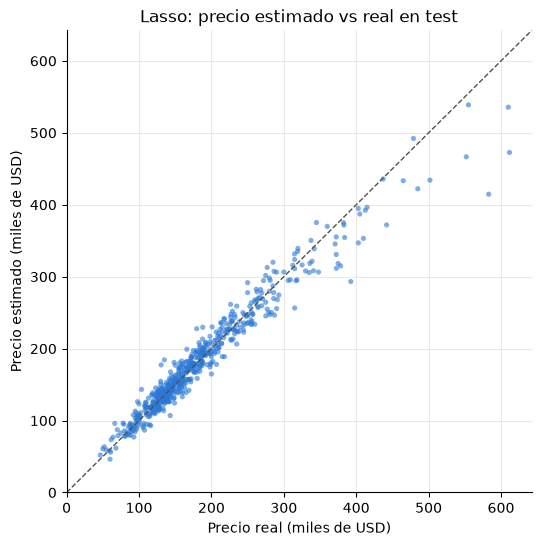

In [56]:
pred = predicciones[('Test real', elegido)]
error_usd = (pred - real).abs()
error_pct = error_usd / real * 100

print(f"{elegido} en el test real ({len(real)} casas)")
print(f"  Error medio: {error_usd.mean():,.0f} USD | error mediano: {error_usd.median():,.0f} USD")
print(f"  Error porcentual mediano: {error_pct.median():.1f} %")
for limite in [5, 10, 20]:
    print(f"  Casas con error menor a {limite:2d} %: {(error_pct < limite).mean() * 100:.1f} %")
print(f"  Casas con error mayor a 30 %: {(error_pct > 30).sum()}")
caras = real > 450_000
print(f"  Casas de más de 450.000 USD: {caras.sum()}, subestimadas: {(pred[caras] < real[caras]).sum()} "
      f"(error con signo: {sorted(((pred[caras] - real[caras]) / real[caras] * 100).round(1).tolist())})")
print()
print("Casas con error mayor a 30 %:")
print(pd.DataFrame({'Barrio': seg_test['Neighborhood'], 'Condición de venta': seg_test['Sale Condition'],
                    'Precio real': real, 'Estimado': pred.round(0), 'Error %': error_pct.round(1)})
      [error_pct > 30].to_string())

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(real / 1000, pred / 1000, s=14, color=COLOR, alpha=0.6, edgecolors='none')
limites = [0, max(real.max(), pred.max()) / 1000 * 1.05]
ax.plot(limites, limites, color='#52514e', linewidth=1, linestyle='--')
ax.set(xlim=limites, ylim=limites, xlabel='Precio real (miles de USD)', ylabel='Precio estimado (miles de USD)',
       title=f'{elegido}: precio estimado vs real en test')
plt.show()

- En la mitad de las casas de test el error es menor a 8.659 USD, y en la mitad es menor a 5,3 % del precio (dos medianas distintas, una en dólares y otra relativa). El error promedio, 12.407 USD, es mayor porque unas pocas casas tienen errores grandes.
- El 77,8 % de las casas tiene un error menor a 10 % y el 96,6 % menor a 20 %. Solo 4 de 582 superan el 30 %: ventas normales en `Edwards` y `Sawyer`, una `Abnorml` en `OldTown` y una `Family` en `NAmes`. En las cuatro el modelo sobreestimó.
- En el gráfico los puntos siguen la diagonal hasta unos 400.000 USD. Más arriba el modelo subestima: de las 9 casas de más de 450.000 USD, 8 quedan bajo su precio real, cuatro en más de 13 %.

Aumento del RMSE en test al desordenar cada variable (USD):
Gr Liv Area      21926.0
Overall Qual     13710.0
Total Bsmt SF    12753.0
Year Built        5003.0
Neighborhood      3854.0
Lot Area          3744.0
2nd Flr SF        2590.0
Sale Type         2541.0
Garage Cars       2471.0
Overall Cond      2390.0
Kitchen Qual      1733.0
Bsmt Exposure     1448.0
Bsmt Qual         1343.0
Exter Qual        1194.0
Fireplaces        1161.0


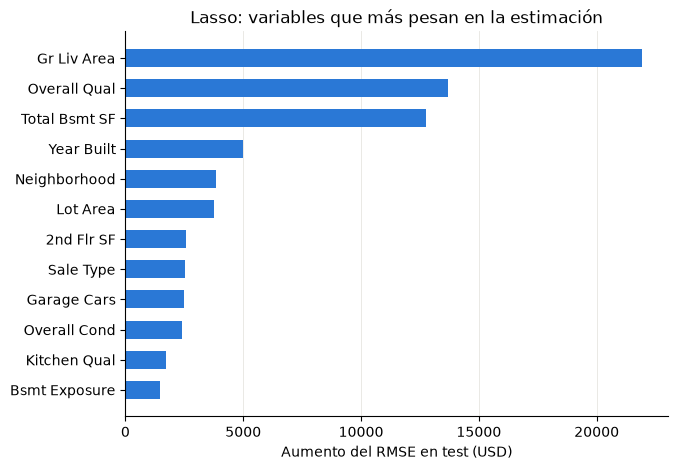

In [57]:
def importancia_por_variable(modelo, X, y, repeticiones=10):
    grupos = {}
    for col in X.columns:
        grupo = col if col.startswith('Tiene_') else col.split('_')[0]
        grupos.setdefault(grupo, []).append(col)
    base = root_mean_squared_error(y, modelo.predict(X))
    rng = np.random.default_rng(RANDOM_STATE)
    resultado = {}
    for grupo, cols in grupos.items():
        aumentos = []
        for _ in range(repeticiones):
            X_perm = X.copy()
            X_perm[cols] = X[cols].values[rng.permutation(len(X))]
            aumentos.append(root_mean_squared_error(y, modelo.predict(X_perm)) - base)
        resultado[grupo] = np.mean(aumentos)
    return pd.Series(resultado).sort_values(ascending=False)


X_te_elegido = datos[modelos[elegido][0]]['test'][0]
importancia = importancia_por_variable(ajustados[elegido], X_te_elegido, real)
print("Aumento del RMSE en test al desordenar cada variable (USD):")
print(importancia.head(15).round(0).to_string())

top = importancia.head(12)[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values, color=COLOR, height=0.6)
ax.set(xlabel='Aumento del RMSE en test (USD)', title=f'{elegido}: variables que más pesan en la estimación')
ax.grid(axis='y', visible=False)
plt.show()

La importancia por permutación mide cuánto sube el RMSE en test si se desordena una variable (las dummies de una variable se desordenan juntas). Pesa más la superficie habitable (`Gr Liv Area`, unos 21.900 USD), seguida de la calidad general (`Overall Qual`, 13.700) y la superficie del sótano (`Total Bsmt SF`, 12.800). Después vienen el año de construcción, el barrio y el terreno, con entre 3.700 y 5.000 USD. Tamaño, calidad, antigüedad y ubicación: lo mismo que mira cualquier tasación.

`Sale Type` está en el octavo lugar. El modelo usa el tipo de venta, y por eso al tasar se le asigna `WD`, una venta normal (sección 11).

In [58]:
X_tr_elegido = datos[modelos[elegido][0]]['train'][0]
regresor = ajustados[elegido].regressor_
base_log = regresor.intercept_ + X_tr_elegido.mean().values @ regresor.coef_

ejemplo = (real - real.median()).abs().idxmin()   # la casa de test con el precio más cercano a la mediana
aportes = (X_te_elegido.loc[ejemplo] - X_tr_elegido.mean()) * regresor.coef_
aportes = aportes.groupby(lambda c: c if c.startswith('Tiene_') else c.split('_')[0]).sum()
principales = aportes.reindex(aportes.abs().sort_values(ascending=False).index).head(6)
principales['Resto de variables'] = aportes.sum() - principales.sum()

print(f"Casa id {ejemplo} ({seg_test.loc[ejemplo, 'Neighborhood']}): precio real {real[ejemplo]:,.0f} USD")
print(f"Punto de partida (casa con valores promedio): {np.expm1(base_log):,.0f} USD")
for variable, aporte in principales.items():
    print(f"  {variable:22s} {np.expm1(aporte) * 100:+6.1f} %")
estimado = np.expm1(base_log + aportes.sum())
print(f"Estimación: {estimado:,.0f} USD (modelo: {pred[ejemplo]:,.0f} USD)")

Casa id 1606 (Mitchel): precio real 160,000 USD
Punto de partida (casa con valores promedio): 167,304 USD
  Functional               -7.9 %
  Gr Liv Area              +8.3 %
  Overall Cond             +6.2 %
  Year Built               -4.6 %
  2nd Flr SF               +3.5 %
  Lot Area                 +2.6 %
  Resto de variables       -1.0 %
Estimación: 177,830 USD (modelo: 177,830 USD)


El modelo es lineal en escala logarítmica, así que cada estimación se separa en el aporte de cada variable. Se parte de una casa con los valores promedio de train (167.304 USD) y cada variable sube o baja ese valor en un porcentaje. En la casa del ejemplo (id 1606, `Mitchel`, vendida en 160.000 USD) la superficie habitable suma 8,3 % y la condición general 6,2 %; la funcionalidad (`Functional`) resta 7,9 % y el año de construcción 4,6 %. El modelo estima 177.830 USD, un 11 % sobre el precio real.

Con este desglose el perito puede justificar el valor ante un cliente o un banco y revisar si alguna variable está mal registrada. Random Forest y XGBoost no tienen una descomposición directa; habría que calcularla con SHAP u otra herramienta.

In [59]:
casas_por_barrio = segmentos['Neighborhood'].value_counts()
poco_representado = seg_test['Neighborhood'].map(casas_por_barrio) < 30
print(f"Barrios con menos de 30 casas en los datos: {sorted(casas_por_barrio[casas_por_barrio < 30].index)}")
print(pd.DataFrame({'Casas en test': poco_representado.value_counts(),
                    'MAPE %': error_pct.groupby(poco_representado).mean().round(1)})
      .rename(index={True: 'Barrio con menos de 30 casas', False: 'Resto'}).to_string())

Barrios con menos de 30 casas en los datos: ['Blmngtn', 'Blueste', 'Greens', 'GrnHill', 'Landmrk', 'NPkVill', 'Veenker']
                              Casas en test  MAPE %
Neighborhood                                       
Resto                                   565     6.8
Barrio con menos de 30 casas             17     4.7


La EP1 propuso derivar a tasación manual las casas de barrios con menos de 30 ventas, porque el modelo tiene pocos ejemplos de ellos. En este test no se ve ese problema: las 17 casas de esos barrios tienen un MAPE de 4,7 %, menor que el 6,8 % del resto. Son pocas casas para concluir algo, así que la regla se puede mantener como precaución, pero estos datos no la exigen.

## 27. Conclusiones

El modelo elegido es Lasso: uno de los dos que cumplen el criterio de salida completo en el test, y el que usa menos variables con la misma precisión que Ridge.

| KPI | Umbral | Lasso, test real | Lasso, venta normal impuesta |
|---|---|---|---|
| R² | ≥ 0,85 | 0,948 | 0,949 |
| RMSE | ≤ 30.000 USD | 19.241 USD | 19.084 USD |
| MAE | ≤ 20.000 USD | 12.407 USD | 12.462 USD |
| MAPE | ≤ 12 % | 6,77 % | 6,93 % |
| Brecha de R² entre train y test | ≤ 5 puntos | −0,9 | −1,0 |
| Brecha de MAPE entre barrios | ≤ 8 puntos | 6,1 | 6,2 |

- Frente a Random Forest y XGBoost, se equivoca menos (unos 4.000 y 2.400 USD menos de RMSE en test) y no sobreajusta. Con sus parámetros iniciales los árboles casi memorizan train; Random Forest tampoco cumple la equidad.
- Frente a Ridge, tiene la misma precisión (115 USD de diferencia en test) con 33 columnas menos.
- Cada estimación se descompone en el aporte de cada variable, que es la trazabilidad que pide el problema de negocio.

Uso recomendado: valor de partida para el perito en viviendas de zonas residenciales, tasadas como venta normal y con `Yr Sold = 2010`. En el test, la mitad de las casas tuvo un error menor a 5,3 % y casi 8 de cada 10 uno menor a 10 %.

Limitaciones:

- Subestima las casas de más de 450.000 USD y sobreestima algo las del cuartil más barato. En esos extremos el perito debería revisar el valor con más cuidado.
- En las ventas anómalas o entre familiares el error es de 11,2 % a 15,5 %, y esas ventas no se pueden identificar antes de vender.
- Las zonas no residenciales quedan fuera de alcance y van a tasación manual.
- Los datos son de 2006 a 2010: el modelo tasa a precios de ese período.

Queda para la parte 3 ver si Random Forest y XGBoost cumplen la brecha de R² al limitar la profundidad de los árboles.

# Parte 3: optimización de hiperparámetros

En la parte 2 ganó Lasso. Random Forest y XGBoost quedaron fuera por el KPI de sobreajuste: su brecha de R² entre train y test fue de 6,1 y 6,3 puntos, sobre el máximo de 5 (sección 23). Aquí ajustamos los hiperparámetros de los cuatro modelos, con la mayor parte del trabajo en los árboles, para responder dos preguntas: ¿con otra configuración cumplen ese KPI? ¿Eso cambia la comparación con Lasso?

Esta parte elige los hiperparámetros y deja la evidencia de cada valor. Los ensambles, la generalización, el test y la selección final están en la parte 4 y usan lo que esta parte guarda.

- Sección 28: protocolo, fijado antes de buscar.
- Sección 29: línea base, los parámetros del P2 medidos con este protocolo.
- Sección 30: espacios de búsqueda.
- Secciones 31 y 32: búsquedas en Random Forest y XGBoost.
- Secciones 33 a 35: evidencia de cada valor (curvas de validación, qué hiperparámetros importan, si la búsqueda alcanzó y cuánto cuesta exigir la brecha).
- Sección 36: Ridge y Lasso.
- Secciones 37 y 38: antes y después, y tabla final de hiperparámetros.
- Secciones 39 y 40: archivos guardados y traspaso.

## 28. Protocolo de la búsqueda

Lo escribimos antes de ejecutar la primera búsqueda y no lo cambiamos después.

Datos, folds y métricas: los del P2. `X_train_base` e `y_train_base` (2.314 casas de train, sin codificar), el mismo `cv` de 5 folds (`KFold` mezclado, semilla 42), el target en log con `con_log` y métricas en dólares. Las decisiones de preparación del P2 no se reabren.

Sin fuga de datos: cada configuración se evalúa con el pipeline completo de `modelos_finales` dentro de la validación cruzada, así que el escalado y el target encoding se ajustan de nuevo en cada fold. Buscar sobre los CSV codificados sería fuga, porque su preparación vio las casas que cada fold usa para validar (punto 1 de la sección 18).

El test no se usa: ninguna celda de esta parte lee `X_test_base` ni los CSV de test. El test se abre una sola vez, en la parte 4.

Método, en tres pasos para cada modelo de árboles:

1. `RandomizedSearchCV` con 60 configuraciones sorteadas del espacio de la sección 30. Con varios hiperparámetros una grilla gasta casi todos sus ajustes repitiendo los mismos valores de cada uno, y normalmente solo unos pocos importan; al sortear, cada configuración prueba un valor nuevo de todos (Bergstra y Bengio, 2012). Con 60 sorteos hay un 95 % de probabilidad de que al menos uno caiga en el 5 % mejor del espacio (1 − 0,95^60).
2. `GridSearchCV` fino alrededor de la mejor aleatoria. Si la mejor de la grilla queda en el borde de un rango, se amplía y se repite.
3. Curvas de validación alrededor de la elegida, moviendo un hiperparámetro a la vez. Son la evidencia de cada valor y un control (ver más abajo).

En Ridge y Lasso solo se busca `alpha`, con un `GridSearchCV` sobre los mismos folds en vez de `RidgeCV` y `LassoCV`, para que los cuatro modelos sigan el mismo protocolo.

Regla para elegir la configuración de cada modelo: entre las que tienen una brecha de R² entre train y validación de hasta 5 puntos, la de menor RMSE de validación. La brecha se calcula como en la sección 22 (R² promedio de train menos R² promedio de validación, en puntos).

- El KPI de sobreajuste es eliminatorio (sección 20). Una configuración que baja el error memorizando train quedaría fuera en el test, igual que en el P2.
- Es un criterio conservador: en el P2 la brecha de los árboles fue mayor en validación (9,3 y 8,5) que en test (6,1 y 6,3).
- El umbral no se relaja. Si ninguna configuración de un modelo cumple, se informa así.

Cuándo un cambio es real: el criterio del P2 (secciones 9 a 11), mejorar en promedio y en al menos 4 de los 5 folds, y además por más que la desviación del RMSE entre folds (de 1.000 a 2.500 USD en la sección 22). Se usa en la comparación P2 contra P3 (sección 37) y en las curvas del paso 3. Las curvas no sirven para seguir afinando: si un vecino cumple la brecha y mejora a la elegida en al menos 4 folds y por más que esa desviación, la búsqueda dejó fuera una zona mejor y se amplía. Si mejora menos, es ruido y la configuración se mantiene.

Escenarios de decisión, que aplica la selección final con el test:

- (a) Los árboles siguen sin cumplir la brecha de R² en test: se mantiene Lasso.
- (b) La cumplen, pero no superan a Lasso por más de 1 punto de R² de validación: se mantiene Lasso por interpretabilidad (regla 3 de la sección 20).
- (c) La cumplen y superan a Lasso por más de 1 punto: cambia el modelo.

En el orden de interpretabilidad van primero los lineales, después los modelos de árboles y al final un stacking, que combina varios modelos.

Cómputo y reproducibilidad: el paralelismo va en un solo nivel (la búsqueda reparte las configuraciones con `n_jobs=-1` y cada modelo usa un hilo) y todas las semillas son 42. Cada búsqueda se guarda en `models/busquedas/` y se carga si existe; el interruptor `REPETIR_BUSQUEDAS` de la celda siguiente obliga a repetirlas. La celda de entorno del inicio exige las versiones de `requirements.txt`, porque con otras versiones Random Forest y XGBoost cambian en algunos cientos de dólares y lo guardado dejaría de ser comparable con lo que se calcula en el momento.

Referencia nueva de esta sección: Bergstra, J. y Bengio, Y. (2012). Random Search for Hyper-Parameter Optimization. Journal of Machine Learning Research, 13, 281-305.

In [60]:
import json, time
from pathlib import Path
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

REPETIR_BUSQUEDAS = False

os.environ['PYTHONWARNINGS'] = 'ignore:Found unknown categories'

RUTA_BUSQUEDAS = Path('../models/busquedas')
RUTA_IMAGENES = Path('../images')
RUTA_PARAMS = Path('../models/mejores_params.json')
RUTA_BUSQUEDAS.mkdir(parents=True, exist_ok=True)
RUTA_IMAGENES.mkdir(parents=True, exist_ok=True)

MAX_BRECHA = float(KPI.loc['Brecha R² train-test (pts)', 'Umbral'])   # 5 puntos, el KPI de sobreajuste de la sección 20
MIN_FOLDS = 4          # un cambio es real si mejora en promedio y en al menos 4 de los 5 folds (secciones 9 a 11)
N_ALEATORIAS = 60      # configuraciones por búsqueda aleatoria: 1 - 0,95^60 = 95 % de probabilidad de caer en el 5 % mejor
PREFIJO = 'regressor__modelo__'   # ruta del modelo dentro de TransformedTargetRegressor(Pipeline([pre, modelo]))

COLOR_VAL, COLOR_TRAIN, COLOR_REF = COLOR, '#eb6834', '#52514e'

assert cv.get_n_splits() == 5 and cv.shuffle and cv.random_state == RANDOM_STATE
print(f"Train de la búsqueda: {X_train_base.shape[0]} casas x {X_train_base.shape[1]} variables sin codificar | "
      f"folds: {cv.get_n_splits()} | brecha máxima: {MAX_BRECHA:g} puntos | REPETIR_BUSQUEDAS = {REPETIR_BUSQUEDAS}")

Train de la búsqueda: 2314 casas x 79 variables sin codificar | folds: 5 | brecha máxima: 5 puntos | REPETIR_BUSQUEDAS = False


Funciones de apoyo de esta parte:

- `pipeline_p3(nombre)`: el pipeline completo del P2 de un modelo, listo para recibir hiperparámetros.
- `busqueda_aleatoria` y `busqueda_grilla`: `RandomizedSearchCV` y `GridSearchCV` con los folds y métricas del P2 y `return_train_score=True`, que hace falta para calcular la brecha.
- `buscar(archivo, busqueda)`: con `REPETIR_BUSQUEDAS = True` ejecuta la búsqueda y la guarda; con `False` carga el archivo y, si no existe, ejecuta la búsqueda y la guarda. El archivo es un JSON con RMSE, MAE, MAPE y R² de cada fold para cada configuración. Usamos JSON y no CSV porque conserva los tipos: `None` sigue siendo `None` y un entero sigue siendo entero, que es lo que esperan `max_depth` o `n_estimators` al reconstruir el modelo.
- `elegir(tabla)`: aplica la regla de la sección 28.
- `folds_en_que_gana(a, b)`: en cuántos de los 5 folds una configuración tiene menor RMSE de validación que otra.

In [61]:
def pipeline_p3(nombre):
    modelo = modelos_finales[nombre](limpieza_modelo[nombre], QUITAR)
    if nombre == 'Ridge':
        modelo.set_params(regressor__modelo=Ridge())
    elif nombre == 'Lasso':
        modelo.set_params(regressor__modelo=Lasso(max_iter=50000))
    else:
        modelo.set_params(regressor__modelo__n_jobs=1)
    return modelo


def busqueda_aleatoria(nombre, espacio, n_iter=N_ALEATORIAS):
    return RandomizedSearchCV(pipeline_p3(nombre), {PREFIJO + k: v for k, v in espacio.items()}, n_iter=n_iter,
                              cv=cv, scoring=metricas, refit=False, return_train_score=True,
                              n_jobs=-1, random_state=RANDOM_STATE)


def busqueda_grilla(nombre, grilla):
    return GridSearchCV(pipeline_p3(nombre), {PREFIJO + k: v for k, v in grilla.items()},
                        cv=cv, scoring=metricas, refit=False, return_train_score=True, n_jobs=-1)


def a_nativo(valor):
    return valor.item() if isinstance(valor, np.generic) else valor


def guardar_busqueda(archivo, busqueda, segundos):
    r = busqueda.cv_results_
    por_fold = lambda clave: np.column_stack([r[f'split{i}_{clave}'] for i in range(cv.get_n_splits())])
    espacio = getattr(busqueda, 'param_distributions', None) or busqueda.param_grid
    contenido = {
        'tipo': type(busqueda).__name__,
        'espacio': {k.replace(PREFIJO, ''): [a_nativo(v) for v in valores] for k, valores in espacio.items()},
        'segundos': round(segundos, 1),
        'configuraciones': [{
            'params': {k.replace(PREFIJO, ''): a_nativo(v) for k, v in params.items()},
            'rmse_train': (-por_fold('train_rmse')[i]).round(2).tolist(),
            'rmse_val': (-por_fold('test_rmse')[i]).round(2).tolist(),
            'mae_val': (-por_fold('test_mae')[i]).round(2).tolist(),
            'mape_val': (-por_fold('test_mape')[i] * 100).round(4).tolist(),
            'r2_train': por_fold('train_r2')[i].round(6).tolist(),
            'r2_val': por_fold('test_r2')[i].round(6).tolist(),
        } for i, params in enumerate(r['params'])],
    }
    archivo.write_text(json.dumps(contenido, indent=1, ensure_ascii=False))


def fila_metricas(rmse_train, rmse_val, mae_val, mape_val, r2_train, r2_val):
    return {'RMSE train': np.mean(rmse_train), 'RMSE val': np.mean(rmse_val), 'Desv. RMSE val': np.std(rmse_val),
            'MAE val': np.mean(mae_val), 'MAPE % val': np.mean(mape_val),
            'R² train': np.mean(r2_train), 'R² val': np.mean(r2_val),
            'Brecha R² (pts)': (np.mean(r2_train) - np.mean(r2_val)) * 100,
            'RMSE val por fold': np.asarray(rmse_val)}


def cargar_busqueda(archivo):
    contenido = json.loads(archivo.read_text())
    tabla = pd.DataFrame([{'params': c['params'],
                           **fila_metricas(*(c[k] for k in ['rmse_train', 'rmse_val', 'mae_val', 'mape_val', 'r2_train', 'r2_val']))}
                          for c in contenido['configuraciones']])
    tabla.attrs = {'espacio': contenido['espacio'], 'segundos': contenido['segundos'], 'tipo': contenido['tipo']}
    return tabla


def buscar(nombre_archivo, busqueda):
    archivo = RUTA_BUSQUEDAS / f'{nombre_archivo}.json'
    if REPETIR_BUSQUEDAS or not archivo.exists():
        archivo.parent.mkdir(parents=True, exist_ok=True)
        inicio = time.time()
        busqueda.fit(X_train_base, y_train_base)
        guardar_busqueda(archivo, busqueda, time.time() - inicio)
    tabla = cargar_busqueda(archivo)
    espacio = getattr(busqueda, 'param_distributions', None) or busqueda.param_grid
    espacio = {k.replace(PREFIJO, ''): [a_nativo(v) for v in valores] for k, valores in espacio.items()}
    if espacio != tabla.attrs['espacio']:
        print(f"Aviso: el espacio guardado en {archivo.name} no coincide con el del código; "
              f"ejecutar con REPETIR_BUSQUEDAS = True.")
    return tabla


def elegir(tabla):
    cumplen = tabla[tabla['Brecha R² (pts)'] <= MAX_BRECHA]
    return cumplen['RMSE val'].idxmin() if len(cumplen) else None


def folds_en_que_gana(a, b):
    return int((a['RMSE val por fold'] < b['RMSE val por fold']).sum())


FORMATO = {'RMSE train': 0, 'RMSE val': 0, 'Desv. RMSE val': 0, 'MAE val': 0, 'MAPE % val': 2,
           'R² train': 3, 'R² val': 3, 'Brecha R² (pts)': 1}


def guardar_figura(fig, nombre):
    fig.savefig(RUTA_IMAGENES / f'{nombre}.png', dpi=150, bbox_inches='tight')


def mostrar(filas, tabla=None, columnas=('RMSE val', 'Desv. RMSE val', 'R² train', 'R² val', 'Brecha R² (pts)')):
    a_columnas = lambda t: pd.DataFrame(list(t['params']), index=t.index, dtype=object)
    todos = a_columnas(filas if tabla is None else tabla)
    varian = [c for c in todos if todos[c].map(repr).nunique() > 1] or list(todos)
    return pd.concat([a_columnas(filas)[varian], filas[list(columnas)].astype(float).round(FORMATO)], axis=1)


def resumen_busqueda(tabla, titulo, n=8):
    cumplen = tabla[tabla['Brecha R² (pts)'] <= MAX_BRECHA]
    print(f"=== {titulo}: {len(tabla)} configuraciones, {len(cumplen)} cumplen la brecha "
          f"(la búsqueda tardó {tabla.attrs['segundos']:.0f} s) ===")
    print(f"Las {min(n, len(cumplen))} de menor RMSE de validación entre las que cumplen:")
    print(mostrar(cumplen.sort_values('RMSE val').head(n), tabla).to_string())


def mejor_por_valor(tabla, hp):
    cumplen = tabla[tabla['Brecha R² (pts)'] <= MAX_BRECHA]
    valores = cumplen['params'].map(lambda p: etiqueta(p[hp]))
    return cumplen['RMSE val'].groupby(valores, sort=False).min().round(0).astype(int).to_dict()


def en_borde(params, grilla):
    return {hp: params[hp] for hp, valores in grilla.items() if len(valores) > 1 and params[hp] in (valores[0], valores[-1])}


def unir(**etapas):
    todas = pd.concat([tabla.assign(Etapa=etapa) for etapa, tabla in etapas.items()], ignore_index=True)
    repetida = todas['params'].map(lambda p: json.dumps(p, sort_keys=True)).duplicated()
    return todas[~repetida].reset_index(drop=True)

## 29. Línea base comparable

La tabla de la sección 22 se calculó sobre los CSV codificados, con otro protocolo, así que no sirve como "antes". Aquí recalculamos los cuatro modelos con los parámetros del P2 y los pipelines completos sobre `X_train_base`. Ridge y Lasso mantienen `RidgeCV` y `LassoCV`, que eligen su `alpha` dentro de cada fold.

In [62]:
filas = {}
for nombre, construir in modelos_finales.items():
    res = cross_validate(construir(limpieza_modelo[nombre], QUITAR), X_train_base, y_train_base,
                         cv=cv, scoring=metricas, return_train_score=True)
    filas[nombre] = fila_metricas(-res['train_rmse'], -res['test_rmse'], -res['test_mae'],
                                  -res['test_mape'] * 100, res['train_r2'], res['test_r2'])

base_p2 = pd.DataFrame(filas).T
base_p2.index.name = 'Modelo'
print("=== Parámetros del P2, pipelines completos (5 folds sobre train) ===")
print(base_p2.drop(columns='RMSE val por fold').astype(float).round(FORMATO).to_string())

comparacion = pd.DataFrame({'RMSE val, CSV codificados (sección 22)': resultados_cv['RMSE val'],
                            'RMSE val, pipelines completos': base_p2['RMSE val'].astype(float)})
comparacion['Diferencia'] = comparacion.iloc[:, 1] - comparacion.iloc[:, 0]
print()
print(comparacion.round(0).to_string())

=== Parámetros del P2, pipelines completos (5 folds sobre train) ===
               RMSE train  RMSE val  Desv. RMSE val  MAE val  MAPE % val  R² train  R² val  Brecha R² (pts)
Modelo                                                                                                     
Ridge             18811.0   20159.0           996.0  13744.0        8.06     0.940   0.930              1.0
Lasso             18869.0   20199.0          1032.0  13761.0        8.08     0.939   0.930              1.0
Random Forest     10178.0   25151.0          2527.0  15794.0        9.22     0.982   0.891              9.1
XGBoost            4909.0   22351.0          1350.0  14310.0        8.39     0.996   0.914              8.2

               RMSE val, CSV codificados (sección 22)  RMSE val, pipelines completos  Diferencia
Modelo                                                                                          
Ridge                                         20152.0                        20159.0    

- Este es el "antes" de la parte 3: 20.159 USD de RMSE de validación en Ridge, 20.199 en Lasso, 25.151 en Random Forest y 22.351 en XGBoost.
- La diferencia con la sección 22 es chica (8, −7, 14 y −178 USD), menos de los 200 USD que anticipaba esa sección.
- El diagnóstico del P2 se mantiene: Random Forest y XGBoost tienen R² de train de 0,982 y 0,996 y brechas de 9,1 y 8,2 puntos. Ridge y Lasso, 1,0.

## 30. Espacios de búsqueda

Los rangos salen de un diagnóstico hecho antes de buscar: primero medimos cuánto tarda un ajuste, después movimos un hiperparámetro a la vez desde la configuración del P2, y con eso armamos la tabla de la sección 30.3.

### 30.1 Cuánto tarda un ajuste

In [63]:
tr, va = next(cv.split(X_train_base))
tiempos = {}
for nombre in ['Random Forest', 'XGBoost']:
    modelo = pipeline_p3(nombre)
    inicio = time.time()
    modelo.fit(X_train_base.iloc[tr], y_train_base.iloc[tr])
    tiempos[nombre] = time.time() - inicio

nucleos = os.cpu_count()
for nombre, t in tiempos.items():
    total = N_ALEATORIAS * cv.get_n_splits() * t
    print(f"{nombre}: {t:.1f} s por ajuste | {N_ALEATORIAS} configuraciones x {cv.get_n_splits()} folds = "
          f"{N_ALEATORIAS * cv.get_n_splits()} ajustes, unos {total / 60:.0f} min en 1 hilo "
          f"y {total / 60 / nucleos:.1f} min repartidos en {nucleos} núcleos")

Random Forest: 6.9 s por ajuste | 60 configuraciones x 5 folds = 300 ajustes, unos 34 min en 1 hilo y 2.9 min repartidos en 12 núcleos
XGBoost: 1.1 s por ajuste | 60 configuraciones x 5 folds = 300 ajustes, unos 5 min en 1 hilo y 0.5 min repartidos en 12 núcleos


En el equipo donde se ejecutó (12 núcleos), un ajuste tarda 6,9 segundos en Random Forest y 1,1 en XGBoost. 60 configuraciones por 5 folds son 300 ajustes por modelo, unos 3 minutos y medio minuto repartidos en los núcleos, así que no hace falta reducir el número de configuraciones.

Paralelizamos la búsqueda y no el modelo: cada ajuste usa un hilo y la búsqueda reparte los 300. Con los dos niveles a la vez habría más hilos que núcleos y todo iría más lento.

### 30.2 Diagnóstico: un hiperparámetro a la vez desde la configuración del P2

El P2 dejó dicho por qué sobreajustan los árboles: Random Forest usa árboles sin límite de profundidad y XGBoost suma 500 árboles de profundidad 6 sin submuestreo (sección 22). Antes de fijar rangos vemos qué causa pesa más. En cada curva se mueve un solo hiperparámetro y se mira dónde baja la brecha a 5 puntos y qué le pasa al RMSE de validación ahí.

Criterio para los rangos, escrito antes de ver las curvas: cada rango incluye el valor del P2 y avanza hacia el lado que regulariza hasta que la brecha cumple o el error empeora con claridad. Si después la mejor configuración queda en un borde, el protocolo obliga a ampliar.

En los gráficos, arriba están el RMSE de train y de validación y abajo la brecha de R² con su máximo de 5 puntos. La línea punteada marca el valor del P2.

In [64]:
PARAMS_P2 = {
    'Random Forest': {'n_estimators': 300, 'max_features': 1.0, 'min_samples_leaf': 1, 'max_depth': None, 'max_samples': 1.0},
    'XGBoost': {'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 6, 'min_child_weight': 1, 'subsample': 1.0,
                'colsample_bytree': 1.0, 'reg_lambda': 1.0, 'reg_alpha': 0.0, 'gamma': 0.0},
}


def curvas(nombre, carpeta, config, valores):
    return {hp: buscar(f'{carpeta}/{hp}',
                       busqueda_grilla(nombre, {**{k: [v] for k, v in config.items()}, hp: lista}))
            for hp, lista in valores.items()}


def etiqueta(valor):
    return 'sin límite' if valor is None else f'{valor:g}'


def graficar_curvas(curvas_modelo, titulo, marcas, archivo, columnas=5):
    estilo = {'P2': dict(color=COLOR_REF, linestyle='--'), 'P3': dict(color='#0b0b0b', linestyle='-')}
    hps = list(curvas_modelo)
    bloques = [hps[i:i + columnas] for i in range(0, len(hps), columnas)]
    fig, axes = plt.subplots(2 * len(bloques), columnas, figsize=(3.3 * columnas, 5.6 * len(bloques)),
                             squeeze=False, sharey='row')
    for b, bloque in enumerate(bloques):
        for j in range(columnas):
            arriba, abajo = axes[2 * b, j], axes[2 * b + 1, j]
            if j >= len(bloque):
                arriba.set_visible(False); abajo.set_visible(False)
                continue
            hp, tabla = bloque[j], curvas_modelo[bloque[j]]
            valores = [p[hp] for p in tabla['params']]
            x = np.arange(len(valores))
            val, desv = tabla['RMSE val'] / 1000, tabla['Desv. RMSE val'] / 1000
            arriba.fill_between(x, val - desv, val + desv, color=COLOR_VAL, alpha=0.15, linewidth=0,
                                label='Validación ± 1 desv. entre folds')
            arriba.plot(x, tabla['RMSE train'] / 1000, color=COLOR_TRAIN, marker='o', markersize=4, linewidth=2, label='Train')
            arriba.plot(x, val, color=COLOR_VAL, marker='o', markersize=4, linewidth=2, label='Validación')
            abajo.plot(x, tabla['Brecha R² (pts)'], color=COLOR_VAL, marker='o', markersize=4, linewidth=2)
            abajo.axhline(MAX_BRECHA, color='#e34948', linewidth=1)
            for marca, config in marcas.items():
                if config[hp] in valores:
                    for ax in (arriba, abajo):
                        ax.axvline(valores.index(config[hp]), linewidth=1.2, **estilo[marca], label=marca)
            arriba.set_title(hp, fontsize=10)
            arriba.set_xticks(x, [])
            abajo.set_xticks(x, [etiqueta(v) for v in valores], rotation=45 if len(valores) > 7 else 0, fontsize=8)
            if j == 0:
                arriba.set_ylabel('RMSE (miles de USD)')
                abajo.set_ylabel('Brecha de R² (puntos)')
                abajo.text(0.02, MAX_BRECHA, f'máximo {MAX_BRECHA:g}', color='#e34948', fontsize=8, va='bottom',
                           transform=abajo.get_yaxis_transform())
        brechas = pd.concat([curvas_modelo[hp]['Brecha R² (pts)'] for hp in bloque])
        axes[2 * b + 1, 0].set_ylim(min(0, brechas.min() - 0.5), max(MAX_BRECHA + 1, brechas.max() + 0.5))
    manijas, rotulos = axes[0, 0].get_legend_handles_labels()
    unicos = dict(zip(rotulos, manijas))
    fig.legend(unicos.values(), unicos.keys(), loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=len(unicos), frameon=False)
    fig.suptitle(titulo, fontsize=12, fontweight='bold')
    fig.tight_layout()
    guardar_figura(fig, archivo)
    plt.show()

Control Random Forest: diferencia con la línea base +0.0 USD
Control XGBoost: diferencia con la línea base -0.0 USD
La configuración explícita del P2 reproduce la línea base de la sección 29 en los dos modelos.

n_estimators        25     50    100    200    300    500    800
RMSE train       10958  10516  10384  10226  10178  10173  10194
RMSE val         25995  25660  25376  25231  25151  25109  25134
Brecha R² (pts)   9.58   9.45   9.23   9.16   9.11   9.08   9.09

max_features       0.1    0.2    0.3    0.4    0.5    0.7      1
RMSE train       11040  10329  10130  10073  10049  10084  10178
RMSE val         26017  24805  24508  24459  24530  24770  25151
Brecha R² (pts)   9.49   8.70   8.52   8.50   8.58   8.79   9.11

min_samples_leaf      1      2      3      5      8     12     20     30
RMSE train        10178  11803  13530  16499  19343  21690  24566  27428
RMSE val          25151  25128  25236  25684  26228  26936  28288  30002
Brecha R² (pts)    9.11   8.48   7.83   6.70   

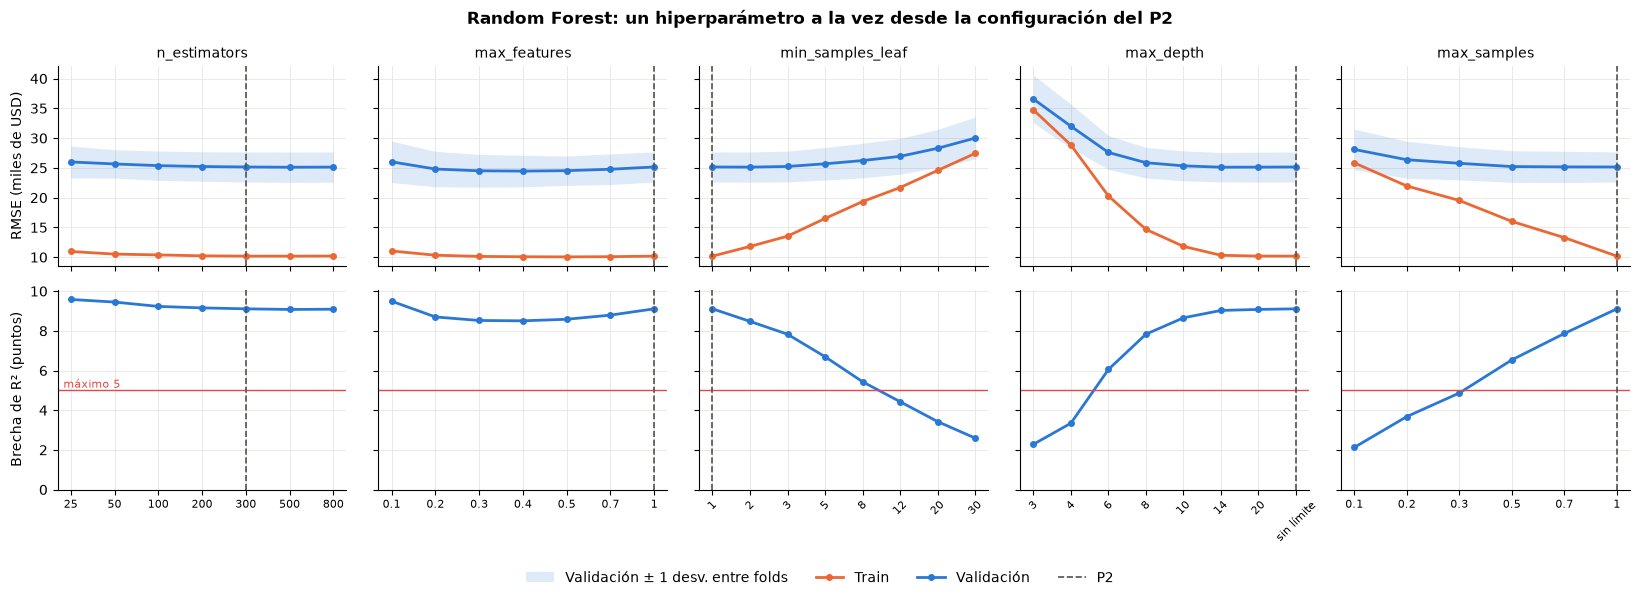

In [65]:
DIAGNOSTICO = {
    'Random Forest': {'n_estimators': [25, 50, 100, 200, 300, 500, 800],
                      'max_features': [0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0],
                      'min_samples_leaf': [1, 2, 3, 5, 8, 12, 20, 30],
                      'max_depth': [3, 4, 6, 8, 10, 14, 20, None],
                      'max_samples': [0.1, 0.2, 0.3, 0.5, 0.7, 1.0]},
    'XGBoost': {'max_depth': [1, 2, 3, 4, 5, 6, 8],
                'n_estimators': [50, 100, 200, 300, 500, 800, 1200],
                'learning_rate': [0.01, 0.02, 0.03, 0.05, 0.1, 0.2, 0.3],
                'min_child_weight': [1, 3, 5, 10, 20, 40],
                'subsample': [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
                'colsample_bytree': [0.2, 0.3, 0.5, 0.7, 1.0],
                'reg_lambda': [0.0, 0.1, 1.0, 3.0, 10.0, 30.0, 100.0],
                'reg_alpha': [0.0, 0.001, 0.01, 0.1, 0.3, 1.0],
                'gamma': [0.0, 0.0001, 0.001, 0.01, 0.03, 0.1, 0.3]},
}
CARPETA = {'Random Forest': 'rf', 'XGBoost': 'xgb'}

diagnostico = {nombre: curvas(nombre, f'{CARPETA[nombre]}_1_diagnostico', PARAMS_P2[nombre], valores)
               for nombre, valores in DIAGNOSTICO.items()}


def tabla_curva(tabla, hp):
    filas = {'RMSE train': tabla['RMSE train'].map('{:.0f}'.format), 'RMSE val': tabla['RMSE val'].map('{:.0f}'.format),
             'Brecha R² (pts)': tabla['Brecha R² (pts)'].map('{:.2f}'.format)}
    return pd.DataFrame(filas).set_axis([etiqueta(p[hp]) for p in tabla['params']]).rename_axis(hp).T


TOLERANCIA_CONTROL = 25
for nombre, hp in [('Random Forest', 'n_estimators'), ('XGBoost', 'max_depth')]:
    tabla = diagnostico[nombre][hp]
    fila_p2 = tabla[[p == PARAMS_P2[nombre] for p in tabla['params']]].iloc[0]
    print(f"Control {nombre}: diferencia con la línea base {fila_p2['RMSE val'] - base_p2.loc[nombre, 'RMSE val']:+.1f} USD")
print("La configuración explícita del P2 reproduce la línea base de la sección 29 en los dos modelos.\n")

for hp, tabla in diagnostico['Random Forest'].items():
    print(tabla_curva(tabla, hp).to_string(), end='\n\n')
graficar_curvas(diagnostico['Random Forest'], 'Random Forest: un hiperparámetro a la vez desde la configuración del P2',
                {'P2': PARAMS_P2['Random Forest']}, 'p3_01_rf_diagnostico')

Random Forest, desde la configuración del P2 (25.151 USD, brecha de 9,1):

- `n_estimators`: entre 300 y 800 árboles el RMSE de validación cambia 42 USD (25.151, 25.109 y 25.134) y la brecha no se mueve. Con 25 árboles sube a 25.995. Más árboles no sobreajustan ni mejoran, así que queda fijo en 300 y no entra a la búsqueda.
- `max_features`: el mínimo está en 0,4, con 24.459 USD, 692 menos que con todas las columnas. Mejora el error, pero la brecha apenas baja (8,5).
- `min_samples_leaf`: baja la brecha a costa de error. Cumple desde 12 casas por hoja (4,4 puntos), con 26.936 USD, 1.785 más que el P2.
- `max_depth`: cumple solo con profundidad 4 o menos (3,3 puntos con 4), con 31.996 USD. Es la forma más cara de bajar la brecha. Desde profundidad 14 el resultado es prácticamente el de sin límite (25.117 contra 25.151).
- `max_samples`: con 0,3 la brecha baja a 4,87 y el RMSE sube 617 USD (25.768). Es la forma más barata.

Ningún cambio por sí solo cumple la brecha sin subir el error. La búsqueda tiene que combinar `max_features`, que mejora el error, con `max_samples` o `min_samples_leaf`, que bajan la brecha.

max_depth            1      2      3      4      5      6      8
RMSE train       20531  16192  12812   9538   6971   4909   3038
RMSE val         23013  20898  20752  20742  21513  22351  23290
Brecha R² (pts)   1.87   3.04   4.59   5.85   7.11   8.16   9.15

n_estimators        50    100    200    300    500    800   1200
RMSE train       17638  10112   7730   6539   4909   3732   3155
RMSE val         26874  23216  22673  22509  22351  22397  22402
Brecha R² (pts)   7.05   7.49   7.79   7.96   8.16   8.36   8.44

learning_rate     0.01   0.02   0.03   0.05    0.1    0.2    0.3
RMSE train       10080   7731   6535   4909   3320   3294   3760
RMSE val         23227  22791  22573  22351  22484  23010  23565
Brecha R² (pts)   7.51   7.89   8.01   8.16   8.46   8.88   9.33

min_child_weight      1      3      5     10     20     40
RMSE train         4909   4923   5285   6342   9004  10844
RMSE val          22351  22733  22404  22056  22057  21724
Brecha R² (pts)    8.16   8.45   8.14   

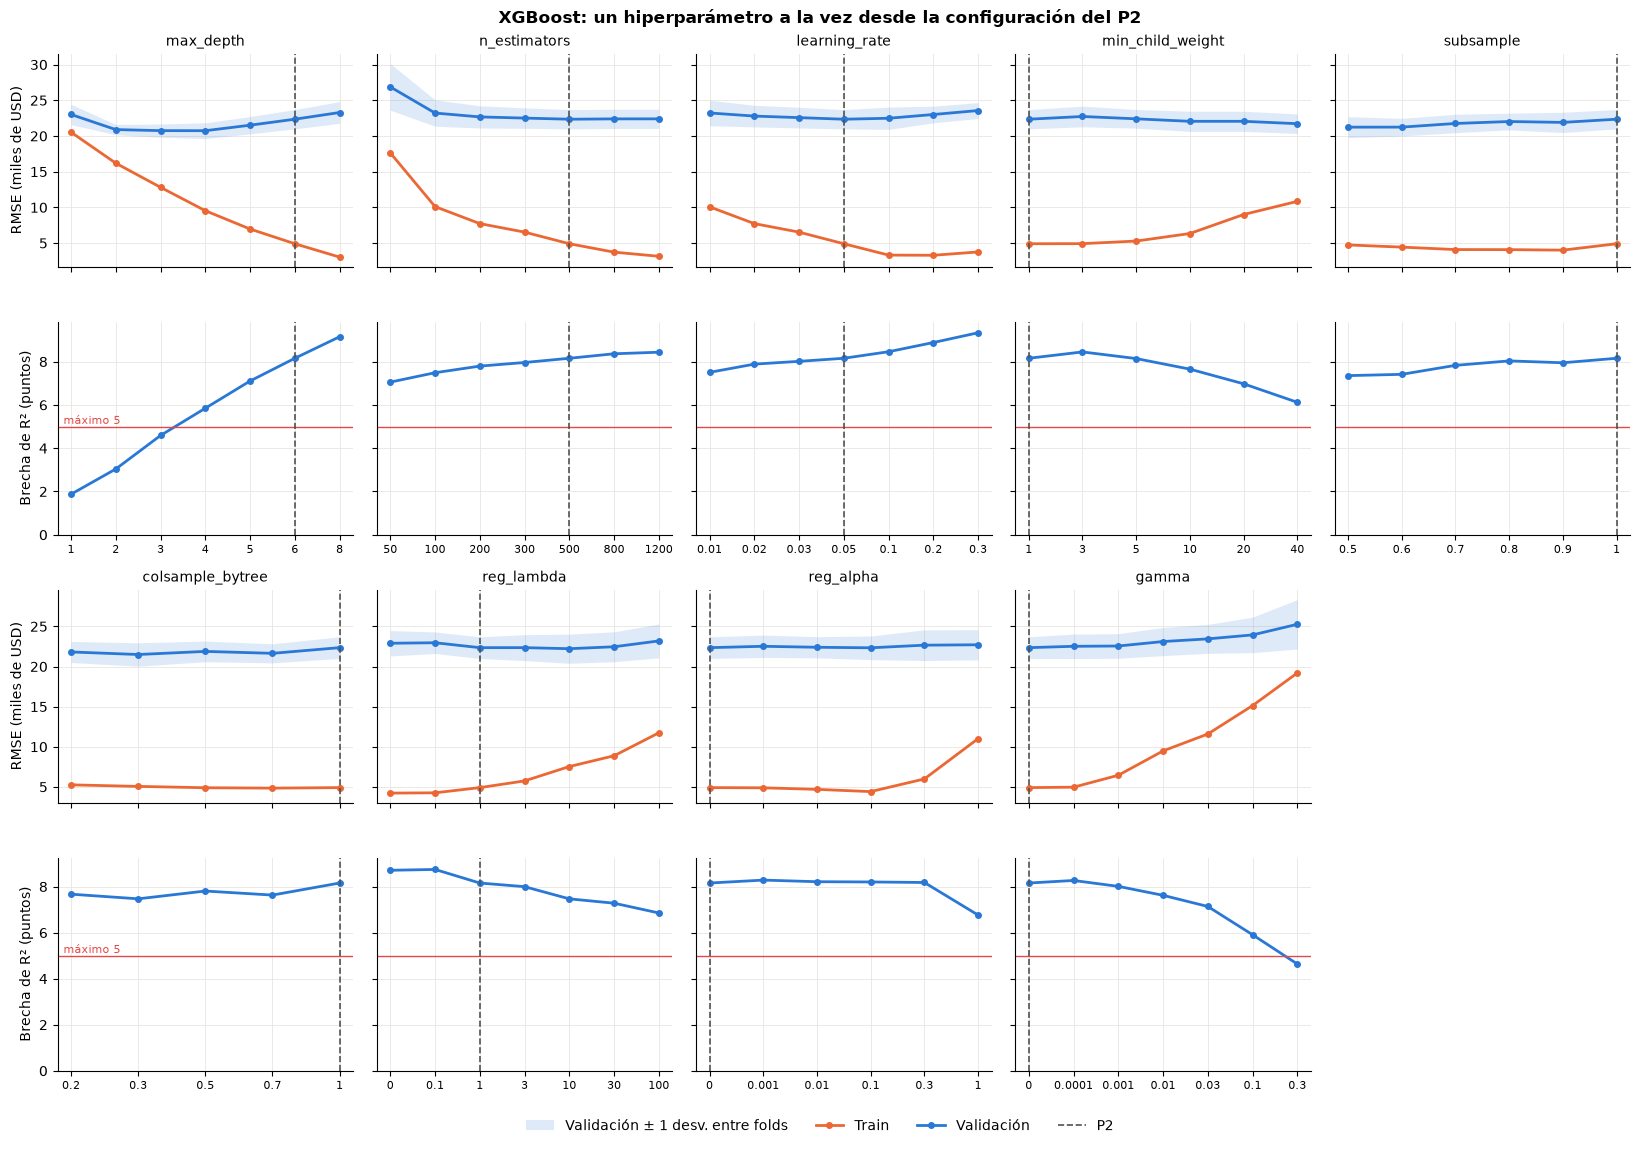

In [66]:
for hp, tabla in diagnostico['XGBoost'].items():
    print(tabla_curva(tabla, hp).to_string(), end='\n\n')
graficar_curvas(diagnostico['XGBoost'], 'XGBoost: un hiperparámetro a la vez desde la configuración del P2',
                {'P2': PARAMS_P2['XGBoost']}, 'p3_02_xgb_diagnostico')

`gamma` es la ganancia mínima que tiene que aportar un corte para hacerse, en las unidades del error, que aquí es el logaritmo del precio. Para saber qué valores tienen sentido miramos la ganancia de los cortes del XGBoost del P2.

In [67]:
xgb_p2 = pipeline_p3('XGBoost').fit(X_train_base, y_train_base)
arboles = xgb_p2.regressor_.named_steps['modelo'].get_booster().trees_to_dataframe()
ganancia = arboles.loc[arboles['Feature'] != 'Leaf', 'Gain']
print(f"Cortes del modelo: {len(ganancia):,}".replace(',', '.'))
print(f"Ganancia de un corte: mediana {ganancia.median():.4f} | percentil 90: {ganancia.quantile(0.9):.3f}")
for umbral in [0.01, 0.1, 1]:
    print(f"  cortes con ganancia menor a {umbral:g}: {(ganancia < umbral).mean() * 100:.0f} %")
print(f"Desviación estándar de log1p(SalePrice) en train: {np.log1p(y_train_base).std():.2f}")

Cortes del modelo: 17.614
Ganancia de un corte: mediana 0.0049 | percentil 90: 0.127
  cortes con ganancia menor a 0.01: 65 %
  cortes con ganancia menor a 0.1: 89 %
  cortes con ganancia menor a 1: 98 %
Desviación estándar de log1p(SalePrice) en train: 0.39


XGBoost, desde la configuración del P2 (22.351 USD, brecha de 8,2):

- `max_depth` es el que más pesa. Con profundidad 3 el RMSE de validación baja a 20.752 USD (1.599 menos) y la brecha a 4,6; con profundidad 2, a 20.898 y 3,0. Con 4 el error es el mismo (20.742), pero la brecha sube a 5,85, y con 8 el error llega a 23.290. La profundidad 6 del P2 era demasiada para 2.314 casas.
- `n_estimators` y `learning_rate` van juntos: con tasa 0,05, pasar de 300 a 1.200 árboles cambia el RMSE menos de 160 USD (22.509 a 22.351 a 22.402) y la brecha sube de 8,0 a 8,4. Se buscan los dos a la vez.
- `subsample` y `colsample_bytree` mejoran el error: 21.238 USD con la mitad de las casas por árbol (1.113 menos) y 21.496 con el 30 % de las columnas (855 menos). La brecha baja menos de 1 punto.
- `min_child_weight` y `reg_lambda` bajan la brecha sin subir el error: con 40 casas por hoja, 21.724 USD y 6,1 puntos; con `reg_lambda` = 10, 22.220 USD y 7,5.
- `gamma` y `reg_alpha` actúan en la escala del logaritmo del precio, cuya desviación estándar en train es 0,39. En el modelo del P2 la ganancia mediana de un corte es 0,0049 y el 98 % de los cortes gana menos de 1, así que un `gamma` de 1 a 5, habitual en tutoriales con otros targets, eliminaría casi todos los cortes. Aquí `gamma` = 0,1 ya sube el RMSE en 1.588 USD (23.939) y `reg_alpha` = 1 lo sube en 359. Sus rangos van en centésimas.

No usamos early stopping para fijar el número de árboles: necesita un conjunto de validación ya preparado dentro de `fit`, y eso no calza con un pipeline que prepara los datos en cada fold ni con `TransformedTargetRegressor`. Es más simple tratar `n_estimators` como un hiperparámetro más y mostrar su curva (sección 33).

### 30.3 Espacios de búsqueda

Cada rango es una lista de valores y la búsqueda aleatoria sortea uno de cada lista con la misma probabilidad. Usamos listas en vez de distribuciones continuas para que los valores elegidos sean redondos. En `learning_rate`, `reg_lambda`, `reg_alpha` y `gamma` los valores van espaciados por factores (0,01, 0,02, 0,03, 0,05...), porque su efecto depende del orden de magnitud.

| Modelo | Hiperparámetro | Qué controla | P2 | Rango | Por qué ese rango |
|---|---|---|---|---|---|
| Random Forest | `n_estimators` | Árboles que se promedian | 300 | Fijo en 300 | Entre 300 y 800 el RMSE cambia 42 USD y la brecha no se mueve (sección 30.2). Más árboles no sobreajustan (Breiman, 2001) |
| Random Forest | `max_features` | Fracción de columnas candidatas en cada corte. Con menos columnas los árboles se parecen menos y promediarlos reduce más el error (Breiman, 2001) | 1,0 (todas: en la práctica, bagging) | 0,1 a 1,0 | El mínimo del diagnóstico está en 0,4; el rango lo deja al interior e incluye el valor del P2 |
| Random Forest | `min_samples_leaf` | Casas mínimas por hoja. Una hoja con más casas promedia más precios y memoriza menos | 1 | 1 a 20 | Por sí solo cumple la brecha desde 12; con 20 el error ya sube 3.137 USD |
| Random Forest | `max_depth` | Niveles máximos de cada árbol | Sin límite | 4 a 20 y sin límite | Bajo 4 el error se dispara (36.575 USD con 3); desde 14 es igual a no limitar |
| Random Forest | `max_samples` | Fracción de las casas de train que recibe cada árbol | 1,0 | 0,1 a 1,0 | Por sí solo cumple la brecha con 0,3; con 0,1 el error sube a 28.100 USD |
| XGBoost | `max_depth` | Profundidad de cada árbol: cuántas variables pueden combinarse en una misma regla | 6 | 1 a 6 | El mínimo está entre 2 y 4; sobre 6 empeoran el error y la brecha |
| XGBoost | `n_estimators` | Árboles que se suman | 500 | 100 a 2.000 | Con tasas bajas hacen falta más que los 500 del P2 |
| XGBoost | `learning_rate` | Cuánto corrige cada árbol el error de los anteriores (Friedman, 2001) | 0,05 | 0,01 a 0,2 | El mínimo del diagnóstico está en 0,05; con 0,3 el error sube 1.214 USD |
| XGBoost | `min_child_weight` | Peso mínimo de una hoja; con error cuadrático equivale a casas mínimas por hoja | 1 | 1 a 40 | Hasta 40 la brecha baja (de 8,2 a 6,1) sin subir el error, aunque no llega a cumplir. 40 queda como tope: si la búsqueda lo eligiera, habría que ampliar |
| XGBoost | `subsample` | Fracción de las casas que usa cada árbol (Friedman, 2002) | 1,0 | 0,3 a 1,0 | El mejor valor del diagnóstico fue 0,5, el menor probado; el rango baja a 0,3 para dejarlo al interior |
| XGBoost | `colsample_bytree` | Fracción de las columnas que usa cada árbol | 1,0 | 0,1 a 1,0 | El mínimo del diagnóstico está en 0,3; el rango baja a 0,1 para dejarlo al interior |
| XGBoost | `reg_lambda` | Penalización L2 del valor de las hojas (Chen y Guestrin, 2016) | 1 | 0 a 100 | Con 100 la brecha baja a 6,9 y el error empieza a subir (23.189 USD) |
| XGBoost | `reg_alpha` | Penalización L1 del valor de las hojas | 0 | 0 a 1 | Escala del logaritmo del precio; con 1 ya sube el error |
| XGBoost | `gamma` | Ganancia mínima para hacer un corte (Chen y Guestrin, 2016) | 0 | 0 a 0,1 | Escala del logaritmo del precio; con 0,1 el error sube 1.588 USD |
| Ridge | `alpha` | Fuerza de la penalización L2 | Lo eligió `RidgeCV`: 8,53 | 30 valores entre 0,01 y 1.000 | La grilla del P2 (sección 21) |
| Lasso | `alpha` | Fuerza de la penalización L1, que además deja coeficientes en 0 | Lo eligió `LassoCV`: 0,000174 | 30 valores entre 0,00001 y 0,1 | La grilla del P2 (sección 21) |

Los espacios incluyen a propósito una zona muy regularizada (hojas de hasta 20 casas, árboles de profundidad 1, el 10 % de las casas por árbol) para que haya configuraciones bajo el umbral de brecha.

Referencias nuevas de esta sección: Friedman, J. H. (2002). Stochastic Gradient Boosting. Computational Statistics & Data Analysis, 38(4), 367-378. Chen, T. y Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 785-794.

In [68]:
ESPACIO = {
    'Random Forest': {
        'n_estimators': [300],
        'max_features': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
        'min_samples_leaf': [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20],
        'max_depth': [4, 6, 8, 10, 12, 16, 20, None],
        'max_samples': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    },
    'XGBoost': {
        'max_depth': [1, 2, 3, 4, 5, 6],
        'n_estimators': [100, 200, 300, 400, 500, 700, 1000, 1500, 2000],
        'learning_rate': [0.01, 0.02, 0.03, 0.05, 0.07, 0.1, 0.15, 0.2],
        'min_child_weight': [1, 2, 3, 5, 8, 12, 20, 30, 40],
        'subsample': [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
        'colsample_bytree': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
        'reg_lambda': [0.0, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0],
        'reg_alpha': [0.0, 0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
        'gamma': [0.0, 0.0001, 0.001, 0.003, 0.01, 0.03, 0.1],
    },
}

for nombre, espacio in ESPACIO.items():
    assert all(PARAMS_P2[nombre][hp] in valores for hp, valores in espacio.items()), nombre   # el valor del P2 está en cada rango
    combinaciones = f"{int(np.prod([len(v) for v in espacio.values()])):,}".replace(',', '.')
    print(f"{nombre}: {sum(len(v) > 1 for v in espacio.values())} hiperparámetros, "
          f"{combinaciones} combinaciones posibles; se sortean {N_ALEATORIAS}")
print(f"Probabilidad de que al menos 1 de las {N_ALEATORIAS} caiga en el 5 % mejor del espacio: {1 - 0.95 ** N_ALEATORIAS:.3f}")

Random Forest: 4 hiperparámetros, 8.800 combinaciones posibles; se sortean 60
XGBoost: 9 hiperparámetros, 121.927.680 combinaciones posibles; se sortean 60
Probabilidad de que al menos 1 de las 60 caiga en el 5 % mejor del espacio: 0.954


## 31. Búsqueda en Random Forest

### 31.1 Búsqueda aleatoria

60 configuraciones sorteadas del espacio de la sección 30.3, cada una con los 5 folds y el pipeline completo. La tabla muestra las mejores entre las que cumplen la brecha, que son las únicas elegibles.

In [69]:
rf_aleatoria = buscar('rf_2_aleatoria', busqueda_aleatoria('Random Forest', ESPACIO['Random Forest']))
resumen_busqueda(rf_aleatoria, 'Random Forest, búsqueda aleatoria')

=== Random Forest, búsqueda aleatoria: 60 configuraciones, 48 cumplen la brecha (la búsqueda tardó 58 s) ===
Las 8 de menor RMSE de validación entre las que cumplen:
   min_samples_leaf max_samples max_features max_depth  RMSE val  Desv. RMSE val  R² train  R² val  Brecha R² (pts)
44                5         0.6          0.5        20   25668.0          3038.0     0.934   0.887              4.7
40                6         0.8          0.4         8   25901.0          3148.0     0.930   0.885              4.5
28                3         0.4          0.8         8   25953.0          2875.0     0.931   0.885              4.6
27                8         0.9          0.5         8   26192.0          3242.0     0.927   0.883              4.4
9                 8         0.7          0.6      None   26280.0          3069.0     0.924   0.882              4.2
47                8         0.7          0.9         8   26476.0          3045.0     0.924   0.880              4.4
34                4   

- 48 de las 60 cumplen la brecha: el espacio tiene la zona regularizada amplia que buscábamos.
- La mejor que cumple tiene 25.668 USD y 4,7 puntos de brecha: hojas de 5 casas, el 60 % de las casas por árbol, la mitad de las columnas por corte y profundidad 20.
- Las siguientes quedan a menos de 300 USD (25.901 y 25.953) con valores bastante distintos: hojas de 3 a 6 casas, `max_samples` de 0,4 a 0,8 y `max_features` de 0,4 a 0,8.

### 31.2 Grilla fina

La grilla cubre esa zona: `max_features` de 0,3 a 0,6, `max_samples` de 0,3 a 0,7 y `min_samples_leaf` de 1 a 5. Llega hasta hojas chicas con poca muestra por árbol porque en el diagnóstico `max_samples` = 0,3 por sí solo ya cumplía la brecha. Son 4 × 4 × 5 × 3 = 240 combinaciones.

In [70]:
GRILLA_FINA_RF = {'n_estimators': [300], 'max_features': [0.3, 0.4, 0.5, 0.6], 'min_samples_leaf': [1, 2, 3, 5],
                  'max_samples': [0.3, 0.4, 0.5, 0.6, 0.7], 'max_depth': [8, 12, None]}

rf_fina = buscar('rf_3_fina', busqueda_grilla('Random Forest', GRILLA_FINA_RF))
resumen_busqueda(rf_fina, 'Random Forest, grilla fina')
print("\nValores de la mejor que quedan en un extremo de la grilla:", en_borde(rf_fina.loc[elegir(rf_fina), 'params'], GRILLA_FINA_RF))

=== Random Forest, grilla fina: 240 configuraciones, 113 cumplen la brecha (la búsqueda tardó 271 s) ===
Las 8 de menor RMSE de validación entre las que cumplen:
    max_depth max_features max_samples min_samples_leaf  RMSE val  Desv. RMSE val  R² train  R² val  Brecha R² (pts)
199      None          0.4         0.7                5   25512.0          3123.0     0.937   0.889              4.8
155        12          0.6         0.6                5   25574.0          2968.0     0.935   0.888              4.7
119        12          0.4         0.7                5   25581.0          3218.0     0.936   0.888              4.8
70          8          0.6         0.5                3   25600.0          2805.0     0.936   0.888              4.8
115        12          0.4         0.6                5   25607.0          3103.0     0.932   0.888              4.4
226      None          0.6         0.4                3   25634.0          2940.0     0.935   0.888              4.7
135        12      

- La mejor de la grilla baja a 25.512 USD, 156 menos que la aleatoria, con brecha de 4,8: `max_features` 0,4, hojas de 5 casas, `max_samples` 0,7 y sin límite de profundidad.
- Queda en el borde en `min_samples_leaf` (5 es el máximo probado) y en `max_samples` (0,7 es el máximo). Según el protocolo, esos dos rangos se amplían.
- `max_depth` también está en su extremo, pero más allá de "sin límite" no hay nada que probar.

### 31.3 Grilla ampliada

Hacia arriba: `min_samples_leaf` de 5 a 10 y `max_samples` de 0,7 a 1,0, con `max_features` de 0,3 a 0,6 y sin límite de profundidad. Son 64 combinaciones.

In [71]:
GRILLA_AMPLIADA_RF = {'n_estimators': [300], 'max_features': [0.3, 0.4, 0.5, 0.6], 'min_samples_leaf': [5, 6, 8, 10],
                      'max_samples': [0.7, 0.8, 0.9, 1.0], 'max_depth': [None]}

rf_ampliada = buscar('rf_4_ampliada', busqueda_grilla('Random Forest', GRILLA_AMPLIADA_RF))
resumen_busqueda(rf_ampliada, 'Random Forest, grilla ampliada', n=5)
print("\nMenor RMSE de validación que cumple la brecha, según el valor de cada hiperparámetro ampliado:")
for hp in ['min_samples_leaf', 'max_samples']:
    print(f"  {hp}: {mejor_por_valor(rf_ampliada, hp)}")

busquedas = {'Random Forest': unir(**{'Aleatoria': rf_aleatoria, 'Grilla fina': rf_fina, 'Grilla ampliada': rf_ampliada})}
elegidos = {'Random Forest': busquedas['Random Forest'].loc[elegir(busquedas['Random Forest'])]}

e = elegidos['Random Forest']
print(f"\nConfiguraciones distintas probadas: {len(busquedas['Random Forest'])}")
print(f"Elegida (etapa: {e['Etapa']}): {e['params']}")
print(f"  RMSE val {e['RMSE val']:,.0f} USD | desv. entre folds {e['Desv. RMSE val']:,.0f} | R² train {e['R² train']:.3f} | "
      f"R² val {e['R² val']:.3f} | brecha {e['Brecha R² (pts)']:.1f} puntos")
print("  En un extremo de las listas probadas:",
      en_borde(e['params'], {hp: sorted({p[hp] for p in busquedas['Random Forest']['params']}, key=lambda v: (v is None, v))
                             for hp in e['params']}))

=== Random Forest, grilla ampliada: 64 configuraciones, 42 cumplen la brecha (la búsqueda tardó 80 s) ===
Las 5 de menor RMSE de validación entre las que cumplen:
   max_features max_samples min_samples_leaf  RMSE val  Desv. RMSE val  R² train  R² val  Brecha R² (pts)
16          0.4         0.7                5   25512.0          3123.0     0.937   0.889              4.8
37          0.5         0.8                6   25628.0          3103.0     0.937   0.888              4.9
21          0.4         0.8                6   25688.0          3155.0     0.934   0.887              4.7
49          0.6         0.7                6   25690.0          3021.0     0.934   0.887              4.7
9           0.3         0.9                6   25724.0          3283.0     0.935   0.887              4.8

Menor RMSE de validación que cumple la brecha, según el valor de cada hiperparámetro ampliado:
  min_samples_leaf: {'5': 25512, '6': 25628, '8': 25855, '10': 26260}
  max_samples: {'0.7': 25512, '0.8'

- Ninguna de las 64 mejora a la elegida. Con más muestra por árbol hacen falta hojas más grandes para cumplir la brecha, y el error sube: 25.628 USD con `max_samples` 0,8, 25.724 con 0,9 y 25.855 con 1,0.
- La configuración elegida queda al interior de los rangos: `max_features` 0,4, `min_samples_leaf` 5, `max_samples` 0,7, sin límite de profundidad y 300 árboles. RMSE de validación de 25.512 USD y brecha de 4,8.
- En total, 359 configuraciones distintas.
- El RMSE quedó sobre el del P2 (25.151). Lo revisan las secciones 35.3 y 37.

## 32. Búsqueda en XGBoost

### 32.1 Búsqueda aleatoria

Igual que en Random Forest: 60 configuraciones del espacio de la sección 30.3, ahora con 9 hiperparámetros.

In [72]:
xgb_aleatoria = buscar('xgb_2_aleatoria', busqueda_aleatoria('XGBoost', ESPACIO['XGBoost']))
resumen_busqueda(xgb_aleatoria, 'XGBoost, búsqueda aleatoria')

=== XGBoost, búsqueda aleatoria: 60 configuraciones, 42 cumplen la brecha (la búsqueda tardó 37 s) ===
Las 8 de menor RMSE de validación entre las que cumplen:
   subsample reg_lambda reg_alpha n_estimators min_child_weight max_depth learning_rate  gamma colsample_bytree  RMSE val  Desv. RMSE val  R² train  R² val  Brecha R² (pts)
3        0.5       10.0      0.01         1000                8         2           0.1   0.01              0.5   20348.0           844.0     0.969   0.929              4.0
11       0.7       30.0      0.03         1500                2         3          0.03  0.003              0.8   20785.0          1006.0     0.972   0.926              4.6
2        0.9        0.1       0.0         1500                8         2          0.01   0.01              1.0   21476.0           968.0     0.947   0.921              2.7
49       0.6       10.0       1.0          700                2         2          0.05   0.01              0.3   21487.0          1387.0     0.945 

- 42 de las 60 cumplen la brecha.
- La mejor que cumple tiene 20.348 USD y 4,0 puntos: 1.000 árboles de profundidad 2, tasa 0,1, la mitad de las casas y de las columnas por árbol, hojas de al menos 8 casas, `reg_lambda` 10 y `gamma` y `reg_alpha` en 0,01.
- La segunda (20.785 USD) usa profundidad 3. Las dos coinciden con el diagnóstico: árboles poco profundos y submuestreo.

### 32.2 Grilla fina

Con 9 hiperparámetros no cabe una grilla de todos. Afinamos los cinco que más movieron el error o la brecha en el diagnóstico: `max_depth` (2 y 3), `n_estimators` (300 a 2.000), `learning_rate` (0,03 a 0,1), `subsample` (0,4 a 0,7) y `colsample_bytree` (0,3 a 0,7). Son 2 × 5 × 3 × 3 × 3 = 270 combinaciones. Los otros cuatro quedan en el valor de la mejor aleatoria (`min_child_weight` 8, `reg_lambda` 10, `reg_alpha` 0,01 y `gamma` 0,01), y sus curvas de la sección 33 muestran si están bien puestos.

In [73]:
GRILLA_FINA_XGB = {'max_depth': [2, 3], 'n_estimators': [300, 500, 1000, 1500, 2000], 'learning_rate': [0.03, 0.05, 0.1],
                   'subsample': [0.4, 0.5, 0.7], 'colsample_bytree': [0.3, 0.5, 0.7],
                   'min_child_weight': [8], 'reg_lambda': [10.0], 'reg_alpha': [0.01], 'gamma': [0.01]}

xgb_fina = buscar('xgb_3_fina', busqueda_grilla('XGBoost', GRILLA_FINA_XGB))
resumen_busqueda(xgb_fina, 'XGBoost, grilla fina')
print("\nValores de la mejor que quedan en un extremo de la grilla:", en_borde(xgb_fina.loc[elegir(xgb_fina), 'params'], GRILLA_FINA_XGB))

=== XGBoost, grilla fina: 270 configuraciones, 228 cumplen la brecha (la búsqueda tardó 179 s) ===
Las 8 de menor RMSE de validación entre las que cumplen:
    colsample_bytree learning_rate max_depth n_estimators subsample  RMSE val  Desv. RMSE val  R² train  R² val  Brecha R² (pts)
134              0.5          0.05         2         2000       0.7   19809.0           570.0     0.972   0.932              3.9
131              0.5          0.05         2         1500       0.7   19822.0           557.0     0.968   0.932              3.5
44               0.3          0.05         2         2000       0.7   19931.0           712.0     0.970   0.932              3.8
104              0.5          0.03         2         2000       0.7   19949.0           866.0     0.965   0.932              3.3
27               0.3          0.03         3         2000       0.4   19957.0           860.0     0.973   0.932              4.2
43               0.3          0.05         2         2000       0.5   

- La mejor de la grilla baja a 19.809 USD, 539 menos que la aleatoria, con brecha de 3,9: 2.000 árboles de profundidad 2, tasa 0,05, `subsample` 0,7 y `colsample_bytree` 0,5.
- Queda en el borde en tres hiperparámetros: `max_depth` (2 es el mínimo de la grilla), `n_estimators` (2.000 es el máximo de la grilla y del espacio de la sección 30.3) y `subsample` (0,7 es el máximo).
- Las siguientes quedan muy cerca: 19.822 USD con 1.500 árboles (13 más) y 19.931 con `colsample_bytree` 0,3. La zona buena es la del diagnóstico: profundidad 2 o 3, tasa baja y submuestreo.

### 32.3 Grilla ampliada

La grilla ampliada está fijada en el código: `max_depth` 3 y 4, `subsample` de 0,7 a 1,0 y `colsample_bytree` de 0,1 a 0,3, con `n_estimators` de 1.000 a 2.000 y `learning_rate` 0,03 y 0,05 (144 combinaciones). Se definió mirando los bordes de una ejecución anterior en Linux. En esta ejecución cubre el borde de `subsample`, pero no los otros dos: no prueba profundidad 1 ni más de 2.000 árboles. Esos dos lados los revisan las curvas de la sección 33, que sí incluyen profundidad 1 y 3.000 árboles.

In [74]:
GRILLA_AMPLIADA_XGB = {'max_depth': [3, 4], 'n_estimators': [1000, 1500, 2000], 'learning_rate': [0.03, 0.05],
                       'subsample': [0.7, 0.8, 0.9, 1.0], 'colsample_bytree': [0.1, 0.2, 0.3],
                       'min_child_weight': [8], 'reg_lambda': [10.0], 'reg_alpha': [0.01], 'gamma': [0.01]}

xgb_ampliada = buscar('xgb_4_ampliada', busqueda_grilla('XGBoost', GRILLA_AMPLIADA_XGB))
resumen_busqueda(xgb_ampliada, 'XGBoost, grilla ampliada', n=5)
print("\nMenor RMSE de validación que cumple la brecha, según el valor de cada hiperparámetro ampliado:")
for hp in ['max_depth', 'subsample', 'colsample_bytree']:
    print(f"  {hp}: {mejor_por_valor(xgb_ampliada, hp)}")

busquedas['XGBoost'] = unir(**{'Aleatoria': xgb_aleatoria, 'Grilla fina': xgb_fina, 'Grilla ampliada': xgb_ampliada})
elegidos['XGBoost'] = busquedas['XGBoost'].loc[elegir(busquedas['XGBoost'])]

e = elegidos['XGBoost']
print(f"\nConfiguraciones distintas probadas: {len(busquedas['XGBoost'])}")
print(f"Elegida (etapa: {e['Etapa']}): {e['params']}")
print(f"  RMSE val {e['RMSE val']:,.0f} USD | desv. entre folds {e['Desv. RMSE val']:,.0f} | R² train {e['R² train']:.3f} | "
      f"R² val {e['R² val']:.3f} | brecha {e['Brecha R² (pts)']:.1f} puntos")
afinados = [hp for hp, valores in GRILLA_FINA_XGB.items() if len(valores) > 1]
print("  En un extremo de las listas probadas en las grillas:",
      en_borde(e['params'], {hp: sorted(set(GRILLA_FINA_XGB[hp] + GRILLA_AMPLIADA_XGB[hp])) for hp in afinados}))

=== XGBoost, grilla ampliada: 144 configuraciones, 136 cumplen la brecha (la búsqueda tardó 120 s) ===
Las 5 de menor RMSE de validación entre las que cumplen:
    colsample_bytree learning_rate max_depth n_estimators subsample  RMSE val  Desv. RMSE val  R² train  R² val  Brecha R² (pts)
56               0.2          0.03         3         2000       0.7   19875.0           614.0     0.974   0.932              4.2
105              0.3          0.03         3         2000       0.8   19912.0           754.0     0.975   0.932              4.3
101              0.3          0.03         3         1500       0.8   19974.0           812.0     0.972   0.931              4.1
52               0.2          0.03         3         1500       0.7   19988.0           670.0     0.970   0.931              3.9
124              0.3          0.05         3         1500       0.7   19998.0           726.0     0.977   0.931              4.6

Menor RMSE de validación que cumple la brecha, según el valor de 

- Ninguna de las 144 mejora a la elegida. La mejor llega a 19.875 USD (profundidad 3, `colsample_bytree` 0,2), 66 más. Al otro lado del borde de `subsample`, 0,8 da 19.912 USD, 0,9 da 20.049 y 1,0 da 20.485.
- La configuración elegida es: profundidad 2, 2.000 árboles, tasa 0,05, `subsample` 0,7, `colsample_bytree` 0,5, `min_child_weight` 8, `reg_lambda` 10, `reg_alpha` 0,01 y `gamma` 0,01. RMSE de validación de 19.809 USD y brecha de 3,9.
- Quedan dos valores en el extremo de las grillas, `max_depth` 2 y `n_estimators` 2.000. La sección 33 revisa qué hay al otro lado.
- En total, 467 configuraciones distintas.
- Reproducibilidad: la configuración que ganó en la ejecución en Linux (profundidad 3, 1.500 árboles, tasa 0,05, `subsample` 0,7, `colsample_bytree` 0,3) aquí da 19.998 USD, 189 más que la elegida y dentro de la misma zona plana (sección 35.2). Con cientos de configuraciones casi empatadas, una diferencia numérica de pocos dólares entre sistemas basta para cambiar cuál queda primera.

## 33. Curvas de validación alrededor de la configuración elegida

Para cada modelo movemos un hiperparámetro a la vez, con los demás en su valor elegido. Cada curva muestra el RMSE de train y de validación y, debajo, la brecha de R² con su máximo. La línea punteada marca el valor del P2 y la continua el del P3; si coinciden se ve una sola.

Una curva respalda el valor elegido si a un lado el error de validación sube (el modelo queda corto) y al otro el de train sigue bajando sin que baje el de validación, o la brecha pasa de 5. Ese segundo lado es donde empieza el sobreajuste.

Primero, el control del protocolo: vecinos que cumplen la brecha y tienen menor RMSE de validación que la configuración elegida.

In [75]:
CURVAS = {
    'Random Forest': {'n_estimators': [50, 100, 200, 300, 500, 800],
                      'max_features': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0],
                      'min_samples_leaf': [1, 2, 3, 5, 8, 12, 20],
                      'max_depth': [4, 6, 8, 10, 14, 20, None],
                      'max_samples': [0.2, 0.3, 0.5, 0.7, 0.8, 0.9, 1.0]},
    'XGBoost': {'max_depth': [1, 2, 3, 4, 5, 6, 8],
                'n_estimators': [100, 200, 300, 500, 1000, 1500, 2000, 3000],
                'learning_rate': [0.01, 0.02, 0.03, 0.05, 0.07, 0.1, 0.2],
                'min_child_weight': [1, 2, 3, 5, 8, 12, 20, 40],
                'subsample': [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
                'colsample_bytree': [0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0],
                'reg_lambda': [0.0, 0.1, 1.0, 3.0, 10.0, 30.0, 100.0],
                'reg_alpha': [0.0, 0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
                'gamma': [0.0, 0.0001, 0.001, 0.003, 0.01, 0.03, 0.1]},
}

curvas_p3 = {nombre: curvas(nombre, f'{CARPETA[nombre]}_5_curvas', elegidos[nombre]['params'], valores)
             for nombre, valores in CURVAS.items()}

for nombre in CURVAS:
    for hp, tabla in curvas_p3[nombre].items():
        fila = tabla[[p == elegidos[nombre]['params'] for p in tabla['params']]].iloc[0]
        assert abs(fila['RMSE val'] - elegidos[nombre]['RMSE val']) < 1, (nombre, hp)


def vecinos_mejores(nombre):
    e, filas = elegidos[nombre], []
    for hp, tabla in curvas_p3[nombre].items():
        for _, f in tabla.iterrows():
            if f['Brecha R² (pts)'] <= MAX_BRECHA and f['RMSE val'] < e['RMSE val']:
                filas.append({'Modelo': nombre, 'Hiperparámetro': hp, 'Elegido': etiqueta(e['params'][hp]),
                              'Vecino': etiqueta(f['params'][hp]),
                              'Diferencia RMSE val (USD)': round(f['RMSE val'] - e['RMSE val']),
                              'Folds en que mejora (de 5)': folds_en_que_gana(f, e),
                              'Brecha R² (pts)': round(f['Brecha R² (pts)'], 1),
                              'Desv. entre folds de la elegida': round(e['Desv. RMSE val'])})
    return pd.DataFrame(filas)


vecinos = pd.concat([vecinos_mejores(nombre) for nombre in CURVAS], ignore_index=True)
print("=== Valores vecinos que cumplen la brecha y mejoran el RMSE de validación de la configuración elegida ===")
print(vecinos.to_string(index=False))
reales = vecinos[(vecinos['Folds en que mejora (de 5)'] >= MIN_FOLDS)
                 & (-vecinos['Diferencia RMSE val (USD)'] > vecinos['Desv. entre folds de la elegida'])]
print(f"\nVecinos que mejoran en al menos {MIN_FOLDS} folds y por más que la desviación entre folds: {len(reales)}")

=== Valores vecinos que cumplen la brecha y mejoran el RMSE de validación de la configuración elegida ===
       Modelo   Hiperparámetro    Elegido Vecino  Diferencia RMSE val (USD)  Folds en que mejora (de 5)  Brecha R² (pts)  Desv. entre folds de la elegida
Random Forest        max_depth sin límite     14                        -15                           3              4.8                             3123
      XGBoost     n_estimators       2000   3000                        -58                           4              4.4                              570
      XGBoost min_child_weight          8      1                       -107                           4              3.9                              570
      XGBoost min_child_weight          8      3                        -12                           3              4.0                              570
      XGBoost min_child_weight          8      5                        -59                           3              3.9    

- Hay vecinos con menor RMSE que cumplen la brecha, pero mejoran poco. En Random Forest, `max_depth` 14 mejora 15 USD y solo en 3 folds. En XGBoost, los dos que mejoran en 4 de 5 folds son `min_child_weight` 1 (107 USD menos) y 3.000 árboles (58 menos); el resto mejora en 3 folds o menos y por menos de 60 USD.
- Ninguno cumple el criterio de cambio real: 107 USD es menos de la quinta parte de la desviación entre folds de la elegida (570 USD).
- Los dos bordes que dejó la sección 32 quedan resueltos. Con profundidad 1 el error sube a 20.682 USD (873 más); con 3.000 árboles baja 58 USD, que es ruido. La búsqueda no dejó fuera una zona mejor.
- Las dos configuraciones se mantienen.

### 33.1 Random Forest

n_estimators        50    100    200    300    500    800
RMSE train       19327  19256  19231  19246  19233  19244
RMSE val         25836  25577  25541  25512  25549  25568
Brecha R² (pts)   5.05   4.87   4.86   4.83   4.86   4.88

max_features       0.1    0.2    0.3    0.4    0.5    0.6    0.8      1
RMSE train       23702  20790  19792  19246  18905  18694  18450  18405
RMSE val         28540  26435  25841  25512  25655  25556  25591  25729
Brecha R² (pts)   4.36   4.58   4.75   4.83   5.17   5.23   5.42   5.59

min_samples_leaf      1      2      3      5      8     12     20
RMSE train        13191  14843  16554  19246  21701  23769  26502
RMSE val          24735  24792  25097  25512  26393  27364  28979
Brecha R² (pts)    7.50   6.76   6.11   4.83   3.89   3.18   2.39

max_depth            4      6      8     10     14     20 sin límite
RMSE train       28862  22558  20104  19405  19244  19246      19246
RMSE val         31284  27153  25863  25715  25497  25512      25512
Brecha

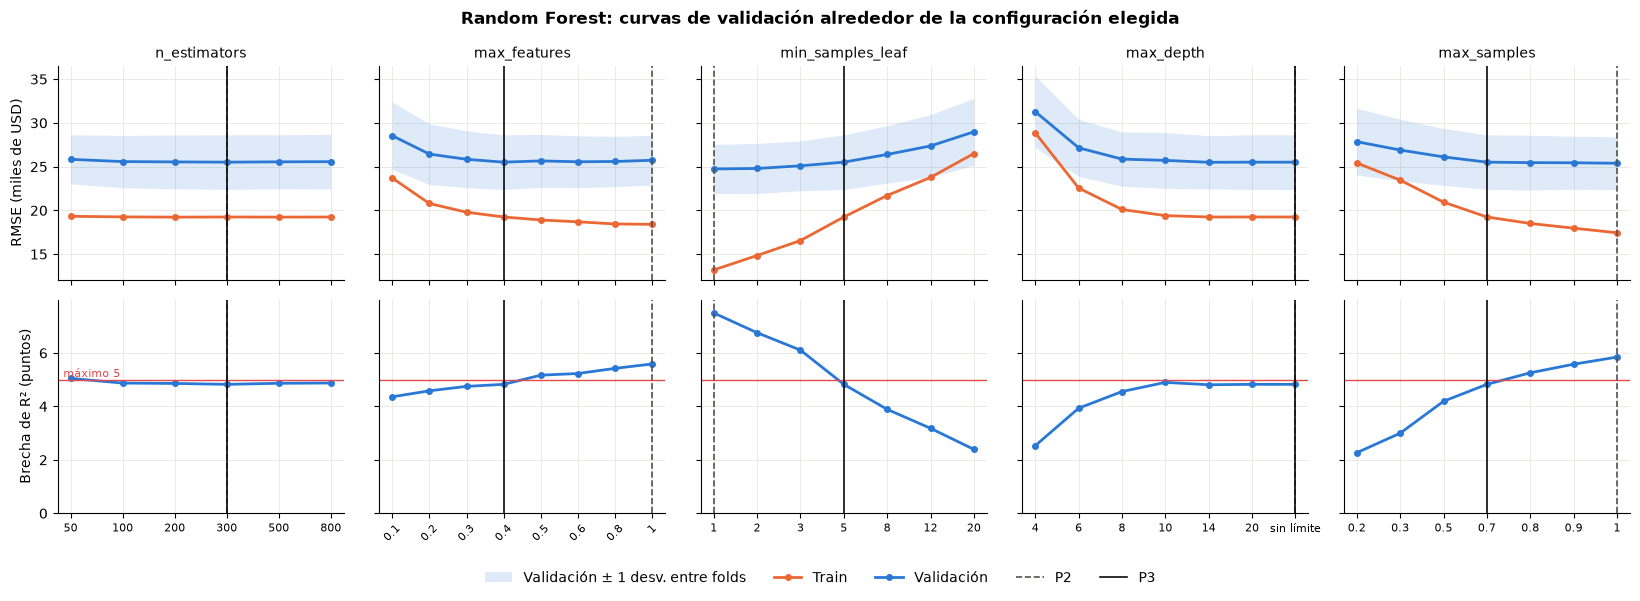

In [76]:
for hp, tabla in curvas_p3['Random Forest'].items():
    print(tabla_curva(tabla, hp).to_string(), end='\n\n')
graficar_curvas(curvas_p3['Random Forest'], 'Random Forest: curvas de validación alrededor de la configuración elegida',
                {'P2': PARAMS_P2['Random Forest'], 'P3': elegidos['Random Forest']['params']}, 'p3_03_rf_curvas_validacion')

- `min_samples_leaf` es donde mejor se ve el sobreajuste. Con hojas de 1 casa en vez de 5, el RMSE de train baja de 19.246 a 13.191 USD y el de validación solo de 25.512 a 24.735: el modelo aprende unos 6.000 USD de detalle de train que casi no sirven en casas nuevas, y la brecha sube a 7,5. El valor elegido, 5, es el menor que cumple (con 3 la brecha es 6,11).
- `max_samples`: 0,7 es el mayor que cumple (con 0,8 la brecha es 5,26). Entre 0,7 y 1,0 el error de validación baja 124 USD y el de train 1.804.
- `max_features`: el mínimo de validación está en 0,4. Con 0,3 el error sube 329 USD; de 0,5 en adelante es parecido (25.556 a 25.729), pero la brecha pasa de 5. Con el valor del P2, 1,0, queda en 5,6.
- `max_depth`: desde 14 el resultado es prácticamente el de sin límite (25.497 contra 25.512). Bajo 8 el modelo queda corto: 27.153 USD con profundidad 6.
- `n_estimators`: entre 100 y 800 árboles el error se mueve 65 USD. Se mantienen los 300 del P2.

### 33.2 XGBoost

max_depth            1      2      3      4      5      6      8
RMSE train       17655  12832  10637  10138   9969   9851   9669
RMSE val         20682  19809  20158  20485  20992  21064  21238
Brecha R² (pts)   2.04   3.95   5.06   5.45   5.87   5.95   6.15

n_estimators       100    200    300    500   1000   1500   2000   3000
RMSE train       25161  20507  18837  17161  15038  13777  12832  11760
RMSE val         26990  23123  21924  20892  19988  19822  19809  19750
Brecha R² (pts)   1.67   1.98   2.18   2.47   3.02   3.53   3.95   4.36

learning_rate     0.01   0.02   0.03   0.05   0.07    0.1    0.2
RMSE train       17706  15671  14401  12832  11971  11198  10328
RMSE val         21430  20466  19949  19809  20128  19990  20873
Brecha R² (pts)   2.53   3.01   3.30   3.95   4.52   4.76   5.67

min_child_weight      1      2      3      5      8     12     20     40
RMSE train        12667  12670  12694  12736  12832  13106  13551  14636
RMSE val          19702  19860  19797  1975

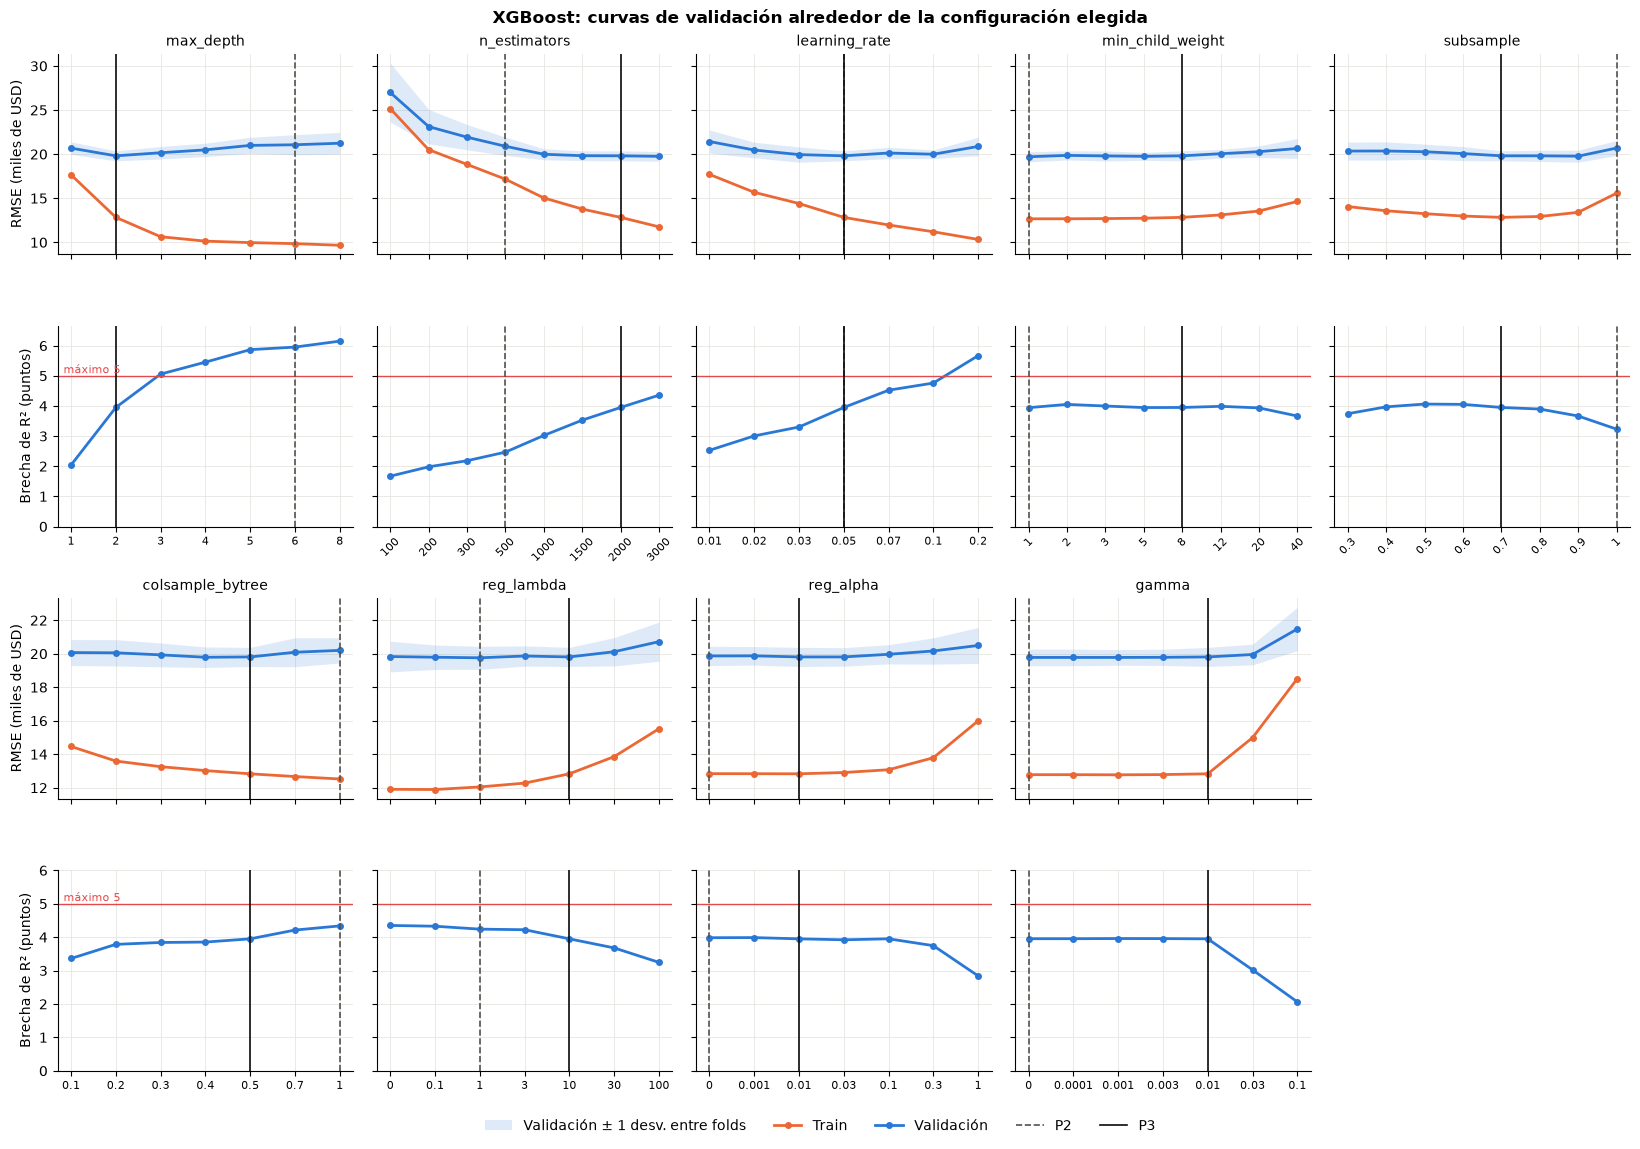

In [77]:
for hp, tabla in curvas_p3['XGBoost'].items():
    print(tabla_curva(tabla, hp).to_string(), end='\n\n')
graficar_curvas(curvas_p3['XGBoost'], 'XGBoost: curvas de validación alrededor de la configuración elegida',
                {'P2': PARAMS_P2['XGBoost'], 'P3': elegidos['XGBoost']['params']}, 'p3_04_xgb_curvas_validacion')

- `max_depth`: el mínimo está en 2 (19.809 USD). Con 1 el modelo queda corto (20.682) y con 3 el error sube a 20.158 y la brecha pasa de 5 (5,06). Desde ahí error y brecha suben juntos: con la profundidad 6 del P2, 21.064 USD y 6,0 puntos.
- `n_estimators`, con tasa 0,05: el error de validación baja rápido hasta 1.000 árboles (19.988) y después queda casi plano (19.822 con 1.500, 19.809 con 2.000 y 19.750 con 3.000). El de train sigue bajando, de 15.038 a 11.760 USD, y la brecha sube de 3,0 a 4,4: los árboles extra aprenden sobre todo detalle de train. Con los 500 del P2 el modelo queda corto (20.892).
- `learning_rate`: el mínimo está en 0,05. Con 0,03 el error sube 140 USD; con 0,2 sube a 20.873 y la brecha pasa de 5 (5,67).
- `subsample`: de 0,7 a 0,9 el error es el mismo (19.770 a 19.809). Sin submuestreo, como en el P2, es mayor: 20.691 USD.
- `colsample_bytree`: zona plana entre 0,3 y 0,5 (19.789 a 19.931); con todas las columnas, como en el P2, 20.201 USD. La brecha queda bajo 5 en todo el rango.
- `gamma` y `reg_lambda`: con `gamma` entre 0 y 0,01 el error es el mismo (19.779 a 19.809) y con 0,1 sube a 21.479. `reg_lambda` entre 0 y 10 da lo mismo (19.756 a 19.863) y desde 30 empeora.
- `min_child_weight` y `reg_alpha` casi no mueven el resultado en la zona elegida: entre 1 y 8 casas por hoja el error se mueve 158 USD sin tendencia, y con `reg_alpha` hasta 0,1 se mueve 157. Solo empeoran en el extremo (20.643 USD con 40 casas, 20.492 con `reg_alpha` 1).
- Con profundidad 2 la brecha deja de ser el límite: queda bajo 5 en casi todas las curvas, salvo con profundidad 3 o más y con tasa 0,2.

## 34. Qué hiperparámetros importan

De cada curva de la sección 33 sacamos tres números: cuánto cambia el RMSE de validación en todo el rango, cuánto cambia entre el valor elegido y sus dos vecinos, y entre qué valores se mueve la brecha. El primero se compara con la desviación entre folds de la configuración elegida.

Cómo se lee, decidido antes de ver la tabla: un hiperparámetro importa si moverlo cambia el RMSE de validación más que la desviación entre folds, o si hace cruzar la brecha de un lado al otro de los 5 puntos. Si el efecto entre vecinos es chico, la zona alrededor del valor elegido es plana y el valor exacto da lo mismo.

In [78]:
def importancia_hiperparametros(nombre):
    e, filas = elegidos[nombre], {}
    for hp, tabla in curvas_p3[nombre].items():
        valores = [p[hp] for p in tabla['params']]
        i = valores.index(e['params'][hp])
        vecinos_inmediatos = tabla['RMSE val'].iloc[max(i - 1, 0):i + 2]
        filas[hp] = {
            'Rango probado': f"{etiqueta(valores[0])} a {etiqueta(valores[-1])}",
            'Efecto en todo el rango (USD)': round(tabla['RMSE val'].max() - tabla['RMSE val'].min()),
            'Efecto / desv. entre folds': round((tabla['RMSE val'].max() - tabla['RMSE val'].min()) / e['Desv. RMSE val'], 1),
            'Efecto entre vecinos del elegido (USD)': round(vecinos_inmediatos.max() - vecinos_inmediatos.min()),
            'Brecha mín. (pts)': round(tabla['Brecha R² (pts)'].min(), 1),
            'Brecha máx. (pts)': round(tabla['Brecha R² (pts)'].max(), 1),
        }
    return pd.DataFrame(filas).T.sort_values('Efecto en todo el rango (USD)', ascending=False)


for nombre in CURVAS:
    print(f"=== {nombre}: efecto en el RMSE de validación de mover un solo hiperparámetro "
          f"(desviación entre folds de la configuración elegida: {elegidos[nombre]['Desv. RMSE val']:,.0f} USD) ===")
    print(importancia_hiperparametros(nombre).to_string())
    print()

=== Random Forest: efecto en el RMSE de validación de mover un solo hiperparámetro (desviación entre folds de la configuración elegida: 3,123 USD) ===
                   Rango probado Efecto en todo el rango (USD) Efecto / desv. entre folds Efecto entre vecinos del elegido (USD) Brecha mín. (pts) Brecha máx. (pts)
max_depth         4 a sin límite                          5787                        1.9                                      0               2.5               4.9
min_samples_leaf          1 a 20                          4244                        1.4                                   1295               2.4               7.5
max_features             0.1 a 1                          3027                        1.0                                    329               4.4               5.6
max_samples              0.2 a 1                          2465                        0.8                                    654               2.3               5.8
n_estimators            

Random Forest (desviación entre folds de 3.123 USD):

- Deciden `min_samples_leaf` y `max_samples`, por la brecha: la mueven entre 2,4 y 7,5 puntos y entre 2,3 y 5,8. `min_samples_leaf` además cambia el error en 4.244 USD en su rango, 1,4 veces la desviación entre folds.
- `max_depth` tiene el mayor efecto en el rango (5.787 USD), pero viene todo de los árboles muy cortos: alrededor del valor elegido el efecto es 0.
- `max_features` mueve 3.027 USD solo por su extremo de 0,1; entre vecinos del elegido mueve 329. `n_estimators` casi no mueve nada: 323 USD en todo el rango, la décima parte de la desviación entre folds.

XGBoost (desviación entre folds de 570 USD):

- `n_estimators` tiene el mayor efecto en el rango (7.240 USD, 12,7 veces la desviación entre folds), pero es el costo de usar muy pocos árboles: entre vecinos del elegido el efecto es de 72 USD.
- `gamma`, `learning_rate`, `max_depth`, `reg_lambda`, `min_child_weight`, `subsample` y `reg_alpha` cambian el error entre 684 y 1.700 USD en sus rangos, siempre por los extremos. `colsample_bytree` queda bajo la desviación entre folds (411 USD).
- Alrededor del valor elegido solo `max_depth` mueve el error más que la desviación entre folds (874 USD: profundidad 1 y 3 son peores que 2). Los demás mueven 320 USD o menos.
- La brecha la mueven sobre todo `max_depth` (2,0 a 6,2 puntos), `learning_rate` (2,5 a 5,7), `n_estimators` (1,7 a 4,4) y `gamma` (2,1 a 4,0).

En los dos modelos importa caer en la zona correcta, no el valor exacto. En XGBoost la zona es árboles poco profundos, suficientes árboles con tasa baja, submuestreo de casas y columnas y `gamma` en centésimas. En Random Forest, hojas y muestras que limiten cuánto memoriza cada árbol.

## 35. Suficiencia de la búsqueda, zona plana y costo de la brecha

### 35.1 ¿Fue suficiente la búsqueda?

Seguimos el mejor RMSE de validación encontrado a medida que se prueban configuraciones, en el orden real: primero las 60 aleatorias, después las grillas. Si la búsqueda alcanzó, la curva se aplana. Se dibuja el mejor entre las que cumplen la brecha (el que usa la regla) y el mejor sin exigirla.

Random Forest: la mejor de la búsqueda aleatoria (25,668 USD) apareció en la configuración 45 de 60; las grillas la bajan a 25,512 USD (156 USD menos, 0.05 desviaciones entre folds). Última mejora: configuración 260 de 359
XGBoost: la mejor de la búsqueda aleatoria (20,348 USD) apareció en la configuración 4 de 60; las grillas la bajan a 19,809 USD (540 USD menos, 0.95 desviaciones entre folds). Última mejora: configuración 195 de 467


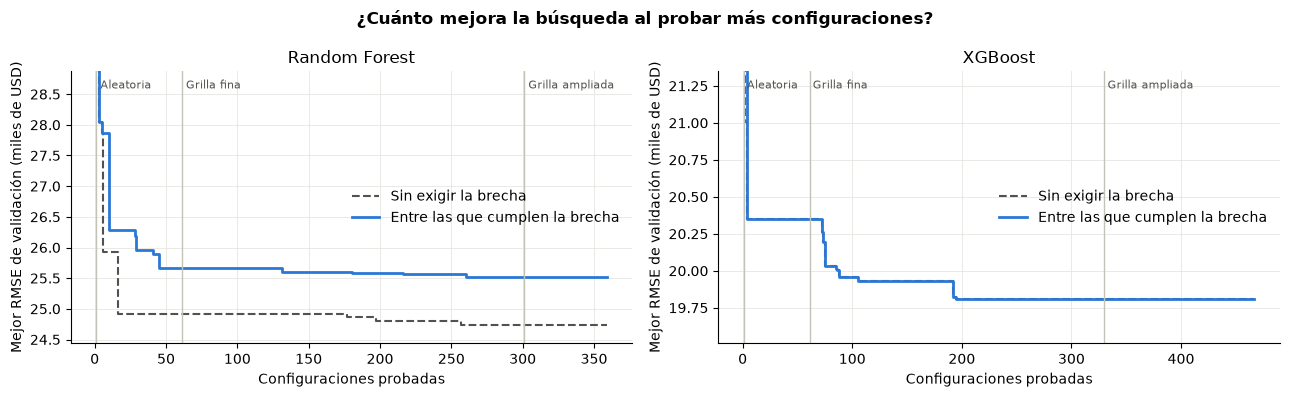

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (nombre, tabla) in zip(axes, busquedas.items()):
    n = np.arange(1, len(tabla) + 1)
    cumple = tabla['Brecha R² (pts)'] <= MAX_BRECHA
    con_regla = tabla['RMSE val'].where(cumple).cummin().ffill() / 1000
    sin_regla = tabla['RMSE val'].cummin() / 1000
    ax.step(n, sin_regla, where='post', color=COLOR_REF, linewidth=1.5, linestyle='--', label='Sin exigir la brecha')
    ax.step(n, con_regla, where='post', color=COLOR_VAL, linewidth=2, label='Entre las que cumplen la brecha')
    for etapa, inicio in tabla.groupby('Etapa', sort=False).apply(lambda g: g.index[0] + 1, include_groups=False).items():
        ax.axvline(inicio, color='#c3c2b7', linewidth=1)
        ax.text(inicio + 3, 0.97, etapa, transform=ax.get_xaxis_transform(), fontsize=8, va='top', color=COLOR_REF)
    ax.set_ylim(sin_regla.min() - 0.3, con_regla.iloc[5] + 1)   # las primeras configuraciones quedan fuera de la escala
    ax.set(title=nombre, xlabel='Configuraciones probadas', ylabel='Mejor RMSE de validación (miles de USD)')
    ax.legend(frameon=False, loc='center right')

    aleatoria = tabla[tabla['Etapa'] == 'Aleatoria']
    mejor_aleatoria = aleatoria.loc[elegir(aleatoria)]
    mejoras = con_regla.diff().lt(0).to_numpy().nonzero()[0] + 1      # posiciones en que baja el mejor RMSE
    print(f"{nombre}: la mejor de la búsqueda aleatoria ({mejor_aleatoria['RMSE val']:,.0f} USD) apareció en la configuración "
          f"{mejoras[mejoras <= len(aleatoria)].max()} de {len(aleatoria)}; las grillas la bajan a {elegidos[nombre]['RMSE val']:,.0f} USD "
          f"({mejor_aleatoria['RMSE val'] - elegidos[nombre]['RMSE val']:,.0f} USD menos, "
          f"{(mejor_aleatoria['RMSE val'] - elegidos[nombre]['RMSE val']) / elegidos[nombre]['Desv. RMSE val']:.2f} desviaciones entre folds). "
          f"Última mejora: configuración {mejoras.max()} de {len(tabla)}")
fig.suptitle('¿Cuánto mejora la búsqueda al probar más configuraciones?', fontsize=12, fontweight='bold')
fig.tight_layout()
guardar_figura(fig, 'p3_05_convergencia_busqueda')
plt.show()

- Random Forest: la mejor aleatoria apareció en la configuración 45 de 60. Las 299 de las grillas la bajaron 156 USD, 0,05 veces la desviación entre folds. La última mejora fue en la configuración 260 de 359.
- XGBoost: la mejor aleatoria apareció en la número 4. Las grillas la bajaron 540 USD (0,95 veces la desviación entre folds) y la última mejora fue en la configuración 195 de 467; las 272 siguientes no encontraron nada mejor.
- En XGBoost la grilla aportó más, como era de esperar con 9 hiperparámetros: 60 sorteos ubican la zona y la grilla la recorre con orden. En los dos modelos, lo ganado después de la búsqueda aleatoria no supera la variación entre folds y las curvas quedaron planas. Seguir buscando no daría una mejora distinguible del ruido.

### 35.2 ¿El óptimo es un punto o una zona plana?

Comparamos las 10 mejores configuraciones que cumplen la brecha y contamos cuántas quedan a menos de una desviación entre folds de la elegida.

In [80]:
for nombre, tabla in busquedas.items():
    e = elegidos[nombre]
    cumplen = tabla[tabla['Brecha R² (pts)'] <= MAX_BRECHA].sort_values('RMSE val')
    top = mostrar(cumplen.head(10), tabla, columnas=('RMSE val', 'Desv. RMSE val', 'Brecha R² (pts)'))
    top['Dif. con la elegida (USD)'] = (cumplen['RMSE val'].head(10) - e['RMSE val']).round(0)
    top['Folds en que la elegida gana'] = [folds_en_que_gana(e, fila) for _, fila in cumplen.head(10).iterrows()]
    print(f"=== {nombre}: las 10 mejores configuraciones que cumplen la brecha ===")
    print(top.to_string(index=False))
    cerca = cumplen[cumplen['RMSE val'] <= e['RMSE val'] + e['Desv. RMSE val']]
    print(f"Configuraciones que cumplen la brecha: {len(cumplen)} de {len(tabla)} | a menos de una desviación entre folds "
          f"({e['Desv. RMSE val']:,.0f} USD) de la elegida: {len(cerca)}")
    rangos = pd.DataFrame(list(cerca['params']), dtype=object)
    print("Valores que toman esas configuraciones:",
          {hp: sorted(rangos[hp].unique(), key=lambda v: (v is None, v)) for hp in rangos if rangos[hp].map(repr).nunique() > 1})
    print()

=== Random Forest: las 10 mejores configuraciones que cumplen la brecha ===
min_samples_leaf max_samples max_features max_depth  RMSE val  Desv. RMSE val  Brecha R² (pts)  Dif. con la elegida (USD)  Folds en que la elegida gana
               5         0.7          0.4      None   25512.0          3123.0              4.8                        0.0                             0
               5         0.6          0.6        12   25574.0          2968.0              4.7                       62.0                             2
               5         0.7          0.4        12   25581.0          3218.0              4.8                       68.0                             4
               3         0.5          0.6         8   25600.0          2805.0              4.8                       87.0                             3
               5         0.6          0.4        12   25607.0          3103.0              4.4                       95.0                             4
            

- Random Forest: las 10 mejores quedan a 156 USD o menos de la elegida, con valores distintos: hojas de 3 a 6 casas, `max_samples` de 0,4 a 0,8, `max_features` de 0,4 a 0,6 y profundidad 8, 12 o sin límite. De las 200 que cumplen la brecha, 180 quedan a menos de una desviación entre folds (3.123 USD).
- XGBoost: las 10 mejores quedan a 177 USD o menos. De las 399 que cumplen, 134 quedan a menos de una desviación entre folds (570 USD), con profundidad de 2 a 4, tasa de 0,03 a 0,1, de 500 a 2.000 árboles y `subsample` de 0,4 a 0,9.
- La elegida tampoco les gana siempre a las siguientes: lo hace en 2 a 4 de los 5 folds según el caso.

El óptimo es una zona plana. La configuración elegida es la representante que indica la regla, y cambiarla por una vecina no cambiaría ninguna conclusión. Por eso los valores finales se defienden por zona (árboles poco profundos, hojas de varias casas) y no por su cifra exacta.

### 35.3 ¿Cuánto cuesta exigir la brecha?

Cada punto del gráfico es una configuración: su brecha en el eje horizontal y su RMSE de validación en el vertical. La línea roja es el máximo de 5 puntos. Están marcados el P2, la configuración elegida y la mejor sin exigir la brecha.

Random Forest: 359 configuraciones (17 quedan sobre el límite superior del gráfico)
  Mejor sin exigir la brecha: 24,735 USD con brecha de 7.5 puntos {'max_depth': None, 'max_features': 0.4, 'max_samples': 0.7, 'min_samples_leaf': 1, 'n_estimators': 300}
  Elegida (cumple la brecha): 25,512 USD con brecha de 4.8 puntos
  Costo de exigir la brecha: 777 USD de RMSE de validación (0.25 desviaciones entre folds); la configuración sin restricción gana en 5 de 5 folds
  Fuera de la búsqueda, la mejor del diagnóstico de la sección 30.2 (el P2 con {'max_features': 0.4}): 24,459 USD con brecha de 8.5 puntos
XGBoost: 467 configuraciones (11 quedan sobre el límite superior del gráfico)
  Mejor sin exigir la brecha: 19,809 USD con brecha de 3.9 puntos {'colsample_bytree': 0.5, 'gamma': 0.01, 'learning_rate': 0.05, 'max_depth': 2, 'min_child_weight': 8, 'n_estimators': 2000, 'reg_alpha': 0.01, 'reg_lambda': 10.0, 'subsample': 0.7}
  Elegida (cumple la brecha): 19,809 USD con brecha de 3.9 puntos
  

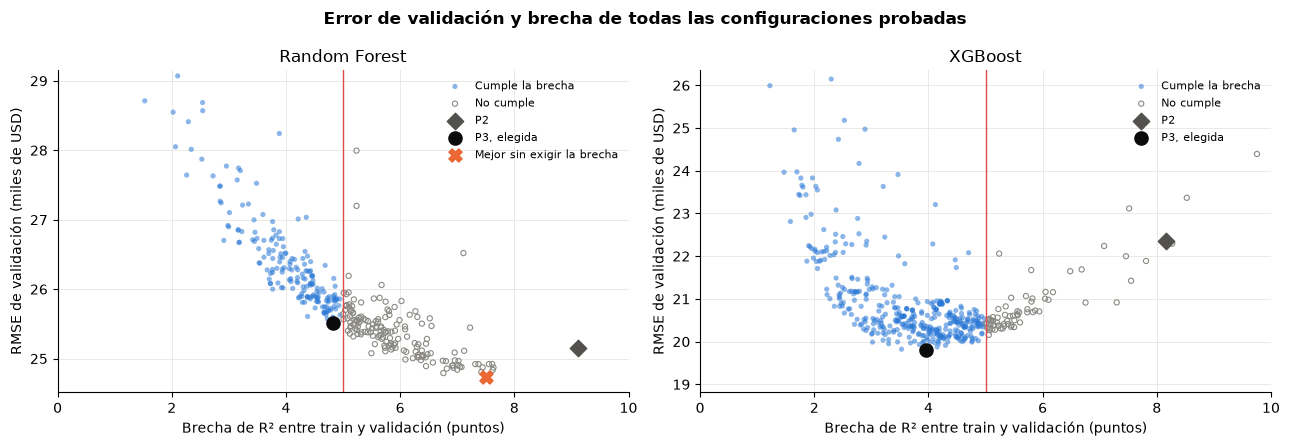

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (nombre, tabla) in zip(axes, busquedas.items()):
    e, p2 = elegidos[nombre], base_p2.loc[nombre]
    libre = tabla.loc[tabla['RMSE val'].idxmin()]        # la mejor sin exigir la brecha
    cumple = tabla['Brecha R² (pts)'] <= MAX_BRECHA
    ax.scatter(tabla.loc[cumple, 'Brecha R² (pts)'], tabla.loc[cumple, 'RMSE val'] / 1000, s=14, color=COLOR_VAL, alpha=0.55,
               edgecolors='none', label='Cumple la brecha')
    ax.scatter(tabla.loc[~cumple, 'Brecha R² (pts)'], tabla.loc[~cumple, 'RMSE val'] / 1000, s=14, facecolors='none',
               edgecolors='#8a8984', linewidths=0.8, label='No cumple')
    ax.axvline(MAX_BRECHA, color='#e34948', linewidth=1)
    ax.scatter(p2['Brecha R² (pts)'], p2['RMSE val'] / 1000, s=70, marker='D', color=COLOR_REF, zorder=3, label='P2')
    ax.scatter(e['Brecha R² (pts)'], e['RMSE val'] / 1000, s=90, marker='o', color='#0b0b0b', zorder=3, label='P3, elegida')
    if libre.name != e.name:
        ax.scatter(libre['Brecha R² (pts)'], libre['RMSE val'] / 1000, s=90, marker='X', color=COLOR_TRAIN, zorder=3,
                   label='Mejor sin exigir la brecha')
    ax.set_ylim(e['RMSE val'] / 1000 - 1, p2['RMSE val'] / 1000 + 4)
    ax.set_xlim(0, max(10, p2['Brecha R² (pts)'] + 0.5))
    ax.set(title=nombre, xlabel='Brecha de R² entre train y validación (puntos)', ylabel='RMSE de validación (miles de USD)')
    ax.legend(frameon=False, fontsize=8, loc='upper right')
    fuera = int((tabla['RMSE val'] / 1000 > ax.get_ylim()[1]).sum())

    print(f"{nombre}: {len(tabla)} configuraciones ({fuera} quedan sobre el límite superior del gráfico)")
    print(f"  Mejor sin exigir la brecha: {libre['RMSE val']:,.0f} USD con brecha de {libre['Brecha R² (pts)']:.1f} puntos {libre['params']}")
    print(f"  Elegida (cumple la brecha): {e['RMSE val']:,.0f} USD con brecha de {e['Brecha R² (pts)']:.1f} puntos")
    print(f"  Costo de exigir la brecha: {e['RMSE val'] - libre['RMSE val']:,.0f} USD de RMSE de validación "
          f"({(e['RMSE val'] - libre['RMSE val']) / e['Desv. RMSE val']:.2f} desviaciones entre folds); "
          f"la configuración sin restricción gana en {folds_en_que_gana(libre, e)} de 5 folds")
    mejor_diag = pd.concat(diagnostico[nombre].values()).sort_values('RMSE val').iloc[0]
    cambio = {k: v for k, v in mejor_diag['params'].items() if v != PARAMS_P2[nombre][k]}
    print(f"  Fuera de la búsqueda, la mejor del diagnóstico de la sección 30.2 (el P2 con {cambio}): "
          f"{mejor_diag['RMSE val']:,.0f} USD con brecha de {mejor_diag['Brecha R² (pts)']:.1f} puntos")
fig.suptitle('Error de validación y brecha de todas las configuraciones probadas', fontsize=12, fontweight='bold')
fig.tight_layout()
guardar_figura(fig, 'p3_06_error_vs_brecha')
plt.show()

- Random Forest: hay un intercambio claro. La nube baja hacia la derecha: para tener menos error de validación el bosque necesita memorizar más. La mejor configuración sin exigir la brecha tiene 24.735 USD con 7,5 puntos (la misma elegida, con hojas de 1 casa). Exigir la brecha cuesta 777 USD, 0,25 veces la desviación entre folds, y esa configuración gana en los 5 folds: el costo es chico pero real. El diagnóstico de la sección 30.2 tuvo una todavía menor fuera de la búsqueda (24.459 USD con 8,5 puntos), así que el costo está entre 777 y 1.053 USD.
- XGBoost: no hay intercambio. La nube tiene forma de U y su mínimo queda a la izquierda de la línea roja: la configuración de menor error de las 467 ya cumple la brecha, así que exigirla cuesta 0 USD. Las de más brecha, como la del P2, también tienen más error.
- Esa diferencia explica el resultado de la sección 37. En XGBoost, regularizar corrige el sobreajuste y además mejora el error. En Random Forest lo corrige a cambio de algo de error.

## 36. Ridge y Lasso

Mismo protocolo con un solo hiperparámetro: `GridSearchCV` sobre `alpha` con los 5 folds y las grillas de 30 valores del P2. Esperábamos poco cambio, porque en el P2 `RidgeCV` y `LassoCV` ya elegían `alpha` con validación cruzada. Lo hacemos para que los cuatro modelos queden ajustados y medidos de la misma forma.

Ridge: alpha = 3.86 (valor 16 de 30 en la grilla; el P2 eligió 8.53) | RMSE val 20,123 USD | brecha 1.1 puntos | brecha máxima de la grilla 1.3
  alphas a menos de 100 USD de RMSE de validación del elegido: de 0.356 a 12.7


Lasso: alpha = 0.000127 (valor 9 de 30 en la grilla; el P2 eligió 0.000174) | RMSE val 20,171 USD | brecha 1.1 puntos | brecha máxima de la grilla 1.2
  alphas a menos de 100 USD de RMSE de validación del elegido: de 1e-05 a 0.00024


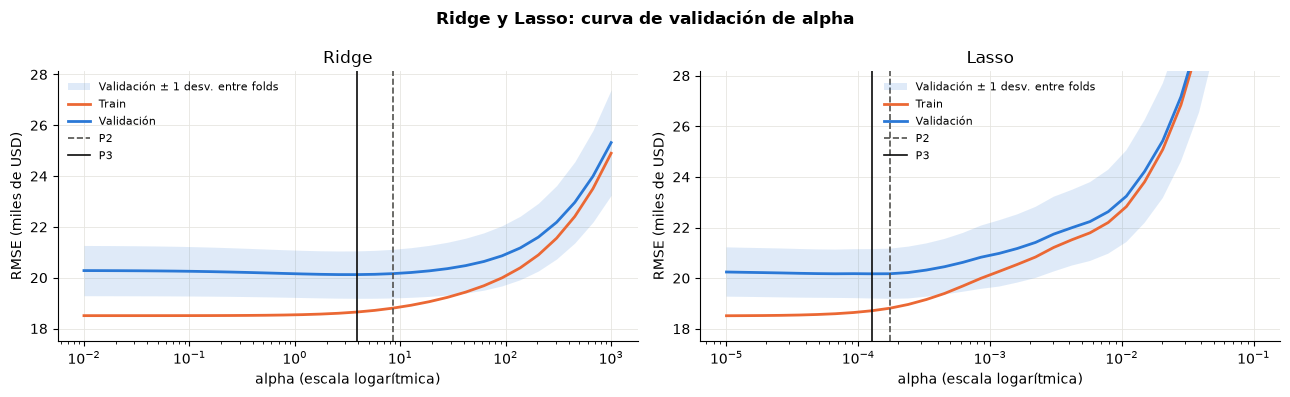

Lasso con el alpha del P3: 111 de 138 columnas con coeficiente distinto de 0 (en el P2: 105)


In [82]:
GRILLA_ALPHA = {'Ridge': np.logspace(-2, 3, 30).tolist(), 'Lasso': np.logspace(-5, -1, 30).tolist()}
ALPHA_P2 = {nombre: float(ajustados[nombre].regressor_.alpha_) for nombre in GRILLA_ALPHA}   # elegido en la sección 23

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (nombre, alphas) in zip(axes, GRILLA_ALPHA.items()):
    tabla = buscar(f'{nombre.lower()}_grilla_alpha', busqueda_grilla(nombre, {'alpha': alphas}))
    busquedas[nombre] = tabla.assign(Etapa='Grilla')
    e = elegidos[nombre] = busquedas[nombre].loc[elegir(busquedas[nombre])]
    alpha = e['params']['alpha']

    val, desv = tabla['RMSE val'] / 1000, tabla['Desv. RMSE val'] / 1000
    ax.fill_between(alphas, val - desv, val + desv, color=COLOR_VAL, alpha=0.15, linewidth=0, label='Validación ± 1 desv. entre folds')
    ax.plot(alphas, tabla['RMSE train'] / 1000, color=COLOR_TRAIN, linewidth=2, label='Train')
    ax.plot(alphas, val, color=COLOR_VAL, linewidth=2, label='Validación')
    ax.axvline(ALPHA_P2[nombre], color=COLOR_REF, linestyle='--', linewidth=1.2, label='P2')
    ax.axvline(alpha, color='#0b0b0b', linewidth=1.2, label='P3')
    ax.set_xscale('log')
    ax.set_ylim(tabla['RMSE train'].min() / 1000 - 1, val.min() + 8)
    ax.set(title=nombre, xlabel='alpha (escala logarítmica)', ylabel='RMSE (miles de USD)')
    ax.legend(frameon=False, fontsize=8)

    posicion = alphas.index(alpha) + 1
    cerca = tabla[tabla['RMSE val'] <= e['RMSE val'] + 100]
    print(f"{nombre}: alpha = {alpha:.3g} (valor {posicion} de {len(alphas)} en la grilla; el P2 eligió {ALPHA_P2[nombre]:.3g}) | "
          f"RMSE val {e['RMSE val']:,.0f} USD | brecha {e['Brecha R² (pts)']:.1f} puntos | "
          f"brecha máxima de la grilla {tabla['Brecha R² (pts)'].max():.1f}")
    print(f"  alphas a menos de 100 USD de RMSE de validación del elegido: de {cerca['params'].map(lambda p: p['alpha']).min():.3g} "
          f"a {cerca['params'].map(lambda p: p['alpha']).max():.3g}")
fig.suptitle('Ridge y Lasso: curva de validación de alpha', fontsize=12, fontweight='bold')
fig.tight_layout()
guardar_figura(fig, 'p3_07_lineales_alpha')
plt.show()

lasso_p3 = pipeline_p3('Lasso').set_params(**{PREFIJO + 'alpha': elegidos['Lasso']['params']['alpha']}).fit(X_train_base, y_train_base)
coeficientes = lasso_p3.regressor_.named_steps['modelo'].coef_
print(f"Lasso con el alpha del P3: {(coeficientes != 0).sum()} de {len(coeficientes)} columnas con coeficiente distinto de 0 "
      f"(en el P2: {(ajustados['Lasso'].regressor_.coef_ != 0).sum()})")

- Ridge: `alpha` = 3,86 (en el P2, 8,53), el valor 16 de los 30 de la grilla. RMSE de validación de 20.123 USD. La curva es plana: todos los `alpha` entre 0,36 y 12,7 quedan a menos de 100 USD.
- Lasso: `alpha` = 0,000127 (en el P2, 0,000174), el valor 9 de 30. RMSE de 20.171 USD. Todos los `alpha` entre 0,00001 y 0,00024 quedan a menos de 100 USD.
- La brecha no pasa de 1,3 puntos en ningún valor, así que la regla se reduce a elegir el menor RMSE.
- El `alpha` cambia respecto del P2 porque cambia la forma de elegirlo: allá `RidgeCV` usaba leave-one-out y `LassoCV` sus propios folds; aquí se usan los mismos 5 folds de los otros modelos. Los dos valores caen en la zona plana.
- Con el `alpha` del P3 Lasso usa 111 de las 138 columnas; con el del P2 usaba 105. Importa para la regla de interpretabilidad y queda anotado en el traspaso.

## 37. Antes y después

Los cuatro modelos con los parámetros del P2 (sección 29) y con los del P3, medidos con el mismo protocolo. La mejora se juzga con el criterio de la sección 28: menor RMSE en promedio y en al menos 4 de los 5 folds.

In [83]:
ORDEN = ['Ridge', 'Lasso', 'Random Forest', 'XGBoost']
filas = []
for nombre in ORDEN:
    p2, p3 = base_p2.loc[nombre], elegidos[nombre]
    for etapa, f in [('P2', p2), ('P3', p3)]:
        filas.append({'Modelo': nombre, 'Etapa': etapa, 'RMSE val': f['RMSE val'], 'Desv. RMSE val': f['Desv. RMSE val'],
                      'MAPE % val': f['MAPE % val'], 'R² train': f['R² train'], 'R² val': f['R² val'],
                      'Brecha R² (pts)': f['Brecha R² (pts)'],
                      '¿Cumple la brecha?': 'Sí' if f['Brecha R² (pts)'] <= MAX_BRECHA else 'No'})
antes_despues = pd.DataFrame(filas).set_index(['Modelo', 'Etapa'])
print("=== Validación cruzada de 5 folds sobre train, pipelines completos: parámetros del P2 y del P3 ===")
print(antes_despues.round(FORMATO).to_string())

cambio = pd.DataFrame({nombre: {
    'Dif. RMSE val, P3 − P2 (USD)': elegidos[nombre]['RMSE val'] - base_p2.loc[nombre, 'RMSE val'],
    'Dif. / desv. entre folds del P2': (elegidos[nombre]['RMSE val'] - base_p2.loc[nombre, 'RMSE val']) / base_p2.loc[nombre, 'Desv. RMSE val'],
    'Folds en que mejora (de 5)': folds_en_que_gana(elegidos[nombre], base_p2.loc[nombre]),
    'Dif. brecha (pts)': elegidos[nombre]['Brecha R² (pts)'] - base_p2.loc[nombre, 'Brecha R² (pts)'],
} for nombre in ORDEN}).T
cambio['¿Mejora real del RMSE?'] = np.where((cambio['Dif. RMSE val, P3 − P2 (USD)'] < 0)
                                            & (cambio['Folds en que mejora (de 5)'] >= MIN_FOLDS), 'Sí', 'No')
print("\n=== Cambio del P2 al P3 ===")
print(cambio.round({'Dif. RMSE val, P3 − P2 (USD)': 0, 'Dif. / desv. entre folds del P2': 2, 'Dif. brecha (pts)': 1})
      .astype({'Folds en que mejora (de 5)': int}).to_string())

lasso = elegidos['Lasso']
print("\n=== P3: cada modelo frente a Lasso (tolerancia de la regla 3: 1 punto de R² de validación) ===")
for nombre in ['Ridge', 'Random Forest', 'XGBoost']:
    e = elegidos[nombre]
    print(f"{nombre:14s} R² val {e['R² val']:.4f} vs {lasso['R² val']:.4f}: {(e['R² val'] - lasso['R² val']) * 100:+.2f} puntos | "
          f"RMSE val {e['RMSE val'] - lasso['RMSE val']:+,.0f} USD | gana a Lasso en {folds_en_que_gana(e, lasso)} de 5 folds")
print("\nRMSE de validación por fold (USD):")
print(pd.DataFrame({nombre: elegidos[nombre]['RMSE val por fold'] for nombre in ORDEN},
                   index=[f'Fold {i + 1}' for i in range(5)]).round(0).T.to_string())

=== Validación cruzada de 5 folds sobre train, pipelines completos: parámetros del P2 y del P3 ===
                     RMSE val  Desv. RMSE val  MAPE % val  R² train  R² val  Brecha R² (pts) ¿Cumple la brecha?
Modelo        Etapa                                                                                            
Ridge         P2      20159.0           996.0        8.06     0.940   0.930              1.0                 Sí
              P3      20123.0           933.0        8.07     0.941   0.930              1.1                 Sí
Lasso         P2      20199.0          1032.0        8.08     0.939   0.930              1.0                 Sí
              P3      20171.0           976.0        8.09     0.940   0.930              1.1                 Sí
Random Forest P2      25151.0          2527.0        9.22     0.982   0.891              9.1                 No
              P3      25512.0          3123.0        9.21     0.937   0.889              4.8                 Sí
XGBoo

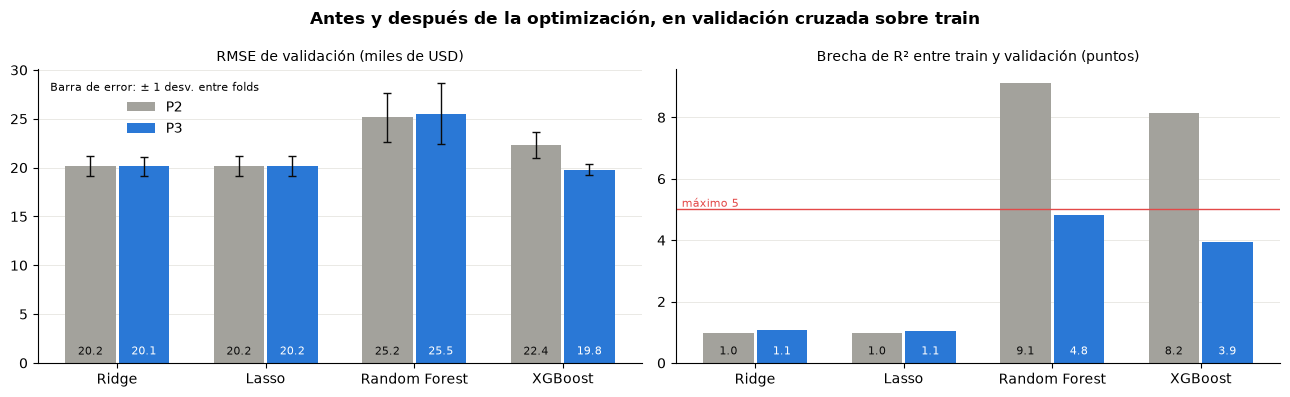

In [84]:
COLOR_P2 = '#a3a29c'
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x, ancho = np.arange(len(ORDEN)), 0.34
for ax, columna, titulo in [(axes[0], 'RMSE val', 'RMSE de validación (miles de USD)'), (axes[1], 'Brecha R² (pts)', 'Brecha de R² entre train y validación (puntos)')]:
    escala = 1000 if columna == 'RMSE val' else 1
    for desplazamiento, etapa, color in [(-ancho / 2 - 0.01, 'P2', COLOR_P2), (ancho / 2 + 0.01, 'P3', COLOR_VAL)]:
        valores = antes_despues.xs(etapa, level='Etapa').loc[ORDEN, columna] / escala
        barras = ax.bar(x + desplazamiento, valores, ancho, color=color, label=etapa)
        if columna == 'RMSE val':
            desv = antes_despues.xs(etapa, level='Etapa').loc[ORDEN, 'Desv. RMSE val'] / escala
            ax.errorbar(x + desplazamiento, valores, yerr=desv, fmt='none', ecolor='#0b0b0b', elinewidth=1, capsize=3)
        for barra, valor in zip(barras, valores):
            ax.text(barra.get_x() + barra.get_width() / 2, 0.02 * ax.get_ylim()[1], f'{valor:.1f}', ha='center', va='bottom',
                    fontsize=8, color='white' if etapa == 'P3' else '#0b0b0b')
    ax.set_xticks(x, ORDEN)
    ax.set_title(titulo, fontsize=10)
    ax.grid(axis='x', visible=False)
axes[1].axhline(MAX_BRECHA, color='#e34948', linewidth=1)
axes[1].text(0.01, MAX_BRECHA, f'máximo {MAX_BRECHA:g}', color='#e34948', fontsize=8, va='bottom', transform=axes[1].get_yaxis_transform())
axes[0].legend(frameon=False, title='Barra de error: ± 1 desv. entre folds', title_fontsize=8)
fig.suptitle('Antes y después de la optimización, en validación cruzada sobre train', fontsize=12, fontweight='bold')
fig.tight_layout()
guardar_figura(fig, 'p3_08_antes_despues')
plt.show()

Qué cambió:

- XGBoost es el único con una mejora real: el RMSE de validación baja de 22.351 a 19.809 USD (2.542 menos, 1,9 veces la desviación entre folds del P2) y mejora en los 5 folds. El MAPE baja de 8,39 % a 7,80 %, la brecha de 8,2 a 3,9 puntos y la desviación entre folds de 1.350 a 570 USD.
- Random Forest pasa a cumplir la brecha (de 9,1 a 4,8), pero su error no mejora: sube 362 USD, de 25.151 a 25.512, y mejora en un solo fold. Dejó de memorizar train (R² de train de 0,982 a 0,937) sin predecir mejor las casas nuevas.

Qué no cambió:

- Ridge y Lasso: 36 y 28 USD menos, con mejora en 3 y 2 folds. Su `alpha` ya estaba bien elegido en el P2.
- Random Forest sigue lejos: 4,1 puntos de R² de validación bajo Lasso y peor que Lasso en los 5 folds.

Cómo queda la comparación:

- XGBoost (19.809 USD), Ridge (20.123) y Lasso (20.171) quedan dentro de 362 USD, menos que la variación entre folds de esos tres modelos (570 a 976 USD).
- XGBoost supera a Lasso por 0,27 puntos de R² de validación (0,9324 contra 0,9297) y le gana en 3 de 5 folds. La regla 3 de la sección 20 pide 1 punto.

Lectura de los escenarios de la sección 28, sin haber usado el test:

- (b) es el más probable: XGBoost ya cumple la brecha en validación, pero supera a Lasso por 0,27 puntos, lejos del punto que exige la regla. Se mantendría Lasso.
- (a) no se puede descartar del todo: Random Forest cumple la brecha con muy poco margen (4,8 de un máximo de 5), y el KPI se mide en test con el modelo entrenado con todo train. XGBoost tiene más holgura (3,9).
- (c) no parece posible con estos cuatro modelos, porque el R² de validación ya está medido y la diferencia es de 0,27 puntos. Solo un ensamble que supere a Lasso por más de 1 punto podría darlo.

En (a) y en (b) el modelo elegido seguiría siendo Lasso. Lo que cambia respecto del P2 es la razón: XGBoost ya no queda fuera por sobreajustar y equivocarse más, sino que queda casi empatado con Lasso y pierde por interpretabilidad.

## 38. Tabla final de hiperparámetros

La celda siguiente lista el valor del P2 y el del P3 de cada hiperparámetro. La tabla de abajo agrega qué controla cada uno y qué evidencia respalda el valor.

In [85]:
params_p2 = {**PARAMS_P2, 'Ridge': {'alpha': ALPHA_P2['Ridge']}, 'Lasso': {'alpha': ALPHA_P2['Lasso']}}
filas = [{'Modelo': nombre, 'Hiperparámetro': hp, 'P2': etiqueta(params_p2[nombre][hp]), 'P3': etiqueta(elegidos[nombre]['params'][hp]),
          '¿Cambió?': 'Sí' if params_p2[nombre][hp] != elegidos[nombre]['params'][hp] else 'No'}
         for nombre in ORDEN for hp in params_p2[nombre]]
print(pd.DataFrame(filas).to_string(index=False))

       Modelo   Hiperparámetro          P2          P3 ¿Cambió?
        Ridge            alpha     8.53168     3.85662       Sí
        Lasso            alpha 0.000174333 0.000126896       Sí
Random Forest     n_estimators         300         300       No
Random Forest     max_features           1         0.4       Sí
Random Forest min_samples_leaf           1           5       Sí
Random Forest        max_depth  sin límite  sin límite       No
Random Forest      max_samples           1         0.7       Sí
      XGBoost     n_estimators         500        2000       Sí
      XGBoost    learning_rate        0.05        0.05       No
      XGBoost        max_depth           6           2       Sí
      XGBoost min_child_weight           1           8       Sí
      XGBoost        subsample           1         0.7       Sí
      XGBoost colsample_bytree           1         0.5       Sí
      XGBoost       reg_lambda           1          10       Sí
      XGBoost        reg_alpha          

| Modelo | Hiperparámetro | P2 | P3 | Qué controla | Evidencia |
|---|---|---|---|---|---|
| Ridge | `alpha` | 8,53 | 3,86 | Fuerza de la penalización L2 | Sección 36: mínimo de validación, al interior de la grilla. Entre 0,36 y 12,7 el RMSE cambia menos de 100 USD, así que el valor del P2 es equivalente |
| Lasso | `alpha` | 0,000174 | 0,000127 | Fuerza de la penalización L1 y cuántas columnas quedan en 0 | Sección 36: mínimo de validación. Entre 0,00001 y 0,00024 el RMSE cambia menos de 100 USD. Usa 111 columnas en vez de 105 |
| Random Forest | `n_estimators` | 300 | 300 | Árboles que se promedian | Sección 33.1: entre 100 y 800 árboles el RMSE se mueve 65 USD y la brecha no cambia (en el diagnóstico de la sección 30.2, entre 300 y 800 se mueve 42) |
| Random Forest | `max_features` | 1,0 | 0,4 | Columnas candidatas en cada corte | Sección 33.1: mínimo de validación en 0,4; de 0,5 en adelante la brecha pasa de 5 |
| Random Forest | `min_samples_leaf` | 1 | 5 | Casas mínimas por hoja | Sección 33.1: el menor valor que cumple la brecha (6,11 puntos con 3). Con hojas más chicas baja el error de train y casi no el de validación |
| Random Forest | `max_depth` | Sin límite | Sin límite | Niveles de cada árbol | Sección 33.1: desde profundidad 14 el resultado casi no cambia; con hojas de 5 casas el árbol ya queda acotado |
| Random Forest | `max_samples` | 1,0 | 0,7 | Casas de train que recibe cada árbol | Sección 33.1: el mayor valor que cumple la brecha (5,26 puntos con 0,8) |
| XGBoost | `max_depth` | 6 | 2 | Profundidad de cada árbol | Sección 33.2: mínimo de validación en 2; con 1 el error sube 873 USD y con 3 la brecha pasa de 5 |
| XGBoost | `n_estimators` | 500 | 2.000 | Árboles que se suman | Sección 33.2: el error baja hasta unos 1.000 árboles y queda casi plano (3.000 árboles mejoran solo 58 USD); con 500 el modelo queda corto |
| XGBoost | `learning_rate` | 0,05 | 0,05 | Cuánto corrige cada árbol | Sección 33.2: mínimo de validación en 0,05; con 0,2 la brecha llega a 5,67 |
| XGBoost | `subsample` | 1,0 | 0,7 | Casas que usa cada árbol | Sección 33.2: de 0,7 a 0,9 el error es el mismo; sin submuestreo sube 882 USD |
| XGBoost | `colsample_bytree` | 1,0 | 0,5 | Columnas que usa cada árbol | Sección 33.2: zona plana entre 0,3 y 0,5; con todas las columnas el error sube 392 USD |
| XGBoost | `min_child_weight` | 1 | 8 | Casas mínimas por hoja | Sección 33.2: entre 1 y 8 el error se mueve 158 USD sin tendencia. Viene de la búsqueda aleatoria y es equivalente al del P2 |
| XGBoost | `reg_lambda` | 1 | 10 | Penalización L2 de las hojas | Sección 33.2: entre 0 y 10 el resultado es equivalente (107 USD de diferencia); desde 30 el error sube |
| XGBoost | `reg_alpha` | 0 | 0,01 | Penalización L1 de las hojas | Sección 33.2: hasta 0,1 el error se mueve 157 USD. No aporta ni resta |
| XGBoost | `gamma` | 0 | 0,01 | Ganancia mínima para cortar | Sección 33.2: mismo error que con 0 (30 USD de diferencia). Con 0,03 el error sube y con 0,1 llega a 21.479 USD |

Pesan pocos valores. En XGBoost, la profundidad baja (2) con muchos árboles, tasa baja y submuestreo de casas. En Random Forest, las hojas de 5 casas y el 70 % de la muestra por árbol. El resto está en zonas planas, donde el valor del P3 y el del P2 dan lo mismo.

## 39. Guardado y función para construir los modelos

`models/mejores_params.json` guarda la configuración elegida de cada modelo, sus métricas de validación cruzada, las del P2 con el mismo protocolo y las versiones de las librerías. Las búsquedas ya están en `models/busquedas/` y las figuras en `images/`.

In [86]:
def metricas_json(f):
    return {'rmse_val': round(float(f['RMSE val']), 1), 'desv_rmse_val': round(float(f['Desv. RMSE val']), 1),
            'mae_val': round(float(f['MAE val']), 1), 'mape_val_pct': round(float(f['MAPE % val']), 3),
            'rmse_train': round(float(f['RMSE train']), 1), 'r2_train': round(float(f['R² train']), 4),
            'r2_val': round(float(f['R² val']), 4), 'brecha_r2_pts': round(float(f['Brecha R² (pts)']), 2),
            'rmse_val_por_fold': [round(float(v), 1) for v in f['RMSE val por fold']]}


mejores = {
    'descripcion': 'Hiperparámetros elegidos en la parte 3 (secciones 28 a 40 de Housing_Prices_ML_P3.ipynb). '
                   'Las métricas son de validación cruzada sobre train; el test no se usó.',
    'protocolo': {'datos': f'X_train_base, {len(X_train_base)} casas sin codificar; el pipeline completo se ajusta en cada fold',
                  'cv': f'KFold(n_splits={cv.get_n_splits()}, shuffle=True, random_state={RANDOM_STATE})',
                  'regla': f'entre las configuraciones con brecha de R² train-validación <= {MAX_BRECHA:g} puntos, la de menor RMSE de validación',
                  'target': 'log1p(SalePrice) con TransformedTargetRegressor; métricas en USD'},
    'versiones': {'python': sys.version.split()[0], 'numpy': np.__version__, 'pandas': pd.__version__,
                  'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__},
    'modelos': {nombre: {'params': elegidos[nombre]['params'], 'metricas_cv': metricas_json(elegidos[nombre]),
                         'configuraciones_probadas': int(len(busquedas[nombre])),
                         'params_p2': params_p2[nombre], 'metricas_cv_p2': metricas_json(base_p2.loc[nombre])}
                for nombre in ORDEN},
}
RUTA_PARAMS.write_text(json.dumps(mejores, indent=2, ensure_ascii=False))
print(f"Guardado: {RUTA_PARAMS}")
archivos = sorted(RUTA_BUSQUEDAS.rglob('*.json'))
segundos = sum(json.loads(a.read_text())['segundos'] for a in archivos)
print(f"Búsquedas guardadas en {RUTA_BUSQUEDAS}: {len(archivos)} archivos; repetirlas todas tomó {segundos / 60:.0f} minutos "
      f"en el equipo donde se ejecutaron")
print(f"Figuras guardadas en {RUTA_IMAGENES}: {sorted(p.name for p in RUTA_IMAGENES.glob('p3_*.png'))}")

Guardado: ..\models\mejores_params.json
Búsquedas guardadas en ..\models\busquedas: 36 archivos; repetirlas todas tomó 18 minutos en el equipo donde se ejecutaron
Figuras guardadas en ..\images: ['p3_01_rf_diagnostico.png', 'p3_02_xgb_diagnostico.png', 'p3_03_rf_curvas_validacion.png', 'p3_04_xgb_curvas_validacion.png', 'p3_05_convergencia_busqueda.png', 'p3_06_error_vs_brecha.png', 'p3_07_lineales_alpha.png', 'p3_08_antes_despues.png']


`construir_modelo_p3(nombre)` lee ese archivo y devuelve el pipeline completo, sin entrenar, con los hiperparámetros del P3. Es lo que usa la parte 4: se puede entrenar con `fit`, pasar a `cross_validate` o usar como base de un ensamble. La celda comprueba que los cuatro modelos construidos así reproducen las métricas guardadas.

In [87]:
def construir_modelo_p3(nombre, n_jobs=1, ruta=RUTA_PARAMS):
    params = json.loads(Path(ruta).read_text())['modelos'][nombre]['params']
    modelo = pipeline_p3(nombre).set_params(**{PREFIJO + hp: valor for hp, valor in params.items()})
    if nombre in ('Random Forest', 'XGBoost'):
        modelo.set_params(**{PREFIJO + 'n_jobs': n_jobs})
    return modelo


guardado = json.loads(RUTA_PARAMS.read_text())
for nombre in ORDEN:
    res = cross_validate(construir_modelo_p3(nombre), X_train_base, y_train_base, cv=cv, scoring=metricas,
                         return_train_score=True, n_jobs=-1)
    rmse, brecha = -res['test_rmse'].mean(), (res['train_r2'].mean() - res['test_r2'].mean()) * 100
    esperado = guardado['modelos'][nombre]['metricas_cv']
    print(f"Control {nombre}: {rmse - esperado['rmse_val']:+.1f} USD | brecha {brecha - esperado['brecha_r2_pts']:+.3f}")
    print(f"{nombre:14s} RMSE val {rmse:,.0f} USD | brecha {brecha:.1f} puntos | {guardado['modelos'][nombre]['params']}")
print("Las cuatro configuraciones reproducen las métricas guardadas en mejores_params.json.")

Control Ridge: +0.0 USD | brecha +0.001
Ridge          RMSE val 20,123 USD | brecha 1.1 puntos | {'alpha': 3.856620421163472}


Control Lasso: +0.0 USD | brecha +0.005
Lasso          RMSE val 20,171 USD | brecha 1.1 puntos | {'alpha': 0.0001268961003167922}


Control Random Forest: -0.0 USD | brecha -0.005
Random Forest  RMSE val 25,512 USD | brecha 4.8 puntos | {'max_depth': None, 'max_features': 0.4, 'max_samples': 0.7, 'min_samples_leaf': 5, 'n_estimators': 300}


Control XGBoost: +0.0 USD | brecha -0.000
XGBoost        RMSE val 19,809 USD | brecha 3.9 puntos | {'colsample_bytree': 0.5, 'gamma': 0.01, 'learning_rate': 0.05, 'max_depth': 2, 'min_child_weight': 8, 'n_estimators': 2000, 'reg_alpha': 0.01, 'reg_lambda': 10.0, 'subsample': 0.7}
Las cuatro configuraciones reproducen las métricas guardadas en mejores_params.json.


## 40. Traspaso

Qué se decidió:

- Protocolo de la sección 28: mismos datos, folds y métricas del P2, pipeline completo dentro de cada fold y test sin usar. Cada modelo queda con la configuración de menor RMSE de validación entre las de brecha de R² de hasta 5 puntos.
- Método: búsqueda aleatoria de 60 configuraciones, grilla fina, ampliación cuando la mejor quedó en un borde y curvas de validación como evidencia. Se probaron 359 configuraciones en Random Forest, 467 en XGBoost y 30 valores de `alpha` en Ridge y en Lasso.

Configuración ganadora de cada modelo (validación cruzada de 5 folds sobre train):

| Modelo | Configuración del P3 | RMSE val. | Brecha | Respecto del P2 |
|---|---|---|---|---|
| Ridge | `alpha` 3,86 | 20.123 USD | 1,1 | Sin cambio real (−36 USD) |
| Lasso | `alpha` 0,000127 | 20.171 USD | 1,1 | Sin cambio real (−28 USD) |
| Random Forest | 300 árboles, `max_features` 0,4, `min_samples_leaf` 5, `max_samples` 0,7, sin límite de profundidad | 25.512 USD | 4,8 | Cumple la brecha (antes 9,1); el error no mejora (+362 USD) |
| XGBoost | 2.000 árboles de profundidad 2, tasa 0,05, `subsample` 0,7, `colsample_bytree` 0,5, `min_child_weight` 8, `reg_lambda` 10, `reg_alpha` 0,01, `gamma` 0,01 | 19.809 USD | 3,9 | Cumple la brecha (antes 8,2) y baja 2.542 USD, en los 5 folds |

Qué queda disponible:

- `construir_modelo_p3(nombre, n_jobs=1)`: cada uno de los cuatro modelos ajustados, sin entrenar.
- `models/mejores_params.json`: configuraciones, métricas de validación del P2 y del P3 y versiones.
- `models/busquedas/`: resultados por fold de todas las configuraciones probadas, que `buscar()` carga.
- `elegidos`, `base_p2` y `busquedas`: las mismas tablas en memoria. `X_train_base`, `y_train_base`, `cv` y `metricas` siguen siendo los del P2.
- `images/p3_01` a `p3_08`: las figuras de esta parte.

Qué queda para la parte 4: medir el aporte del bagging y del boosting, probar votación y stacking, evaluar la generalización, abrir el test una vez con los seis KPI y los dos escenarios de venta, y elegir el modelo con los escenarios (a), (b) y (c).

Advertencias:

1. El RMSE de validación de la configuración ganadora puede ser optimista: se eligió como la mejor entre cientos evaluadas con los mismos 5 folds, y parte de su ventaja puede ser suerte con esas particiones. Afecta sobre todo a XGBoost (467 configuraciones) y casi nada a Ridge y Lasso. La parte 4 lo mide con folds nuevos y con validación cruzada anidada.
2. La brecha de Random Forest cumple con poco margen (4,8 de un máximo de 5). La de XGBoost tiene más holgura (3,9). En test, con el modelo entrenado con todo train, puede dar distinto.
3. XGBoost supera a Lasso por 0,27 puntos de R² de validación y le gana en 3 de 5 folds, lejos del punto de la regla 3. El escenario (b) es el más probable (sección 37).
4. Con el `alpha` del P3 Lasso usa 111 columnas; con el del P2, 105. Los dos son equivalentes en error, así que si en la selección pesa la interpretabilidad se puede justificar el `alpha` del P2.
5. En las curvas de XGBoost, `min_child_weight` = 1 dio 107 USD menos que el valor elegido y 3.000 árboles 58 menos, los dos en 4 de 5 folds. No se adoptaron porque son mucho menores que la variación entre folds (570 USD, sección 33).
6. La configuración ganadora de XGBoost no es estable entre sistemas: en Linux ganó profundidad 3 con 1.500 árboles, tasa 0,05, `subsample` 0,7 y `colsample_bytree` 0,3, que aquí da 19.998 USD, 189 más. Las dos están en la misma zona plana (sección 35.2) y ninguna conclusión depende de cuál quede primera.
7. Repetir las búsquedas (`REPETIR_BUSQUEDAS = True`, o ejecutar sin `models/busquedas/`) tomó 18 minutos con 12 núcleos; en Colab, con 2 núcleos, tarda varias veces más. La celda de entorno exige las versiones exactas de `requirements.txt`.
8. Paralelismo en un solo nivel: `construir_modelo_p3` deja los árboles en 1 hilo, pensado para usarlo dentro de `cross_validate`, una búsqueda o un ensamble con `n_jobs`. Para entrenar un modelo solo, usar `n_jobs=-1`.
9. La codificación de las variables no entró a la búsqueda (punto 2 de la sección 18). La tabla de la sección 22 no es comparable con esta parte porque se calculó sobre los CSV codificados; el "antes" correcto es la sección 29.
10. Para interpretar Random Forest o XGBoost, usar importancia por permutación y no la de impureza (punto 5 de la sección 18).

# Parte 4: ensambles, generalización y selección final

La parte 3 dejó cada modelo con su mejor configuración y una conclusión provisoria: XGBoost ya no sobreajusta, pero queda casi empatado con Lasso (sección 37). Esta parte responde lo que falta de la EP3:

- IE10: ¿los ensambles mejoran el modelo? Medimos qué aporta promediar árboles (Random Forest), sumarlos (XGBoost) y combinar Lasso con XGBoost, y si alguno supera a Lasso lo suficiente para justificar perder interpretabilidad.
- IE11: ¿el error medido es el que tendrá el modelo con casas nuevas? Lo revisamos con folds que la búsqueda no vio, validación cruzada anidada, curvas de aprendizaje y, al final, el test.
- IE12: ¿qué modelo se elige, por qué y cómo lo usa un tasador?

Los cálculos se guardan en `models/parte4/` y se cargan si ya existen (interruptor `REPETIR_PARTE4`).

## 41. Protocolo de la parte 4

Lo fijamos antes de ejecutar, igual que el de la sección 28.

Datos, folds y métricas: los de la parte 3. `X_train_base` (2.314 casas sin codificar), el mismo `cv` de 5 folds, el target en log con `con_log`, métricas en dólares y el pipeline completo dentro de cada fold. Nada se calcula sobre los CSV codificados.

El test sigue cerrado hasta la sección 48 y se abre una sola vez, para todos los candidatos a la vez. Las secciones 50 y 51 usan lo que guardó esa celda y no toman decisiones con el test.

Cómputo: paralelismo en un solo nivel. `cross_validate(..., n_jobs=-1)` reparte los folds y cada modelo usa 1 hilo, que es más rápido y evita que el resultado dependa del número de hilos.

Cambio real: un modelo mejora a otro si tiene menor RMSE de validación en promedio, en al menos 4 de los 5 folds y por más que la desviación entre folds del modelo de referencia (de 570 a 3.123 USD en la parte 3). Una diferencia menor es ruido.

Lista cerrada de candidatos para el test: Ridge, Lasso, Lasso con el `alpha` del P2, Random Forest, XGBoost, votación y stacking. El Lasso con el `alpha` del P2 entra por la advertencia 4 de la sección 40: tiene el mismo error que el del P3 (3 USD de diferencia) con 105 columnas en vez de 111. Lo decide la regla de interpretabilidad, no una mirada al test.

Orden de interpretabilidad (extiende la regla 3 de la sección 20), en `NIVEL_INTERPRETABILIDAD` y `complejidad_p4`:

| Nivel | Modelos | Desempate | Por qué |
|---|---|---|---|
| 0 | Lineales (Ridge, Lasso) | Columnas en uso | Cada estimación es una suma de aportes por variable (sección 26) |
| 2 | Ensambles de árboles (Random Forest, XGBoost) | Ninguno | Cientos o miles de árboles: sin desglose directo por casa, hace falta SHAP |
| 3 | Combinaciones de modelos (votación, stacking) | Modelos combinados | Combinan un lineal con un ensamble de árboles y heredan la opacidad del más complejo |

Escenarios de la sección 28, sin cambios: (a) los ensambles no cumplen el criterio de salida en test y se mantiene Lasso; (b) cumplen, pero no superan a Lasso por más de 1 punto de R² de validación, y se mantiene un lineal por interpretabilidad; (c) cumplen y superan a Lasso por más de 1 punto, y cambia el modelo.

In [88]:
import datetime
import joblib
from sklearn.ensemble import VotingRegressor, StackingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RepeatedKFold, learning_curve

REPETIR_PARTE4 = False
RUTA_PARTE4 = Path('../models/parte4')
RUTA_PARTE4.mkdir(parents=True, exist_ok=True)

CV_NUEVOS = RepeatedKFold(n_splits=5, n_repeats=3, random_state=2024)

CANDIDATOS = ['Ridge', 'Lasso', 'Lasso (alpha P2)', 'Random Forest', 'XGBoost', 'Votación', 'Stacking']
ARCHIVO = {'Ridge': 'ridge', 'Lasso': 'lasso', 'Lasso (alpha P2)': 'lasso_alpha_p2',
           'Random Forest': 'rf', 'XGBoost': 'xgb', 'Votación': 'votacion', 'Stacking': 'stacking'}

NIVEL_INTERPRETABILIDAD = {'Ridge': 0, 'Lasso': 0, 'Lasso (alpha P2)': 0,
                           'Random Forest': 2, 'XGBoost': 2, 'Votación': 3, 'Stacking': 3}
TIPO = {0: 'lineal', 2: 'ensamble de árboles', 3: 'combinación de modelos'}


def es_cambio_real(a, b):
    diferencia = b['RMSE val'] - a['RMSE val']
    return bool(diferencia > 0 and folds_en_que_gana(a, b) >= MIN_FOLDS and diferencia > b['Desv. RMSE val'])


def calcular_o_cargar(nombre_archivo, calcular):
    archivo = RUTA_PARTE4 / f'{nombre_archivo}.json'
    if REPETIR_PARTE4 or not archivo.exists():
        archivo.parent.mkdir(parents=True, exist_ok=True)
        inicio = time.time()
        contenido = calcular()
        contenido['segundos'] = round(time.time() - inicio, 1)
        archivo.write_text(json.dumps(contenido, indent=1, ensure_ascii=False), encoding='utf-8')
    return json.loads(archivo.read_text(encoding='utf-8'))


def evaluar_cv(nombre_archivo, construir, folds=cv):
    def calcular():
        res = cross_validate(construir(), X_train_base, y_train_base, cv=folds, scoring=metricas,
                             return_train_score=True, n_jobs=-1)
        return {'folds': repr(folds), 'rmse_train': (-res['train_rmse']).round(2).tolist(),
                'rmse_val': (-res['test_rmse']).round(2).tolist(), 'mae_val': (-res['test_mae']).round(2).tolist(),
                'mape_val': (-res['test_mape'] * 100).round(4).tolist(), 'r2_train': res['train_r2'].round(6).tolist(),
                'r2_val': res['test_r2'].round(6).tolist()}
    c = calcular_o_cargar(nombre_archivo, calcular)
    return pd.Series(fila_metricas(*(c[k] for k in ['rmse_train', 'rmse_val', 'mae_val', 'mape_val', 'r2_train', 'r2_val'])))


def buscar_p4(nombre_archivo, busqueda):
    archivo = RUTA_PARTE4 / f'{nombre_archivo}.json'
    if REPETIR_PARTE4 or not archivo.exists():
        inicio = time.time()
        busqueda.fit(X_train_base, y_train_base)
        guardar_busqueda(archivo, busqueda, time.time() - inicio)
    return cargar_busqueda(archivo)


def predecir_fuera_de_fold(nombre_archivo, construir):
    def calcular():
        pred = cross_val_predict(construir(), X_train_base, y_train_base, cv=cv, n_jobs=-1)
        return {'id': [int(i) for i in X_train_base.index], 'pred': np.round(pred, 2).tolist()}
    c = calcular_o_cargar(nombre_archivo, calcular)
    return pd.Series(c['pred'], index=pd.Index(c['id'], name='id'))


def usd(valor):
    return f'{valor:,.0f}'.replace(',', '.')


print(f"REPETIR_PARTE4 = {REPETIR_PARTE4} | resultados en {RUTA_PARTE4} | candidatos al test: {len(CANDIDATOS)}")
print(f"Folds nuevos: {CV_NUEVOS.get_n_splits()} ({CV_NUEVOS.n_repeats} repeticiones de 5 folds, semilla 2024)")

REPETIR_PARTE4 = False | resultados en ..\models\parte4 | candidatos al test: 7
Folds nuevos: 15 (3 repeticiones de 5 folds, semilla 2024)


## 42. Contra qué se mide el aporte de los ensambles

Un ensamble se justifica si mejora lo que combina. Lo medimos en dos niveles:

- Dentro de cada ensamble de árboles (sección 43): un árbol del bosque frente a 300 promediados (bagging), y una ronda de boosting frente a miles. Las dos curvas usan la configuración del P3 y los mismos 5 folds, así que solo cambia el mecanismo.
- Entre modelos (secciones 44 y 45): la votación y el stacking frente a su mejor base (XGBoost), y todos los ensambles frente a Lasso. Esta segunda comparación es la que decide: un ensamble reemplaza a Lasso solo si lo supera por más de 1 punto de R² de validación (regla 3 de la sección 20).

No ajustamos aparte un árbol de decisión como candidato. El punto de 1 árbol de la sección 43 es un árbol del bosque, que usa el 40 % de las columnas en cada corte y el 70 % de las casas; un árbol de decisión ajustado por separado probablemente tendría menos error, así que la ganancia del bagging medida aquí es una cota alta.

## 43. Bagging y boosting: cómo combina cada uno

Los dos ensambles de árboles del proyecto combinan árboles de forma opuesta:

| | Bagging (Random Forest) | Boosting (XGBoost) |
|---|---|---|
| Cómo se entrenan los árboles | En paralelo, cada uno con una muestra distinta de casas (y en Random Forest, columnas al azar en cada corte) | En secuencia: cada árbol se ajusta al error que dejaron los anteriores |
| Cómo se combinan | Se promedian | Se suman, cada uno multiplicado por la tasa de aprendizaje |
| Árboles | Profundos (en el P3, sin límite de profundidad y hojas de 5 casas) | Chicos (en el P3, profundidad 2) |
| Qué reduce | La varianza: un árbol solo cambia mucho si cambian los datos, y el promedio de muchos árboles distintos cambia poco | El sesgo: un árbol de profundidad 2 es demasiado simple, pero 2.000 árboles corrigiéndose suman un modelo flexible |
| Riesgo | Más árboles no sobreajustan; solo cuestan tiempo | Demasiadas rondas o una tasa alta sí sobreajustan (sección 33.2) |

La evidencia, con la configuración del P3 fija y los mismos 5 folds:

- Random Forest: RMSE de validación según cuántos árboles se promedian, de 1 a 300.
- XGBoost: RMSE según cuántas rondas se suman. Entrenamos el modelo del P3 (2.000 árboles) una vez por fold y predecimos con los primeros *k* (`iteration_range`), sin reentrenar. La curva llega hasta 1.500 rondas; según la sección 33.2, de 1.500 a 2.000 el error cambia 13 USD.

=== Random Forest del P3 según el número de árboles promediados ===
Árboles              1        5        10       25       50       100      200      300
RMSE train       30333.0  22019.0  20419.0  19691.0  19327.0  19256.0  19231.0  19246.0
RMSE val         37604.0  28023.0  26771.0  25965.0  25836.0  25577.0  25541.0  25512.0
Desv. RMSE val    2346.0   2480.0   2561.0   2620.0   2804.0   2992.0   3073.0   3123.0
Brecha R² (pts)      8.6      5.2      5.1      4.9      5.0      4.9      4.9      4.8

=== XGBoost del P3 según el número de rondas (árboles sumados) ===
Rondas         1        5        10       25       50       100      200      300      500      750      1000     1250     1500
RMSE train  76025.0  69457.0  62628.0  47826.0  34296.0  25161.0  20507.0  18837.0  17161.0  15933.0  15038.0  14349.0  13777.0
RMSE val    75971.0  69490.0  62775.0  48334.0  35273.0  26990.0  23123.0  21924.0  20892.0  20281.0  19988.0  19908.0  19822.0


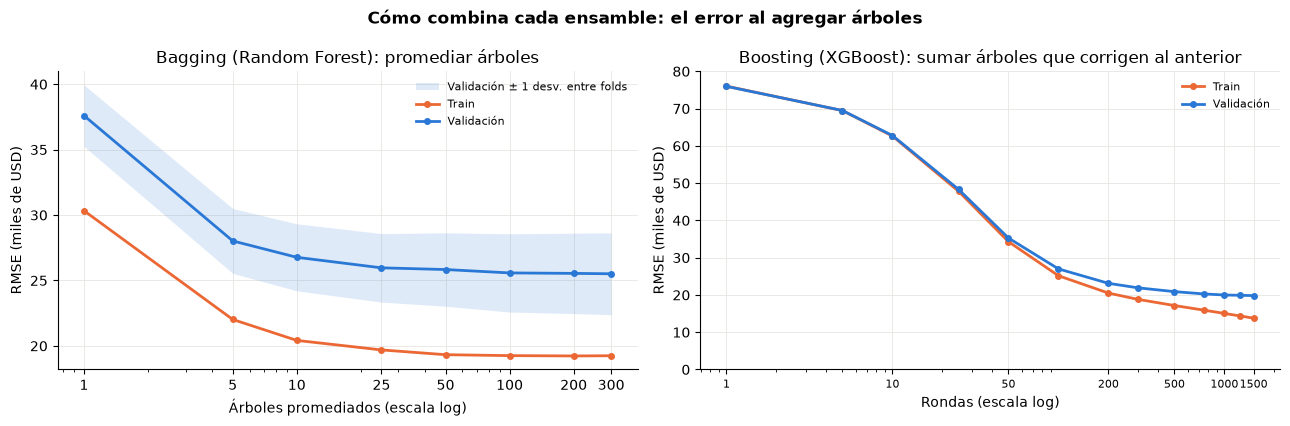

In [89]:
N_ARBOLES = [1, 5, 10, 25, 50, 100, 200, 300]
config_rf = elegidos['Random Forest']['params']
rf_n_arboles = buscar_p4('rf_n_arboles', busqueda_grilla('Random Forest', {**{k: [v] for k, v in config_rf.items()},
                                                                          'n_estimators': N_ARBOLES}))

RONDAS = [1, 5, 10, 25, 50, 100, 200, 300, 500, 750, 1000, 1250, 1500]


def curva_rondas():
    rmse_train, rmse_val = [], []
    for tr, va in cv.split(X_train_base):
        modelo = construir_modelo_p3('XGBoost').fit(X_train_base.iloc[tr], y_train_base.iloc[tr])
        pre, booster = modelo.regressor_.named_steps['pre'], modelo.regressor_.named_steps['modelo']
        X_tr, X_va = pre.transform(X_train_base.iloc[tr]), pre.transform(X_train_base.iloc[va])
        rmse_train.append([root_mean_squared_error(y_train_base.iloc[tr], np.expm1(booster.predict(X_tr, iteration_range=(0, r))))
                           for r in RONDAS])
        rmse_val.append([root_mean_squared_error(y_train_base.iloc[va], np.expm1(booster.predict(X_va, iteration_range=(0, r))))
                         for r in RONDAS])
    return {'rondas': RONDAS, 'rmse_train': np.round(rmse_train, 2).tolist(), 'rmse_val': np.round(rmse_val, 2).tolist()}


xgb_rondas = calcular_o_cargar('xgb_rondas', curva_rondas)

tabla_bag = pd.DataFrame({'Árboles': N_ARBOLES, 'RMSE train': rf_n_arboles['RMSE train'].values,
                          'RMSE val': rf_n_arboles['RMSE val'].values, 'Desv. RMSE val': rf_n_arboles['Desv. RMSE val'].values,
                          'Brecha R² (pts)': rf_n_arboles['Brecha R² (pts)'].values}).set_index('Árboles')
print("=== Random Forest del P3 según el número de árboles promediados ===")
print(tabla_bag.round({'RMSE train': 0, 'RMSE val': 0, 'Desv. RMSE val': 0, 'Brecha R² (pts)': 1}).T.to_string())

val_rondas = np.array(xgb_rondas['rmse_val']).mean(axis=0)
train_rondas = np.array(xgb_rondas['rmse_train']).mean(axis=0)
print("\n=== XGBoost del P3 según el número de rondas (árboles sumados) ===")
print(pd.DataFrame({'RMSE train': train_rondas, 'RMSE val': val_rondas}, index=pd.Index(RONDAS, name='Rondas'))
      .round(0).T.to_string())


fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
val, desv = tabla_bag['RMSE val'] / 1000, tabla_bag['Desv. RMSE val'] / 1000
ax.fill_between(N_ARBOLES, val - desv, val + desv, color=COLOR_VAL, alpha=0.15, linewidth=0, label='Validación ± 1 desv. entre folds')
ax.plot(N_ARBOLES, tabla_bag['RMSE train'] / 1000, color=COLOR_TRAIN, marker='o', markersize=4, linewidth=2, label='Train')
ax.plot(N_ARBOLES, val, color=COLOR_VAL, marker='o', markersize=4, linewidth=2, label='Validación')
ax.set_xscale('log')
ax.set_xticks(N_ARBOLES, [str(n) for n in N_ARBOLES])
ax.set(title='Bagging (Random Forest): promediar árboles', xlabel='Árboles promediados (escala log)', ylabel='RMSE (miles de USD)')
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
ax.plot(RONDAS, train_rondas / 1000, color=COLOR_TRAIN, marker='o', markersize=4, linewidth=2, label='Train')
ax.plot(RONDAS, val_rondas / 1000, color=COLOR_VAL, marker='o', markersize=4, linewidth=2, label='Validación')
ax.set_xscale('log')
ax.set_ylim(0, 80)
ax.set_xticks(RONDAS[::2], [str(r) for r in RONDAS[::2]], fontsize=8)
ax.set(title='Boosting (XGBoost): sumar árboles que corrigen al anterior', xlabel='Rondas (escala log)', ylabel='RMSE (miles de USD)')
ax.legend(frameon=False, fontsize=8)
fig.suptitle('Cómo combina cada ensamble: el error al agregar árboles', fontsize=12, fontweight='bold')
fig.tight_layout()
guardar_figura(fig, 'p4_01_bagging_boosting')
plt.show()

- Bagging: un árbol del bosque solo tiene 37.604 USD de RMSE de validación y 8,6 puntos de brecha. Con 5 árboles promediados baja a 28.023, con 25 a 25.965 y con 300 a 25.512, con brecha de 4,8. Promediar baja el error en 12.092 USD. La curva cae rápido y se aplana: cada árbol del bosque es malo por separado, y lo que los vuelve útiles es promediar errores distintos. El error de train casi no baja después de 25 árboles (de 19.691 a 19.246), así que lo que cae es la varianza.
- Boosting: con 1 ronda el modelo predice casi la media (75.971 USD). El error baja a 26.990 con 100 rondas, a 20.892 con 500 y se aplana desde 1.000 (19.988; 19.822 con 1.500). El de train sigue bajando hasta 13.777: los últimos árboles aprenden detalle de train y casi no mejoran la validación, como en la sección 33.2. Cada árbol de profundidad 2 es pobre; la suma corrige el sesgo.
- Los dos mecanismos mejoran mucho al árbol solo, pero el boosting llega más lejos (19.809 USD frente a 25.512). Una explicación posible es que en estos datos el error de un árbol es sobre todo sesgo, porque le cuesta representar con escalones el efecto suave de la superficie o la calidad, y eso es lo que corrige el boosting.

## 44. Combinaciones de modelos: votación y stacking

Bagging y boosting combinan árboles. La otra forma de ensamble es combinar modelos distintos: si Lasso (lineal) y XGBoost (árboles) se equivocan en casas distintas, promediarlos baja el error.

### 44.1 ¿Se equivocan en casas distintas?

Antes de combinar medimos la correlación entre los residuos fuera de fold de cada modelo (`cross_val_predict` con los 5 folds), en escala log, que es aproximadamente el error relativo. Si pasara de 0,9, combinar aportaría poco.

=== Correlación de los residuos fuera de fold (escala log) ===
               Lasso  Random Forest  XGBoost
Lasso          1.000          0.766    0.874
Random Forest  0.766          1.000    0.803
XGBoost        0.874          0.803    1.000

RMSE fuera de fold (USD): {'Lasso': '20.195', 'Random Forest': '25.704', 'XGBoost': '19.817'}
Promedio en log de Lasso + XGBoost: RMSE fuera de fold 19.255 USD
Promedio en log de Lasso + Random Forest + XGBoost: RMSE fuera de fold 20.463 USD

Casas con error > 10 % en Lasso y < 5 % en XGBoost: 76 | al revés: 59 | de 2314


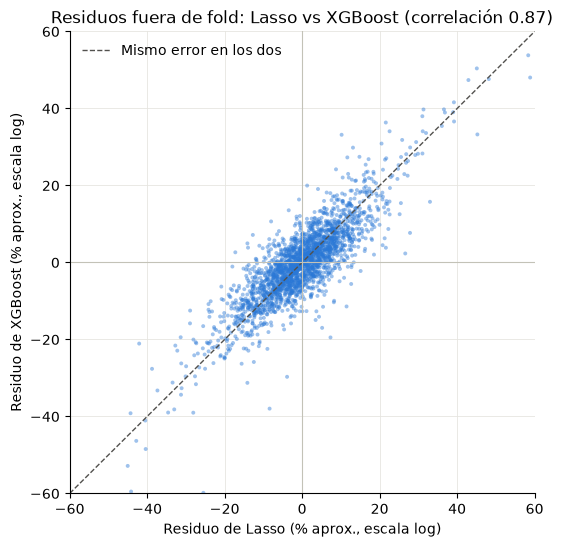

In [90]:
BASES = ['Lasso', 'Random Forest', 'XGBoost']
oof = pd.DataFrame({n: predecir_fuera_de_fold(f'oof_{ARCHIVO[n]}', lambda n=n: construir_modelo_p3(n)) for n in BASES})
assert oof.index.equals(X_train_base.index)
residuos_log = np.log1p(oof).sub(np.log1p(y_train_base), axis=0)

print("=== Correlación de los residuos fuera de fold (escala log) ===")
print(residuos_log.corr().round(3).to_string())
print("\nRMSE fuera de fold (USD):", {n: usd(root_mean_squared_error(y_train_base, oof[n])) for n in BASES})

for par in [('Lasso', 'XGBoost'), ('Lasso', 'Random Forest', 'XGBoost')]:
    promedio = np.expm1(np.log1p(oof[list(par)]).mean(axis=1))
    print(f"Promedio en log de {' + '.join(par)}: RMSE fuera de fold {usd(root_mean_squared_error(y_train_base, promedio))} USD")

err = residuos_log.abs()
print(f"\nCasas con error > 10 % en Lasso y < 5 % en XGBoost: {((err['Lasso'] > 0.10) & (err['XGBoost'] < 0.05)).sum()} | "
      f"al revés: {((err['XGBoost'] > 0.10) & (err['Lasso'] < 0.05)).sum()} | de {len(err)}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(residuos_log['Lasso'] * 100, residuos_log['XGBoost'] * 100, s=8, color=COLOR_VAL, alpha=0.45, edgecolors='none')
lim = 60
ax.plot([-lim, lim], [-lim, lim], color=COLOR_REF, linewidth=1, linestyle='--', label='Mismo error en los dos')
ax.axhline(0, color='#c3c2b7', linewidth=0.8); ax.axvline(0, color='#c3c2b7', linewidth=0.8)
ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel='Residuo de Lasso (% aprox., escala log)', ylabel='Residuo de XGBoost (% aprox., escala log)',
       title=f"Residuos fuera de fold: Lasso vs XGBoost (correlación {residuos_log['Lasso'].corr(residuos_log['XGBoost']):.2f})")
ax.legend(frameon=False, loc='upper left')
guardar_figura(fig, 'p4_02_residuos_lasso_xgb')
plt.show()

- La correlación entre los residuos de Lasso y XGBoost es 0,874: se equivocan parecido, pero no igual. En 76 casas Lasso se equivoca más de 10 % y XGBoost menos de 5 %, y en 59 pasa lo contrario.
- Random Forest se parece más a XGBoost (0,80) que a Lasso (0,77), pero con 25.704 USD de error fuera de fold tiene poco que aportar.
- El promedio simple de las predicciones fuera de fold de Lasso y XGBoost ya tiene 19.255 USD de RMSE, 562 menos que el mejor de los dos (XGBoost, 19.817). Agregar Random Forest lo empeora (20.463): un modelo unos 5.500 USD peor arrastra al promedio aunque se equivoque distinto.

### 44.2 Votación y stacking

Para no romper el target en log, cada base es la parte interna de su pipeline del P3 (`construir_modelo_p3(n).regressor`: su preparación más el modelo, que predice `log1p(SalePrice)`). Los modelos se combinan en escala log y el conjunto va dentro del mismo `TransformedTargetRegressor`. Cada base trae su propia preparación (Lasso: one-hot y escalado; XGBoost: one-hot y target encoding), así que las dos reciben `X_train_base` sin codificar.

- Votación (`VotingRegressor`): promedio con pesos iguales, fijados de antemano. Elegir los pesos mirando la validación sería ajustar a los folds.
- Stacking (`StackingRegressor`): un meta-modelo aprende cuánto pesa cada base a partir de sus predicciones fuera de fold (5 folds internos). Es una regresión lineal con coeficientes positivos, para que se lea como cuánto confía en cada modelo.

Evaluamos dos combinaciones, decididas antes de ver resultados: Lasso + XGBoost y Lasso + Random Forest + XGBoost. De cada tipo pasa al test una sola, con la regla de la sección 28.

In [91]:
VARIANTES = {'Lasso + XGBoost': ['Lasso', 'XGBoost'], 'Lasso + RF + XGBoost': ['Lasso', 'Random Forest', 'XGBoost']}
CORTO = {'Lasso': 'lasso', 'Random Forest': 'rf', 'XGBoost': 'xgb'}


def construir_combinacion(tipo, bases):
    estimadores = [(CORTO[n], construir_modelo_p3(n).regressor) for n in bases]
    if tipo == 'Votación':
        return con_log(VotingRegressor(estimadores))     # promedio simple: pesos iguales, fijados de antemano
    return con_log(StackingRegressor(estimadores, final_estimator=LinearRegression(positive=True),
                                     cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)))


interno = construir_modelo_p3('Lasso').regressor
assert isinstance(interno, Pipeline) and list(interno.named_steps) == ['pre', 'modelo']

combinaciones = {}
for tipo in ['Votación', 'Stacking']:
    for variante, bases in VARIANTES.items():
        archivo = f"cv_{ARCHIVO[tipo]}_{'_'.join(CORTO[b] for b in bases)}"
        combinaciones[(tipo, variante)] = evaluar_cv(archivo, lambda t=tipo, b=bases: construir_combinacion(t, b))

tabla_comb = pd.DataFrame(combinaciones).T
tabla_comb.index.names = ['Tipo', 'Modelos combinados']
for nombre in ['Lasso', 'XGBoost', 'Random Forest']:
    tabla_comb[f'Gana a {nombre} (folds)'] = [folds_en_que_gana(f, elegidos[nombre]) for _, f in tabla_comb.iterrows()]
print("=== Combinaciones de modelos: 5 folds sobre train, pipelines completos ===")
print(tabla_comb.drop(columns='RMSE val por fold').astype(float).round(FORMATO).to_string())

VARIANTE_ELEGIDA = {}
for tipo in ['Votación', 'Stacking']:
    sub = tabla_comb.xs(tipo, level='Tipo')
    VARIANTE_ELEGIDA[tipo] = elegir(sub)
    print(f"{tipo} para el test: {VARIANTE_ELEGIDA[tipo]} (RMSE val {usd(sub.loc[VARIANTE_ELEGIDA[tipo], 'RMSE val'])} USD, "
          f"brecha {sub.loc[VARIANTE_ELEGIDA[tipo], 'Brecha R² (pts)']:.1f} puntos)")
    elegidos[tipo] = sub.loc[VARIANTE_ELEGIDA[tipo]]

=== Combinaciones de modelos: 5 folds sobre train, pipelines completos ===
                               RMSE train  RMSE val  Desv. RMSE val  MAE val  MAPE % val  R² train  R² val  Brecha R² (pts)  Gana a Lasso (folds)  Gana a XGBoost (folds)  Gana a Random Forest (folds)
Tipo     Modelos combinados                                                                                                                                                                            
Votación Lasso + XGBoost          15107.0   19239.0           787.0  12917.0        7.60     0.961   0.936              2.5                   5.0                     5.0                           5.0
         Lasso + RF + XGBoost     15639.0   20411.0          1450.0  13208.0        7.71     0.958   0.929              3.0                   3.0                     2.0                           5.0
Stacking Lasso + XGBoost          15024.0   19203.0           768.0  12911.0        7.61     0.961   0.936              2.5  

In [92]:
def calcular_pesos():
    pesos = {}
    for variante, bases in VARIANTES.items():
        st = construir_combinacion('Stacking', bases).fit(X_train_base, y_train_base).regressor_
        pesos[variante] = {'bases': bases, 'coef': st.final_estimator_.coef_.round(4).tolist(),
                           'intercepto': round(float(st.final_estimator_.intercept_), 4)}
    return {'pesos': pesos}


pesos_stacking = calcular_o_cargar('stacking_pesos', calcular_pesos)['pesos']
for variante, p in pesos_stacking.items():
    total = sum(p['coef'])
    print(f"{variante}: " + ' | '.join(f"{b} {c:.3f} ({c / total * 100:.0f} %)" for b, c in zip(p['bases'], p['coef']))
          + f" | suma {total:.3f} | intercepto {p['intercepto']:+.3f}")

Lasso + XGBoost: Lasso 0.449 (45 %) | XGBoost 0.553 (55 %) | suma 1.002 | intercepto -0.022
Lasso + RF + XGBoost: Lasso 0.441 (44 %) | Random Forest 0.029 (3 %) | XGBoost 0.535 (53 %) | suma 1.005 | intercepto -0.059


- Las dos combinaciones de Lasso y XGBoost mejoran a sus dos bases en los 5 folds: la votación tiene 19.239 USD de RMSE de validación y el stacking 19.203, contra 19.809 de XGBoost y 20.171 de Lasso. Su brecha, 2,5 puntos, queda entre la de Lasso (1,1) y la de XGBoost (3,9).
- Agregar Random Forest no sirve. En la votación empeora el resultado (20.411 USD, peor que XGBoost solo), por lo mismo que en la sección 44.1. En el stacking el meta-modelo le da un peso casi nulo (3 %), con Lasso en 0,441 y XGBoost en 0,535, y el resultado es casi el mismo que sin Random Forest (19.225 frente a 19.203 USD). El stacking aprendió solo lo que la votación tenía que suponer.
- Pasan al test la votación y el stacking de Lasso + XGBoost. Los pesos del stacking (45 % y 55 %, que suman 1,002) quedan muy cerca del 50/50 de la votación, así que deberían rendir casi igual.

## 45. ¿Los ensambles mejoran? (IE10)

Todos los modelos en una tabla, medidos con el mismo protocolo (5 folds sobre train y pipelines completos), y las comparaciones que responden la pregunta con el criterio de cambio real de la sección 41:

- Votación y stacking contra su mejor base (XGBoost): lo que aporta combinar modelos distintos.
- Todos los ensambles contra Lasso: si alguno justifica perder interpretabilidad.

El aporte de promediar y de sumar árboles frente a un árbol solo está en la sección 43.

En la salida, la columna «Combina» dice «1.500 árboles en secuencia» para XGBoost porque ese texto está escrito a mano en el código; la configuración elegida en esta ejecución tiene 2.000 árboles (sección 32).

=== Todos los modelos: 5 folds sobre train (los de la búsqueda del P3 y los ensambles de las sec. 43-44) ===
                                            Combina  RMSE train  RMSE val  Desv. RMSE val  MAE val  MAPE % val  R² train  R² val  Brecha R² (pts)  Gana a Lasso (folds)  Gana a su mejor base (folds)
Modelo                                                                                                                                                                                               
Ridge                                      1 modelo     18649.0   20123.0           933.0  13730.0        8.07     0.941   0.930              1.1                     4                           NaN
Lasso                                      1 modelo     18711.0   20171.0           976.0  13759.0        8.09     0.940   0.930              1.1                     0                           NaN
Lasso (alpha P2)                           1 modelo     18812.0   20174.0           991.0  13752.0 

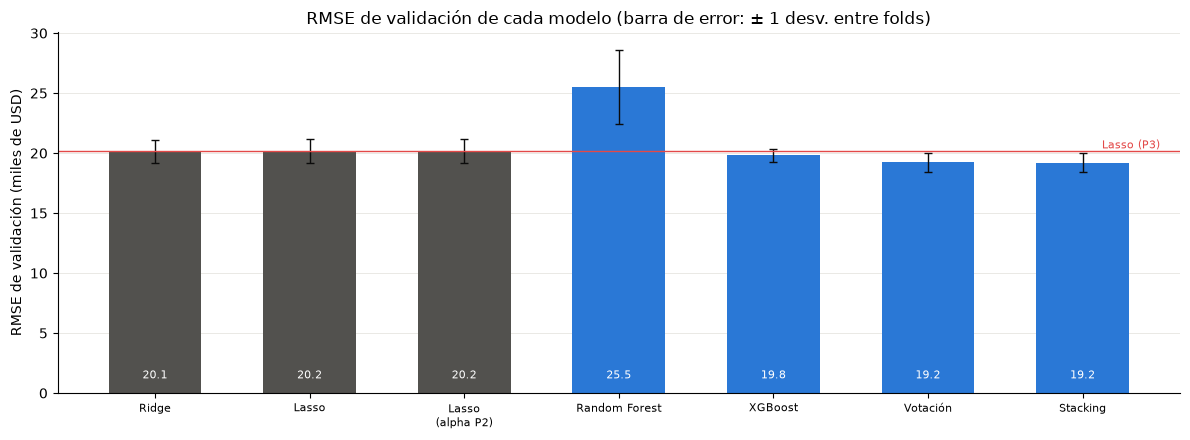

In [93]:
grilla_lasso = busquedas['Lasso']
fila = grilla_lasso[[np.isclose(p['alpha'], ALPHA_P2['Lasso']) for p in grilla_lasso['params']]]
assert len(fila) == 1
elegidos['Lasso (alpha P2)'] = fila.iloc[0]

COMBINADOS = {'Ridge': '1 modelo', 'Lasso': '1 modelo', 'Lasso (alpha P2)': '1 modelo',
              'Random Forest': '300 árboles',
              'XGBoost': '1.500 árboles en secuencia', 'Votación': f"promedio de {VARIANTE_ELEGIDA['Votación']}",
              'Stacking': f"meta-modelo sobre {VARIANTE_ELEGIDA['Stacking']}"}
MEJOR_BASE = {'Votación': 'XGBoost', 'Stacking': 'XGBoost'}   # el mejor modelo que el ensamble combina (para Votación y Stacking, XGBoost)

ORDEN_P4 = ['Ridge', 'Lasso', 'Lasso (alpha P2)', 'Random Forest', 'XGBoost',
            'Votación', 'Stacking']
filas = []
for nombre in ORDEN_P4:
    f = elegidos[nombre]
    fila = {'Modelo': nombre, 'Combina': COMBINADOS[nombre], **{k: f[k] for k in FORMATO}}
    fila['Gana a Lasso (folds)'] = folds_en_que_gana(f, elegidos['Lasso'])
    base = MEJOR_BASE.get(nombre)
    fila['Gana a su mejor base (folds)'] = folds_en_que_gana(f, elegidos[base]) if base else np.nan
    filas.append(fila)
comparacion_p4 = pd.DataFrame(filas).set_index('Modelo')
print("=== Todos los modelos: 5 folds sobre train (los de la búsqueda del P3 y los ensambles de las sec. 43-44) ===")
print(comparacion_p4.round(FORMATO).to_string())

PREGUNTAS = [('Votación', 'XGBoost', 'combinar (votación) vs su mejor base'),
             ('Stacking', 'XGBoost', 'combinar (stacking) vs su mejor base'),
             ('Random Forest', 'Lasso', 'ensamble vs Lasso'), ('XGBoost', 'Lasso', 'ensamble vs Lasso'),
             ('Votación', 'Lasso', 'ensamble vs Lasso'), ('Stacking', 'Lasso', 'ensamble vs Lasso')]
filas = []
for a, b, que in PREGUNTAS:
    fa, fb = elegidos[a], elegidos[b]
    filas.append({'Aporte medido': que, 'Modelo': a, 'Contra': b,
                  'Dif. RMSE val (USD)': round(fa['RMSE val'] - fb['RMSE val']),
                  'Desv. entre folds de la referencia': round(fb['Desv. RMSE val']),
                  'Folds en que gana (de 5)': folds_en_que_gana(fa, fb),
                  'Dif. R² val (pts)': round((fa['R² val'] - fb['R² val']) * 100, 2),
                  '¿Cambio real?': 'Sí' if es_cambio_real(fa, fb) else 'No'})
aportes = pd.DataFrame(filas)
print("\n=== ¿Mejora cada ensamble? Criterio de cambio real de la sección 41 ===")
print(aportes.to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(len(ORDEN_P4))
valores = comparacion_p4['RMSE val'] / 1000
colores = [COLOR_REF if n in ('Ridge', 'Lasso', 'Lasso (alpha P2)') else COLOR_VAL
           for n in ORDEN_P4]
barras = ax.bar(x, valores, 0.6, color=colores)
ax.errorbar(x, valores, yerr=comparacion_p4['Desv. RMSE val'] / 1000, fmt='none', ecolor='#0b0b0b', elinewidth=1, capsize=3)
ax.axhline(elegidos['Lasso']['RMSE val'] / 1000, color='#e34948', linewidth=1)
ax.text(len(ORDEN_P4) - 0.5, elegidos['Lasso']['RMSE val'] / 1000, 'Lasso (P3)', color='#e34948', fontsize=8, va='bottom', ha='right')
for barra, valor in zip(barras, valores):
    ax.text(barra.get_x() + barra.get_width() / 2, 1, f'{valor:.1f}', ha='center', va='bottom', fontsize=8, color='white')
ax.set_xticks(x, [n.replace(' de ', '\nde ').replace(' (', '\n(') for n in ORDEN_P4], fontsize=8)
ax.set(ylabel='RMSE de validación (miles de USD)', title='RMSE de validación de cada modelo (barra de error: ± 1 desv. entre folds)')
ax.grid(axis='x', visible=False)
fig.tight_layout()
guardar_figura(fig, 'p4_03_comparacion_ensambles')
plt.show()

Frente a un árbol solo, bagging y boosting mejoran mucho (sección 43): promediar 300 árboles baja el RMSE de 37.604 a 25.512 USD, y sumar árboles en secuencia llega a 19.809. Es lo que vuelve competitivos a los modelos de árboles.

Combinar modelos distintos mejora de forma consistente, pero poco. La votación y el stacking le ganan a XGBoost en los 5 folds, por 570 y 605 USD. La desviación entre folds de XGBoost es 570 USD: el stacking la supera por poco y cuenta como cambio real, y la votación queda justo en el límite y no cuenta. La sección 46 lo revisa con folds nuevos.

Frente a Lasso, ningún ensamble es un cambio real. Random Forest es peor en los 5 folds (+5.342 USD). XGBoost gana por 362 USD en 3 de 5 folds, un empate. El stacking y la votación ganan en los 5 folds por 967 y 932 USD, pero eso es menos que la desviación entre folds de Lasso (976 USD) y equivale a 0,66 y 0,64 puntos de R² de validación, bajo el punto que exige la regla de la sección 20.

Los ensambles mejoran a los árboles, y combinar Lasso con XGBoost da el menor error medido, pero no superan con claridad a un buen modelo lineal. En estos datos el precio en log es casi lineal en la superficie, la calidad y la antigüedad, y Lasso ya captura la mayor parte de la señal. Mostrar con el mismo protocolo que un ensamble no supera a Lasso también es un resultado.

## 46. Generalización I: ¿cuánto es optimista la validación de la búsqueda?

Es la advertencia 1 de la sección 40: cada configuración se eligió como la mejor entre cientos evaluadas con los mismos 5 folds, y parte de su ventaja puede ser suerte con esas particiones. Lo medimos de dos formas.

### 46.1 Folds nuevos

Reevaluamos los siete candidatos con `RepeatedKFold(n_splits=5, n_repeats=3, random_state=2024)`: 15 folds que la búsqueda nunca vio. Si la validación de la búsqueda fuera optimista, el error subiría con los folds nuevos, y más en los modelos con más configuraciones probadas.

=== RMSE de validación con los folds de la búsqueda (5) y con folds nuevos (15) ===
                  RMSE val, folds de la búsqueda  RMSE val, folds nuevos  Desv. entre folds nuevos  R² val, folds nuevos  Brecha R², folds nuevos (pts)  MAPE % val, folds nuevos  Diferencia (USD)  Diferencia (%)  Configuraciones probadas
Ridge                                    20123.0                 20160.0                     717.0                0.9304                            1.0                      8.04              37.0             0.2                        30
Lasso                                    20171.0                 20224.0                     740.0                0.9300                            1.0                      8.05              53.0             0.3                        30
Lasso (alpha P2)                         20174.0                 20243.0                     744.0                0.9299                            1.0                      8.05              69.0       

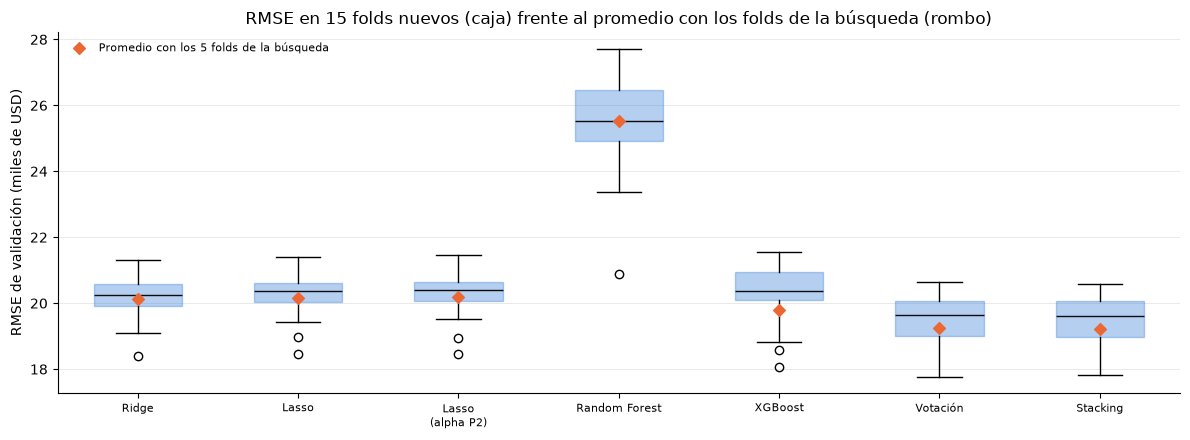

In [94]:
def construir_candidato(nombre):
    if nombre == 'Lasso (alpha P2)':
        return pipeline_p3('Lasso').set_params(**{PREFIJO + 'alpha': ALPHA_P2['Lasso']})
    if nombre in ('Votación', 'Stacking'):
        return construir_combinacion(nombre, VARIANTES[VARIANTE_ELEGIDA[nombre]])
    return construir_modelo_p3(nombre)


nuevos = {n: evaluar_cv(f'folds_nuevos/{ARCHIVO[n]}', lambda n=n: construir_candidato(n), CV_NUEVOS) for n in CANDIDATOS}

optimismo = pd.DataFrame({n: {
    'RMSE val, folds de la búsqueda': elegidos[n]['RMSE val'],
    'RMSE val, folds nuevos': nuevos[n]['RMSE val'],
    'Desv. entre folds nuevos': nuevos[n]['Desv. RMSE val'],
    'R² val, folds nuevos': nuevos[n]['R² val'],
    'Brecha R², folds nuevos (pts)': nuevos[n]['Brecha R² (pts)'],
    'MAPE % val, folds nuevos': nuevos[n]['MAPE % val'],
} for n in CANDIDATOS}).T
optimismo['Diferencia (USD)'] = optimismo['RMSE val, folds nuevos'] - optimismo['RMSE val, folds de la búsqueda']
optimismo['Diferencia (%)'] = optimismo['Diferencia (USD)'] / optimismo['RMSE val, folds de la búsqueda'] * 100
configuraciones = {'Ridge': 30, 'Lasso': 30, 'Lasso (alpha P2)': 30,
                   'Random Forest': len(busquedas['Random Forest']), 'XGBoost': len(busquedas['XGBoost']),
                   'Votación': len(VARIANTES), 'Stacking': len(VARIANTES)}
optimismo['Configuraciones probadas'] = pd.Series(configuraciones)
print("=== RMSE de validación con los folds de la búsqueda (5) y con folds nuevos (15) ===")
print(optimismo.round({'RMSE val, folds de la búsqueda': 0, 'RMSE val, folds nuevos': 0, 'Desv. entre folds nuevos': 0,
                       'R² val, folds nuevos': 4, 'Brecha R², folds nuevos (pts)': 1, 'MAPE % val, folds nuevos': 2,
                       'Diferencia (USD)': 0, 'Diferencia (%)': 1}).to_string())

print("\nCon folds nuevos (gana en cuántos de 15):")
for a, b in [('Stacking', 'Lasso'), ('Votación', 'Lasso'), ('XGBoost', 'Lasso'), ('Stacking', 'XGBoost'),
             ('Lasso (alpha P2)', 'Lasso')]:
    print(f"  {a:17s} vs {b:17s}: {nuevos[a]['RMSE val'] - nuevos[b]['RMSE val']:+7,.0f} USD | gana en "
          f"{folds_en_que_gana(nuevos[a], nuevos[b]):2d} de 15 | dif. R² {(nuevos[a]['R² val'] - nuevos[b]['R² val']) * 100:+.2f} pts")

fig, ax = plt.subplots(figsize=(12, 4.5))
datos_box = [nuevos[n]['RMSE val por fold'] / 1000 for n in CANDIDATOS]
caja = ax.boxplot(datos_box, patch_artist=True, widths=0.55, medianprops=dict(color='#0b0b0b'))
for parche in caja['boxes']:
    parche.set(facecolor=COLOR_VAL, alpha=0.35, edgecolor=COLOR_VAL)
ax.scatter(np.arange(1, len(CANDIDATOS) + 1), [elegidos[n]['RMSE val'] / 1000 for n in CANDIDATOS], marker='D', s=36,
           color=COLOR_TRAIN, zorder=3, label='Promedio con los 5 folds de la búsqueda')
ax.set_xticks(np.arange(1, len(CANDIDATOS) + 1), [n.replace(' de ', '\nde ').replace(' (', '\n(') for n in CANDIDATOS], fontsize=8)
ax.set(ylabel='RMSE de validación (miles de USD)', title='RMSE en 15 folds nuevos (caja) frente al promedio con los folds de la búsqueda (rombo)')
ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.grid(axis='x', visible=False)
fig.tight_layout()
guardar_figura(fig, 'p4_04_folds_nuevos')
plt.show()

- En los lineales y en Random Forest el optimismo es despreciable: con folds nuevos el RMSE cambia entre −10 y +69 USD (menos de 0,4 %), muy por debajo de la desviación entre folds. Random Forest, con 359 configuraciones probadas, no sube nada (−10 USD): su búsqueda encontró una zona plana (sección 35.2), y en una zona plana elegir la mejor no saca provecho de la suerte de los folds.
- XGBoost sí muestra algo de optimismo: sube 440 USD (2,2 %), de 19.809 a 20.248, y su brecha pasa de 3,9 a 4,3. Es el modelo con más configuraciones probadas (467), como anticipaba la advertencia 1. La diferencia es menor que su desviación entre folds nuevos (1.006 USD). La votación y el stacking, que lo usan, suben 270 y 286 USD (1,4 % y 1,5 %).
- Las comparaciones que deciden se sostienen. Con 15 folds nuevos el stacking le gana a Lasso en los 15 (−735 USD) y la votación también (−715 USD); el stacking le gana a XGBoost en 13 de 15. XGBoost y Lasso quedan empatados (+24 USD, gana en 7 de 15). El Lasso con el `alpha` del P2 queda a 19 USD del Lasso del P3.
- La mejora del stacking sobre Lasso es chica (de 735 a 967 USD, 0,5 a 0,7 puntos de R²), pero aparece en los 20 folds probados, así que no es suerte de los folds.

### 46.2 Validación cruzada anidada

Los folds nuevos miden si la configuración elegida rinde igual con otras casas. La validación cruzada anidada mide el error del procedimiento de búsqueda completo: en cada uno de los 5 folds externos se repite la búsqueda solo con las casas de entrenamiento de ese fold (5 folds internos), se elige con la regla de la sección 28 y se mide en el fold externo, que la búsqueda no vio. Para XGBoost la búsqueda interna es una aleatoria de 20 configuraciones del espacio de la sección 30.3 (la del P3 tuvo 467, con grillas); para Lasso, la grilla de 30 `alpha`.

In [95]:
N_ANIDADA = 20
cv_interno = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def anidada(nombre):
    def calcular():
        if nombre == 'XGBoost':
            espacio, n_iter = {PREFIJO + k: v for k, v in ESPACIO['XGBoost'].items()}, N_ANIDADA
        else:
            espacio, n_iter = {PREFIJO + 'alpha': GRILLA_ALPHA['Lasso']}, None
        folds = []
        for fold, (tr, va) in enumerate(cv.split(X_train_base)):
            X_tr, y_tr = X_train_base.iloc[tr], y_train_base.iloc[tr]
            if n_iter:
                busqueda = RandomizedSearchCV(pipeline_p3(nombre), espacio, n_iter=n_iter, cv=cv_interno, scoring=metricas,
                                              refit=False, return_train_score=True, n_jobs=-1, random_state=RANDOM_STATE + fold)
            else:
                busqueda = GridSearchCV(pipeline_p3(nombre), espacio, cv=cv_interno, scoring=metricas, refit=False,
                                        return_train_score=True, n_jobs=-1)
            busqueda.fit(X_tr, y_tr)
            r = busqueda.cv_results_
            tabla = pd.DataFrame({'params': r['params'], 'RMSE val': -r['mean_test_rmse'],
                                  'Brecha R² (pts)': (r['mean_train_r2'] - r['mean_test_r2']) * 100})
            i = elegir(tabla)
            if i is None:                                    # ninguna cumple la brecha: se reporta y se usa la de menor RMSE
                i = tabla['RMSE val'].idxmin()
            modelo = pipeline_p3(nombre).set_params(**tabla.loc[i, 'params']).fit(X_tr, y_tr)
            pred = modelo.predict(X_train_base.iloc[va])
            folds.append({'params': {k.replace(PREFIJO, ''): a_nativo(v) for k, v in tabla.loc[i, 'params'].items()},
                          'rmse_interno': round(float(tabla.loc[i, 'RMSE val']), 2),
                          'rmse_externo': round(root_mean_squared_error(y_train_base.iloc[va], pred), 2),
                          'cumplian_brecha': int((tabla['Brecha R² (pts)'] <= MAX_BRECHA).sum())})
        return {'folds': folds}
    return calcular_o_cargar(f'anidada_{ARCHIVO[nombre]}', calcular)


filas = []
for nombre in ['Lasso', 'XGBoost']:
    resultado = anidada(nombre)
    externo = np.array([f['rmse_externo'] for f in resultado['folds']])
    interno = np.array([f['rmse_interno'] for f in resultado['folds']])
    for fold, f in enumerate(resultado['folds']):
        print(f"{nombre} fold {fold + 1}: RMSE interno {usd(f['rmse_interno'])} | externo {usd(f['rmse_externo'])} | "
              f"cumplían la brecha {f['cumplian_brecha']} | {f['params']}")
    filas.append({'Modelo': nombre, 'RMSE anidada (fold externo)': externo.mean(), 'Desv. entre folds': externo.std(),
                  'RMSE de la búsqueda interna': interno.mean(), 'RMSE val, configuración del P3': elegidos[nombre]['RMSE val'],
                  'Anidada − P3 (USD)': externo.mean() - elegidos[nombre]['RMSE val']})
    print()
anidada_tabla = pd.DataFrame(filas).set_index('Modelo')
print("=== Validación cruzada anidada frente a la validación de la configuración elegida en el P3 ===")
print(anidada_tabla.round(0).to_string())

Lasso fold 1: RMSE interno 20.433 | externo 19.871 | cumplían la brecha 30 | {'alpha': 0.00017433288221999874}
Lasso fold 2: RMSE interno 20.304 | externo 21.555 | cumplían la brecha 30 | {'alpha': 0.0001268961003167922}
Lasso fold 3: RMSE interno 20.181 | externo 20.993 | cumplían la brecha 30 | {'alpha': 0.0001268961003167922}
Lasso fold 4: RMSE interno 20.649 | externo 19.556 | cumplían la brecha 30 | {'alpha': 0.0001268961003167922}
Lasso fold 5: RMSE interno 20.782 | externo 18.813 | cumplían la brecha 30 | {'alpha': 0.00017433288221999874}



XGBoost fold 1: RMSE interno 20.955 | externo 20.364 | cumplían la brecha 13 | {'subsample': 0.5, 'reg_lambda': 10.0, 'reg_alpha': 0.01, 'n_estimators': 1000, 'min_child_weight': 8, 'max_depth': 2, 'learning_rate': 0.1, 'gamma': 0.01, 'colsample_bytree': 0.5}
XGBoost fold 2: RMSE interno 20.838 | externo 21.782 | cumplían la brecha 15 | {'subsample': 1.0, 'reg_lambda': 100.0, 'reg_alpha': 0.001, 'n_estimators': 2000, 'min_child_weight': 12, 'max_depth': 2, 'learning_rate': 0.1, 'gamma': 0.001, 'colsample_bytree': 0.1}
XGBoost fold 3: RMSE interno 21.161 | externo 20.047 | cumplían la brecha 15 | {'subsample': 0.6, 'reg_lambda': 0.0, 'reg_alpha': 0.001, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.05, 'gamma': 0.003, 'colsample_bytree': 0.4}
XGBoost fold 4: RMSE interno 22.406 | externo 23.187 | cumplían la brecha 13 | {'subsample': 0.4, 'reg_lambda': 0.0, 'reg_alpha': 0.001, 'n_estimators': 700, 'min_child_weight': 20, 'max_depth': 2, 'learning_rate': 

- Lasso: 20.158 USD con la búsqueda anidada, frente a 20.171 de la configuración elegida. Elegir `alpha` no introduce optimismo, y en los 5 folds externos la búsqueda elige 0,000127 o 0,000174, los mismos valores del P3 y del P2.
- XGBoost: 21.001 USD, 1.192 más que la configuración del P3. Una parte es el optimismo de la sección 46.1 (unos 440 USD) y el resto es el costo de una búsqueda chica: con 20 configuraciones cada fold elige algo distinto (de 300 a 2.000 árboles, tasa de 0,03 a 0,1, profundidad 2 o 3), y en el fold 4 el error llega a 23.187 USD. Es una cota pesimista del procedimiento del P3.
- Para el negocio: el resultado de Lasso no depende de cómo se buscó; el de XGBoost sí, porque necesita una búsqueda cuidadosa para quedar cerca de Lasso. Es otra razón de robustez a favor del lineal.

## 47. Generalización II: curvas de aprendizaje y brecha

Entrenamos cada modelo con el 10 % al 100 % de las casas de entrenamiento de cada fold y lo medimos en el fold de validación. Se dibujan Lasso, XGBoost y la combinación con menor error (el stacking). Si las curvas de train y validación convergen, el modelo no sobreajusta; si la de validación sigue bajando al final, más datos ayudarían.

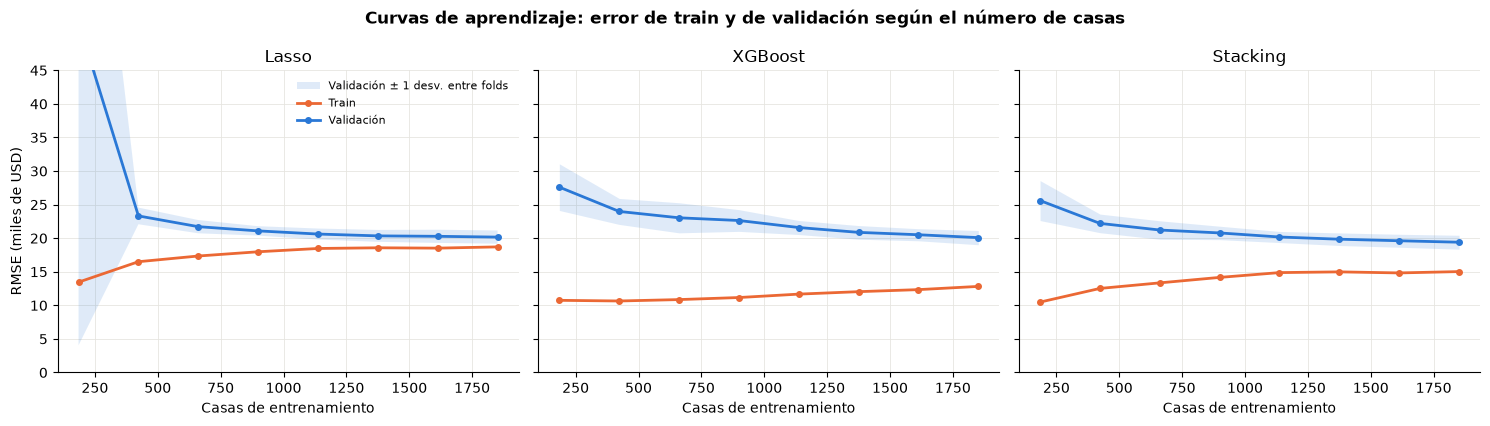

          RMSE val con 185 casas  RMSE val con 1613 casas  RMSE val con 1851 casas  Baja en el último tramo (USD)  Distancia train-val al final (USD)
Modelo                                                                                                                                               
Lasso                    52135.0                  20282.0                  20165.0                          117.0                              1458.0
XGBoost                  27606.0                  20515.0                  20087.0                          428.0                              7266.0
Stacking                 25605.0                  19621.0                  19402.0                          219.0                              4374.0

=== Margen frente al máximo de brecha (5 puntos), validación con los folds de la búsqueda y con folds nuevos ===
  Ridge              brecha  1.1 (folds nuevos  1.0) | margen +3.9 puntos
  Lasso              brecha  1.1 (folds nuevos  1.0) | margen 

In [96]:
TAMANOS = np.linspace(0.1, 1.0, 8)
COMBINACION = min(['Votación', 'Stacking'], key=lambda n: elegidos[n]['RMSE val'])   # la combinación con menor RMSE de validación
MODELOS_CURVA = ['Lasso', 'XGBoost', COMBINACION]


def curva_aprendizaje(nombre):
    def calcular():
        n, tr, va = learning_curve(construir_candidato(nombre), X_train_base, y_train_base, cv=cv, train_sizes=TAMANOS,
                                   scoring='neg_root_mean_squared_error', n_jobs=-1, shuffle=True, random_state=RANDOM_STATE)
        return {'casas': n.tolist(), 'rmse_train': (-tr).round(2).tolist(), 'rmse_val': (-va).round(2).tolist()}
    return calcular_o_cargar(f'curva_aprendizaje_{ARCHIVO[nombre]}', calcular)


curvas_ap = {n: curva_aprendizaje(n) for n in MODELOS_CURVA}

fig, axes = plt.subplots(1, len(MODELOS_CURVA), figsize=(15, 4.3), sharey=True)
filas = []
for ax, nombre in zip(axes, MODELOS_CURVA):
    c = curvas_ap[nombre]
    casas = np.array(c['casas'])
    tr, va = np.array(c['rmse_train']) / 1000, np.array(c['rmse_val']) / 1000
    ax.fill_between(casas, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color=COLOR_VAL, alpha=0.15, linewidth=0,
                    label='Validación ± 1 desv. entre folds')
    ax.plot(casas, tr.mean(1), color=COLOR_TRAIN, marker='o', markersize=4, linewidth=2, label='Train')
    ax.plot(casas, va.mean(1), color=COLOR_VAL, marker='o', markersize=4, linewidth=2, label='Validación')
    ax.set(title=nombre, xlabel='Casas de entrenamiento', ylim=(0, 45))
    if ax is axes[0]:
        ax.set_ylabel('RMSE (miles de USD)')
    filas.append({'Modelo': nombre,
                  f'RMSE val con {casas[0]} casas': va.mean(1)[0] * 1000,
                  f'RMSE val con {casas[-2]} casas': va.mean(1)[-2] * 1000,
                  f'RMSE val con {casas[-1]} casas': va.mean(1)[-1] * 1000,
                  'Baja en el último tramo (USD)': (va.mean(1)[-2] - va.mean(1)[-1]) * 1000,
                  'Distancia train-val al final (USD)': (va.mean(1)[-1] - tr.mean(1)[-1]) * 1000})
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle('Curvas de aprendizaje: error de train y de validación según el número de casas', fontsize=12, fontweight='bold')
fig.tight_layout()
guardar_figura(fig, 'p4_05_curvas_aprendizaje')
plt.show()
print(pd.DataFrame(filas).set_index('Modelo').round(0).to_string())

print("\n=== Margen frente al máximo de brecha (5 puntos), validación con los folds de la búsqueda y con folds nuevos ===")
for nombre in CANDIDATOS:
    print(f"  {nombre:18s} brecha {elegidos[nombre]['Brecha R² (pts)']:4.1f} (folds nuevos {nuevos[nombre]['Brecha R² (pts)']:4.1f}) | "
          f"margen {MAX_BRECHA - max(elegidos[nombre]['Brecha R² (pts)'], nuevos[nombre]['Brecha R² (pts)']):+.1f} puntos")

- Lasso converge. Con 185 casas su error de validación es 52.135 USD (un lineal con 138 columnas necesita más casas), y en el último tramo (de 1.613 a 1.851 casas) baja solo 117 USD; al final train y validación quedan a 1.458 USD. Más casas del mismo período casi no lo mejorarían.
- XGBoost aprende más rápido con pocos datos (27.606 USD con 185 casas), pero al final queda una distancia de 7.266 USD entre train y validación: memoriza más, y su validación todavía baja 428 USD en el último tramo. Es el que más ganaría con más datos.
- El stacking queda entre los dos: 4.374 USD de distancia y 219 USD de mejora en el último tramo.
- Margen frente al máximo de brecha (5 puntos): Lasso tiene 3,9 (4,0 con el `alpha` del P2), el stacking 2,4 y la votación 2,3. Random Forest y XGBoost tienen poco: 0,2 y 0,7 (XGBoost, con la brecha de los folds nuevos, 4,3). El test dirá si esa holgura se sostiene.

## 48. Test final (se abre una sola vez)

Cada candidato de la lista cerrada se entrena con las 2.314 casas de train y se mide en las 582 de test, en los dos escenarios de la sección 23: el test real, que decide, y el test con venta normal impuesta, que se informa. Los cálculos son los de la sección 23 (`calcular_kpis`, dentro de `evaluar_test`). La celda deja una bandera (`TEST_ABIERTO`) que impide ejecutarla otra vez sin reiniciar el notebook.

In [97]:
assert not globals().get('TEST_ABIERTO', False), "El test ya se abrió en esta sesión: reiniciar y ejecutar el notebook completo"
TEST_ABIERTO = True

assert y_test_base.index.equals(seg_test.index) and X_test_normal.index.equals(X_test_base.index)
ESCENARIOS_TEST = {'Test real': X_test_base, 'Venta normal impuesta': X_test_normal}


def cumple_kpi(valor, kpi):
    sentido, umbral = KPI.loc[kpi]
    return valor >= umbral if sentido == '≥' else valor <= umbral


def evaluar_test(modelo_entrenado, nombre):
    r2_tr = r2_score(y_train_base, modelo_entrenado.predict(X_train_base))
    preds, kpis_modelo = {}, {}
    for escenario, X in ESCENARIOS_TEST.items():
        preds[escenario] = pd.Series(modelo_entrenado.predict(X), index=y_test_base.index)
        kpis_modelo[escenario] = calcular_kpis(y_test_base, preds[escenario], r2_tr)
    return r2_tr, preds, kpis_modelo


entrenados_p4, pred_test, kpis_p4, segundos_entrenamiento = {}, {}, {}, {}
for nombre in CANDIDATOS:
    modelo = construir_candidato(nombre)
    if nombre == 'Random Forest':
        modelo.set_params(**{PREFIJO + 'n_jobs': -1})   # Random Forest da el mismo resultado con cualquier número de hilos
    inicio = time.time()
    entrenados_p4[nombre] = modelo.fit(X_train_base, y_train_base)
    segundos_entrenamiento[nombre] = time.time() - inicio
    _, preds, kpis_modelo = evaluar_test(entrenados_p4[nombre], nombre)
    for escenario in ESCENARIOS_TEST:
        pred_test[(escenario, nombre)] = preds[escenario]
        kpis_p4[(escenario, nombre)] = kpis_modelo[escenario]

kpis_p4 = pd.DataFrame(kpis_p4).T
kpis_p4.index.names = ['Escenario', 'Modelo']
cumplimiento_p4 = pd.DataFrame({k: kpis_p4[k].apply(cumple_kpi, kpi=k) for k in KPI.index})
cumplimiento_p4['Cumple los seis'] = cumplimiento_p4.all(axis=1)

for escenario in ESCENARIOS_TEST:
    print(f"=== {escenario} ({len(y_test_base)} casas) ===")
    tabla = kpis_p4.loc[escenario].round(formato)
    tabla['KPI cumplidos'] = cumplimiento_p4.loc[escenario].drop(columns='Cumple los seis').sum(axis=1).astype(str) + ' de 6'
    print(tabla.to_string())
    print()

print("=== Cumplimiento de cada KPI (✔ cumple, ✘ no cumple) ===")
for escenario in ESCENARIOS_TEST:
    print(f"-- {escenario}")
    print(cumplimiento_p4.loc[escenario].replace({True: '✔', False: '✘'}).to_string())
    print()

X_test_abierto = X_test_base.copy()
resultados_test = {'descripcion': 'Test abierto una sola vez (sección 48). Modelos entrenados con todo train.',
                   'kpi': {k: [s, float(u)] for k, (s, u) in KPI.iterrows()},
                   'resultados': {escenario: {nombre: {k: round(float(v), 4) for k, v in kpis_p4.loc[(escenario, nombre)].items()}
                                              | {'cumple_los_seis': bool(cumplimiento_p4.loc[(escenario, nombre), 'Cumple los seis'])}
                                              for nombre in CANDIDATOS} for escenario in ESCENARIOS_TEST}}
(RUTA_PARTE4 / 'resultados_test.json').write_text(json.dumps(resultados_test, indent=1, ensure_ascii=False), encoding='utf-8')
print(f"Guardado: {RUTA_PARTE4 / 'resultados_test.json'}")

=== Test real (582 casas) ===
                     R²     RMSE      MAE  MAPE %  Brecha R² train-test (pts)  Brecha MAPE barrios (pts) KPI cumplidos
Modelo                                                                                                                
Ridge             0.949  19076.0  12340.0    6.74                        -0.9                        6.2        6 de 6
Lasso             0.948  19181.0  12383.0    6.77                        -0.9                        6.3        6 de 6
Lasso (alpha P2)  0.948  19241.0  12407.0    6.77                        -0.9                        6.1        6 de 6
Random Forest     0.922  23548.0  14280.0    7.94                         1.7                       12.2        5 de 6
XGBoost           0.953  18241.0  11669.0    6.46                         1.6                        6.4        6 de 6
Votación          0.954  18015.0  11462.0    6.30                         0.5                        5.7        6 de 6
Stacking          

Test real (decide):

- Cumplen los seis KPI Ridge, los dos Lasso, XGBoost, la votación y el stacking.
- Random Forest cumple cinco: falla la equidad entre barrios (12,2 puntos, peor barrio `IDOTRR` con 17,1 %), como en el P2.
- El stacking tiene el menor error: R² 0,955, RMSE 17.903 USD, MAPE 6,28 %, 1.338 USD menos que Lasso con el `alpha` del P2 (19.241). La votación queda casi igual (18.015).
- La brecha de los árboles en test bajó respecto de validación, como en el P2: XGBoost de 3,9 a 1,6 puntos y Random Forest de 4,8 a 1,7. La advertencia 2 (que con poco margen la brecha se pasara en test) no se cumplió, y el escenario (a) queda descartado.
- El Lasso con el `alpha` del P2 reproduce su resultado del P2 (R² 0,948, RMSE 19.241 USD, MAPE 6,77 %, brecha entre barrios 6,1), ahora con el pipeline completo en vez de los CSV. Los dos caminos dan el mismo modelo.

Venta normal impuesta (se informa, no decide): los lineales siguen cumpliendo todo, con holgura en equidad (Lasso del P2: 6,2). XGBoost pasa a fallar la equidad (9,3 puntos, peor barrio `IDOTRR` con 13,2 %). La votación y el stacking cumplen, pero cerca del límite: 7,4 y 7,5 puntos frente a un máximo de 8, también con `IDOTRR` como peor barrio (11,2 % y 11,3 %). `IDOTRR` es, después de `Edwards`, el barrio con más ventas anómalas (sección 11: 18,9 % frente a 19,6 %), y al imponer una venta normal los modelos con árboles sobreestiman esas casas más que el lineal.

### 48.1 Validación cruzada frente a test (IE11)

Si el modelo generaliza, su error de test tiene que quedar dentro de lo que anticipó la validación y el orden de los modelos tiene que ser el mismo.

In [98]:
cv_vs_test = pd.DataFrame({n: {
    'RMSE val (folds búsqueda)': elegidos[n]['RMSE val'],
    'RMSE val (folds nuevos)': nuevos[n]['RMSE val'],
    'RMSE test real': kpis_p4.loc[('Test real', n), 'RMSE'],
    'Test − val (USD)': kpis_p4.loc[('Test real', n), 'RMSE'] - elegidos[n]['RMSE val'],
    'Test − val / desv. folds': (kpis_p4.loc[('Test real', n), 'RMSE'] - elegidos[n]['RMSE val']) / elegidos[n]['Desv. RMSE val'],
    'MAPE % val': elegidos[n]['MAPE % val'], 'MAPE % test': kpis_p4.loc[('Test real', n), 'MAPE %'],
    'Brecha R² val (pts)': elegidos[n]['Brecha R² (pts)'],
    'Brecha R² test (pts)': kpis_p4.loc[('Test real', n), 'Brecha R² train-test (pts)'],
} for n in CANDIDATOS}).T
print("=== Validación cruzada vs test real ===")
print(cv_vs_test.round({'RMSE val (folds búsqueda)': 0, 'RMSE val (folds nuevos)': 0, 'RMSE test real': 0, 'Test − val (USD)': 0,
                        'Test − val / desv. folds': 2, 'MAPE % val': 2, 'MAPE % test': 2, 'Brecha R² val (pts)': 1,
                        'Brecha R² test (pts)': 1}).to_string())
orden_val = list(cv_vs_test['RMSE val (folds búsqueda)'].sort_values().index)
orden_test = list(cv_vs_test['RMSE test real'].sort_values().index)
print(f"\nOrden por RMSE de validación: {orden_val}")
print(f"Orden por RMSE de test:       {orden_test}")
print(f"¿Mismo orden? {'Sí' if orden_val == orden_test else 'No'}")

print("\n=== Brecha de MAPE entre barrios (barrios con al menos 10 casas en test) ===")
for n in CANDIDATOS:
    texto = []
    for escenario in ESCENARIOS_TEST:
        b = mape_por_barrio(y_test_base, pred_test[(escenario, n)])
        texto.append(f"{escenario}: {b.iloc[-1] - b.iloc[0]:4.1f} (peor {b.index[-1]} {b.iloc[-1]:.1f} %)")
    print(f"  {n:17s} " + ' | '.join(texto))

=== Validación cruzada vs test real ===
                  RMSE val (folds búsqueda)  RMSE val (folds nuevos)  RMSE test real  Test − val (USD)  Test − val / desv. folds  MAPE % val  MAPE % test  Brecha R² val (pts)  Brecha R² test (pts)
Ridge                               20123.0                  20160.0         19076.0           -1047.0                     -1.12        8.07         6.74                  1.1                  -0.9
Lasso                               20171.0                  20224.0         19181.0            -990.0                     -1.01        8.09         6.77                  1.1                  -0.9
Lasso (alpha P2)                    20174.0                  20243.0         19241.0            -933.0                     -0.94        8.08         6.77                  1.0                  -0.9
Random Forest                       25512.0                  25502.0         23548.0           -1965.0                     -0.63        9.21         7.94                  4

- El orden de los siete modelos es el mismo en validación y en test: stacking, votación, XGBoost, Ridge, los dos Lasso y Random Forest. La validación cruzada fue una buena guía para comparar.
- En todos los modelos el RMSE de test queda bajo el de validación: entre 933 y 1.047 USD en los lineales (una desviación entre folds) y entre 1.224 y 1.965 USD en los ensambles. Igual que en el P2 (sección 23), estas 582 casas resultaron algo más fáciles que el promedio. En XGBoost la distancia es mayor medida en desviaciones (2,75) porque su desviación entre folds es chica (570 USD). Nada indica que el error vaya a ser mayor con casas nuevas.
- El MAPE de test (6,3 % a 6,8 % en los modelos que cumplen) también queda bajo el de validación (7,6 % a 8,1 %).
- Tres mediciones independientes confirman la generalización: folds nuevos (sección 46.1), curvas de aprendizaje (sección 47) y test. Ninguna muestra sobreajuste en los modelos que cumplen la brecha. El único matiz es el optimismo moderado de XGBoost (sección 46.1).

## 49. Selección del modelo (IE12)

La regla de la sección 20, aplicada en código como en la sección 25, con los siete candidatos y el orden de interpretabilidad de la sección 41:

1. Solo compiten los que cumplen los seis KPI en el test real.
2. Entre ellos, el de menor RMSE de validación con los folds de la búsqueda (la métrica de la sección 20; los folds nuevos se informan como respaldo).
3. Los que quedan a menos de 1 punto de R² de validación de ese mejor compiten por interpretabilidad: gana el de menor `complejidad_p4`.
4. Si ninguno cumple, no se bajan los umbrales.

Al final se calcula qué escenario de la sección 28 aplica.

In [99]:
def columnas_en_uso(modelo_entrenado):
    return int((modelo_entrenado.regressor_.named_steps['modelo'].coef_ != 0).sum())


def complejidad_p4(nombre):
    nivel = NIVEL_INTERPRETABILIDAD[nombre]
    if nivel == 0:
        return (0, columnas_en_uso(entrenados_p4[nombre]))
    if nivel == 3:
        return (3, len(VARIANTES[VARIANTE_ELEGIDA[nombre]]))
    return (nivel, 0)


real_test = cumplimiento_p4.loc['Test real']
cumplen_p4 = [m for m in CANDIDATOS if real_test.loc[m, 'Cumple los seis']]
print("1. Cumplen los seis KPI en el test real:", ', '.join(cumplen_p4) or 'ninguno')
for m in CANDIDATOS:
    if m not in cumplen_p4:
        print(f"   fuera: {m} (no cumple: {', '.join(k for k in KPI.index if not real_test.loc[m, k])})")

if cumplen_p4:
    mejor = min(cumplen_p4, key=lambda m: elegidos[m]['RMSE val'])
    print(f"2. Menor RMSE de validación (folds de la búsqueda) entre ellos: {mejor} ({usd(elegidos[mejor]['RMSE val'])} USD). "
          f"Con folds nuevos el menor es {min(cumplen_p4, key=lambda m: nuevos[m]['RMSE val'])}.")
    cercanos = [m for m in cumplen_p4 if elegidos[m]['R² val'] >= elegidos[mejor]['R² val'] - TOLERANCIA_R2]
    print(f"3. A menos de {TOLERANCIA_R2 * 100:.0f} punto de R² de validación del mejor ({elegidos[mejor]['R² val']:.4f}):")
    for m in sorted(cercanos, key=complejidad_p4):
        nivel, n = complejidad_p4(m)
        detalle = f'{n} columnas en uso' if nivel == 0 else (f'combina {n} modelos' if nivel == 3 else '')
        print(f"   {m:17s} R² val {elegidos[m]['R² val']:.4f} ({(elegidos[m]['R² val'] - elegidos[mejor]['R² val']) * 100:+.2f} pts) | "
              f"{TIPO[nivel]} {detalle}")
    elegido_p4 = min(cercanos, key=complejidad_p4)
    print(f"Modelo elegido: {elegido_p4}")
else:
    elegido_p4 = None
    print("Ningún candidato cumple el criterio de salida: no se bajan los umbrales, se vuelve a una fase anterior.")

ensambles = [m for m in CANDIDATOS if NIVEL_INTERPRETABILIDAD[m] >= 2]
ensambles_que_cumplen = [m for m in ensambles if m in cumplen_p4]
lasso_r2 = elegidos['Lasso']['R² val']
if not ensambles_que_cumplen:
    escenario = 'a'
else:
    mejor_ensamble = max(ensambles_que_cumplen, key=lambda m: elegidos[m]['R² val'])
    ventaja = (elegidos[mejor_ensamble]['R² val'] - lasso_r2) * 100
    escenario = 'c' if ventaja > TOLERANCIA_R2 * 100 else 'b'
TEXTO_ESCENARIO = {'a': 'los ensambles no cumplen el criterio de salida en test: se mantiene Lasso',
                   'b': 'los ensambles cumplen, pero no superan a Lasso por más de 1 punto de R² de validación: se mantiene un lineal por interpretabilidad',
                   'c': 'un ensamble cumple y supera a Lasso por más de 1 punto de R² de validación: cambia el modelo'}
print(f"\nEnsambles que cumplen los seis KPI en el test real: {', '.join(ensambles_que_cumplen) or 'ninguno'}")
if ensambles_que_cumplen:
    print(f"Mejor ensamble: {mejor_ensamble}, R² val {elegidos[mejor_ensamble]['R² val']:.4f} vs Lasso {lasso_r2:.4f}: "
          f"{ventaja:+.2f} puntos (se exige más de {TOLERANCIA_R2 * 100:.0f})")
print(f"ESCENARIO ({escenario}): {TEXTO_ESCENARIO[escenario]}.")

1. Cumplen los seis KPI en el test real: Ridge, Lasso, Lasso (alpha P2), XGBoost, Votación, Stacking
   fuera: Random Forest (no cumple: Brecha MAPE barrios (pts))
2. Menor RMSE de validación (folds de la búsqueda) entre ellos: Stacking (19.203 USD). Con folds nuevos el menor es Stacking.
3. A menos de 1 punto de R² de validación del mejor (0.9364):
   Lasso (alpha P2)  R² val 0.9297 (-0.66 pts) | lineal 105 columnas en uso
   Lasso             R² val 0.9297 (-0.66 pts) | lineal 111 columnas en uso
   Ridge             R² val 0.9301 (-0.63 pts) | lineal 138 columnas en uso
   XGBoost           R² val 0.9324 (-0.40 pts) | ensamble de árboles 
   Votación          R² val 0.9362 (-0.02 pts) | combinación de modelos combina 2 modelos
   Stacking          R² val 0.9364 (+0.00 pts) | combinación de modelos combina 2 modelos
Modelo elegido: Lasso (alpha P2)

Ensambles que cumplen los seis KPI en el test real: XGBoost, Votación, Stacking
Mejor ensamble: Stacking, R² val 0.9364 vs Lasso 0.9297:

- Paso 1: cumplen seis de los siete. Queda fuera Random Forest, por la equidad entre barrios.
- Paso 2: el de menor RMSE de validación es el stacking (19.203 USD), también con folds nuevos.
- Paso 3: los seis quedan a menos de 1 punto de R² de validación del stacking (0,9364); los lineales, a entre 0,63 y 0,66 puntos. Gana el más interpretable: Lasso con el `alpha` del P2, con 105 columnas, frente a 111 del Lasso del P3 y 138 de Ridge.
- Modelo elegido: Lasso con `alpha` = 0,000174, el del P2. Escenario (b): los ensambles cumplen el criterio de salida en test, pero el mejor (stacking) supera a Lasso por 0,66 puntos de R² de validación, menos del punto que exige la regla para cambiar a un modelo menos interpretable.

In [100]:
COMPARADOS = list(dict.fromkeys([elegido_p4, 'Lasso', mejor, 'Votación', 'XGBoost']))
justificacion = pd.DataFrame({n: {
    'RMSE val (USD)': usd(elegidos[n]['RMSE val']),
    'RMSE folds nuevos (USD)': usd(nuevos[n]['RMSE val']),
    'R² val': f"{elegidos[n]['R² val']:.4f}",
    'RMSE test real (USD)': usd(kpis_p4.loc[('Test real', n), 'RMSE']),
    'MAPE test real': f"{kpis_p4.loc[('Test real', n), 'MAPE %']:.2f} %",
    'KPI cumplidos, test real': f"{int(cumplimiento_p4.loc[('Test real', n)].drop('Cumple los seis').sum())} de 6",
    'KPI cumplidos, venta normal': f"{int(cumplimiento_p4.loc[('Venta normal impuesta', n)].drop('Cumple los seis').sum())} de 6",
    'Brecha barrios, venta normal (pts)': f"{kpis_p4.loc[('Venta normal impuesta', n), 'Brecha MAPE barrios (pts)']:.1f}",
    'Brecha R² val / test (pts)': f"{elegidos[n]['Brecha R² (pts)']:.1f} / {kpis_p4.loc[('Test real', n), 'Brecha R² train-test (pts)']:.1f}",
    'Interpretabilidad': TIPO[NIVEL_INTERPRETABILIDAD[n]] + (f', {columnas_en_uso(entrenados_p4[n])} columnas' if NIVEL_INTERPRETABILIDAD[n] == 0 else ''),
    'Desglose por casa': 'directo (suma en log)' if NIVEL_INTERPRETABILIDAD[n] == 0 else 'requiere SHAP',
    'Entrenamiento con todo train (s)': f"{segundos_entrenamiento[n]:.1f}",
} for n in COMPARADOS})
print(justificacion.to_string())

st = elegidos[mejor]
print(f"\nPara reemplazar a {elegido_p4}, {mejor} tendría que cumplir los seis KPI y superar su R² de validación por más de "
      f"{TOLERANCIA_R2 * 100:.0f} punto (R² val > {elegidos[elegido_p4]['R² val'] + TOLERANCIA_R2:.4f}).")
print(f"Hoy: R² val {st['R² val']:.4f} ({(st['R² val'] - elegidos[elegido_p4]['R² val']) * 100:+.2f} pts), "
      f"{usd(elegidos[elegido_p4]['RMSE val'] - st['RMSE val'])} USD menos de RMSE de validación, "
      f"gana en {folds_en_que_gana(st, elegidos[elegido_p4])} de 5 folds (en {folds_en_que_gana(nuevos[mejor], nuevos[elegido_p4])} de 15 nuevos), "
      f"diferencia {'mayor' if elegidos[elegido_p4]['RMSE val'] - st['RMSE val'] > elegidos[elegido_p4]['Desv. RMSE val'] else 'menor'} "
      f"que la desviación entre folds ({usd(elegidos[elegido_p4]['Desv. RMSE val'])} USD).")

                                         Lasso (alpha P2)                  Lasso                Stacking                Votación              XGBoost
RMSE val (USD)                                     20.174                 20.171                  19.203                  19.239               19.809
RMSE folds nuevos (USD)                            20.243                 20.224                  19.489                  19.509               20.248
R² val                                             0.9297                 0.9297                  0.9364                  0.9362               0.9324
RMSE test real (USD)                               19.241                 19.181                  17.903                  18.015               18.241
MAPE test real                                     6.77 %                 6.77 %                  6.28 %                  6.30 %               6.46 %
KPI cumplidos, test real                           6 de 6                 6 de 6                  6 

Por qué Lasso y no el stacking, aunque el stacking tiene menos error en validación, en folds nuevos y en test:

1. La regla se fijó antes de ver los resultados (sección 20) y la aplicamos sin cambios: 0,66 puntos de R² no alcanzan el punto exigido. Cambiar la regla después de ver que el stacking gana sería ajustar el criterio al resultado.
2. La ventaja es consistente pero chica: 971 USD de RMSE de validación, menos que la desviación entre folds de Lasso (991 USD). En test son 1.338 USD de RMSE y 0,5 puntos de MAPE, unos 800 USD en una casa de 160.000, frente a un error mediano del propio Lasso de 8.659 USD.
3. Trazabilidad: Lasso explica cada tasación como la suma de aportes de cada variable (sección 51). El stacking combina un lineal con 2.000 árboles, y para justificar un valor ante un cliente o un banco haría falta SHAP, con un desglose aproximado y más difícil de auditar.
4. Robustez: el resultado de Lasso no depende de cómo se buscaron sus hiperparámetros (validación anidada: −13 USD) ni del sistema en que se ejecuta. El de XGBoost, que es la mitad del stacking, sí: tiene optimismo con folds nuevos (+440 USD), su validación anidada sube 1.192 USD y su configuración ganadora cambia entre sistemas (advertencia 6 de la sección 40). Además, el Lasso con el `alpha` del P2 tiene 4,0 puntos de margen en la brecha y se entrena en 0,1 segundos (el stacking, en 8,2).
5. Equidad con venta normal: el stacking cumple, pero con menos holgura que Lasso (7,5 puntos frente a 6,2, con un máximo de 8; `IDOTRR` en 11,3 %). No decide, porque la regla usa el test real, pero es el escenario más parecido al uso real.

Para reemplazar a Lasso, un ensamble tendría que superarlo por más de 1 punto de R² de validación (R² mayor que 0,9397) y mantener los seis KPI en los dos escenarios, o el negocio tendría que valorar más una caída de error que la trazabilidad. El stacking queda a mitad de camino: es la alternativa si en el futuro se prioriza la precisión (sección 52).

## 50. Dónde se equivoca el modelo elegido

El error del modelo elegido en el test real por tramo de precio, condición de venta y barrio, con el stacking al lado, para ver si un ensamble corrige los puntos débiles del P2: casas de más de 450.000 USD subestimadas, cuartil barato sobreestimado y ventas `Abnorml` y `Family`. Se usan las predicciones guardadas en la sección 48.

=== Por cuartil de precio (test real) ===
                            MAPE %          Error con signo %         
                  Lasso (alpha P2) Stacking  Lasso (alpha P2) Stacking
Precio real (USD)                                                     
46.500 a 130.625               8.8      8.8               3.4      3.9
130.625 a 160.000              5.8      5.0               0.2      0.4
160.000 a 215.000              5.8      5.0               1.2      0.1
215.000 a 611.657              6.6      6.3              -2.5     -2.2

=== Por condición de venta ===
               Casas           MAPE %         
               count Lasso (alpha P2) Stacking
Sale Condition                                
Normal           483              6.3      5.8
Partial           55              7.6      6.8
Abnorml           33             11.2     11.8
Family             5             15.5     13.6
Alloca             4              3.3      4.2
AdjLand            2             13.5      9.3

=== P

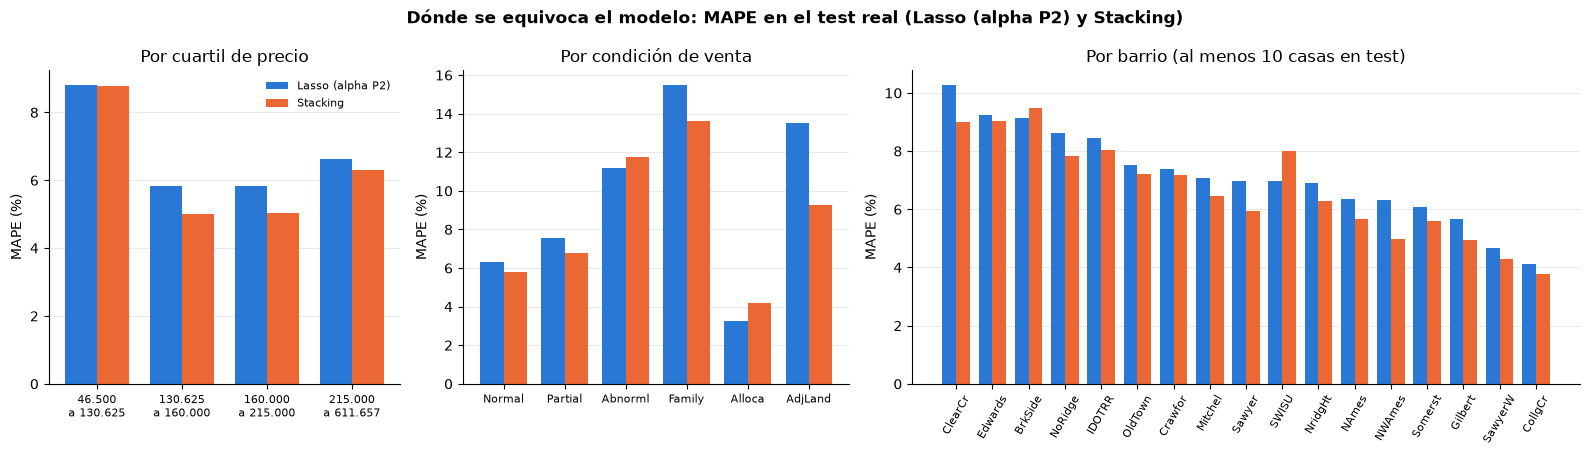

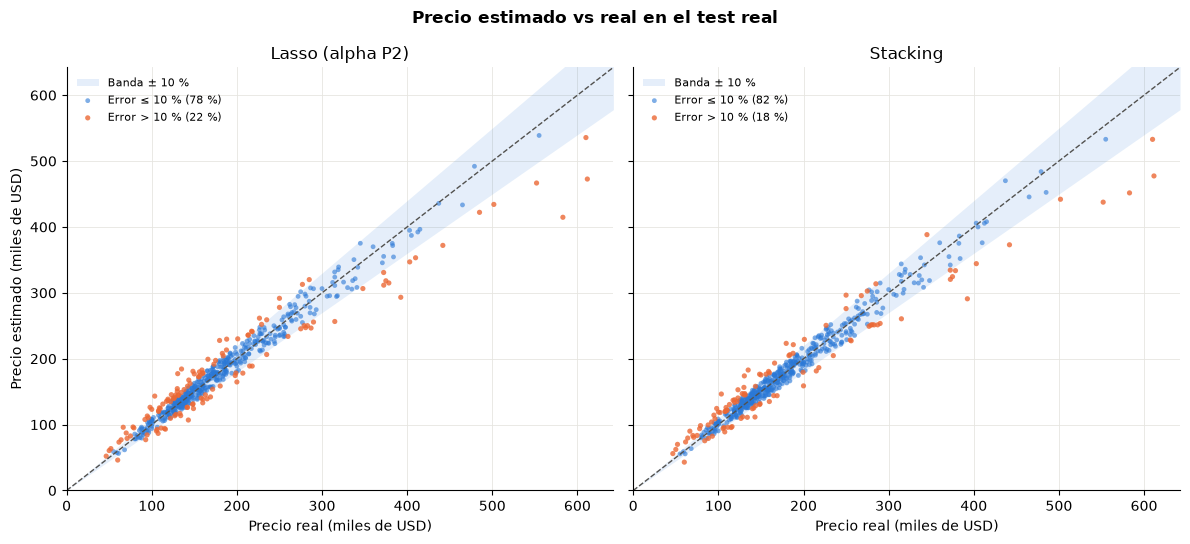

In [101]:
SEGUNDO = mejor if mejor != elegido_p4 else 'Lasso'
PAR = [elegido_p4, SEGUNDO]
real = y_test_base
error_rel = pd.DataFrame({m: (pred_test[('Test real', m)] - real) / real * 100 for m in PAR})   # > 0: sobreestima
error_abs = error_rel.abs()

cuartil = pd.qcut(real, 4)
cuartil = cuartil.cat.rename_categories([f"{usd(i.left)} a {usd(i.right)}" for i in cuartil.cat.categories])
por_cuartil = pd.concat({'MAPE %': error_abs.groupby(cuartil, observed=True).mean(),
                         'Error con signo %': error_rel.groupby(cuartil, observed=True).mean()}, axis=1)
por_cuartil.index.name = 'Precio real (USD)'
print("=== Por cuartil de precio (test real) ===")
print(por_cuartil.round(1).to_string())

condicion = seg_test['Sale Condition']
por_condicion = pd.concat({'Casas': condicion.value_counts(), 'MAPE %': error_abs.groupby(condicion).mean()}, axis=1)
print("\n=== Por condición de venta ===")
print(por_condicion.sort_values(('Casas', 'count'), ascending=False).round(1).to_string())

barrio = seg_test['Neighborhood']
n_barrio = barrio.value_counts()
grandes = n_barrio[n_barrio >= MIN_CASAS_BARRIO].index
por_barrio = error_abs[barrio.isin(grandes)].groupby(barrio).mean()
por_barrio.insert(0, 'Casas', n_barrio)
print(f"\n=== Por barrio (barrios con al menos {MIN_CASAS_BARRIO} casas en test) ===")
print(por_barrio.sort_values(elegido_p4, ascending=False).round(1).to_string())

caras = real > 450_000
print(f"\nCasas de más de 450.000 USD: {caras.sum()}")
for m in PAR:
    print(f"  {m:17s} subestimadas: {(error_rel.loc[caras, m] < 0).sum()} de {caras.sum()} | error con signo medio "
          f"{error_rel.loc[caras, m].mean():+.1f} % | MAPE {error_abs.loc[caras, m].mean():.1f} %")

print("\n=== Distribución del error absoluto % ===")
for m in PAR:
    e = error_abs[m]
    print(f"  {m:17s} mediana {e.median():.1f} % | < 5 %: {(e < 5).mean() * 100:.1f} % | < 10 %: {(e < 10).mean() * 100:.1f} % | "
          f"< 20 %: {(e < 20).mean() * 100:.1f} % | > 30 %: {(e > 30).sum()} casas")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={'width_ratios': [1, 1.1, 1.9]})
colores_par = {elegido_p4: COLOR_VAL, SEGUNDO: COLOR_TRAIN}
ancho = 0.38
for ax, tabla, titulo in [(axes[0], por_cuartil['MAPE %'], 'Por cuartil de precio'),
                          (axes[1], por_condicion['MAPE %'].loc[por_condicion[('Casas', 'count')].sort_values(ascending=False).index], 'Por condición de venta')]:
    x = np.arange(len(tabla))
    for k, m in enumerate(PAR):
        ax.bar(x + (k - 0.5) * ancho, tabla[m], ancho, color=colores_par[m], label=m)
    ax.set_xticks(x, [str(i).replace(' a ', '\na ') for i in tabla.index], fontsize=8)
    ax.set(title=titulo, ylabel='MAPE (%)')
    ax.grid(axis='x', visible=False)
tabla = por_barrio.sort_values(elegido_p4, ascending=False)
x = np.arange(len(tabla))
for k, m in enumerate(PAR):
    axes[2].bar(x + (k - 0.5) * ancho, tabla[m], ancho, color=colores_par[m], label=m)
axes[2].set_xticks(x, tabla.index, rotation=60, fontsize=8)
axes[2].set(title=f'Por barrio (al menos {MIN_CASAS_BARRIO} casas en test)', ylabel='MAPE (%)')
axes[2].grid(axis='x', visible=False)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f'Dónde se equivoca el modelo: MAPE en el test real ({elegido_p4} y {SEGUNDO})', fontsize=12, fontweight='bold')
fig.tight_layout()
guardar_figura(fig, 'p4_06_error_por_segmento')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
limite = max(real.max(), max(pred_test[('Test real', m)].max() for m in PAR)) / 1000 * 1.05
for ax, m in zip(axes, PAR):
    pred = pred_test[('Test real', m)]
    dentro = error_abs[m] <= 10
    xs = np.array([0, limite])
    ax.fill_between(xs, xs * 0.9, xs * 1.1, color=COLOR_VAL, alpha=0.12, linewidth=0, label='Banda ± 10 %')
    ax.plot(xs, xs, color=COLOR_REF, linewidth=1, linestyle='--')
    ax.scatter(real[dentro] / 1000, pred[dentro] / 1000, s=12, color=COLOR_VAL, alpha=0.6, edgecolors='none',
               label=f'Error ≤ 10 % ({dentro.mean() * 100:.0f} %)')
    ax.scatter(real[~dentro] / 1000, pred[~dentro] / 1000, s=14, color=COLOR_TRAIN, alpha=0.8, edgecolors='none',
               label=f'Error > 10 % ({(~dentro).mean() * 100:.0f} %)')
    ax.set(xlim=(0, limite), ylim=(0, limite), title=m, xlabel='Precio real (miles de USD)')
    ax.legend(frameon=False, fontsize=8, loc='upper left')
axes[0].set_ylabel('Precio estimado (miles de USD)')
fig.suptitle('Precio estimado vs real en el test real', fontsize=12, fontweight='bold')
fig.tight_layout()
guardar_figura(fig, 'p4_07_real_vs_predicho')
plt.show()

- Cuartil barato (hasta 130.625 USD): el error más alto en los dos modelos (8,8 % en ambos) y la misma sobreestimación (+3,4 % en Lasso y +3,9 % en el stacking). El stacking no lo corrige.
- Casas caras: de las 9 de más de 450.000 USD, los dos subestiman 8, en −12,5 % (Lasso) y −11,5 % (stacking) en promedio. El ensamble mejora apenas 1 punto y la limitación sigue. Con 9 casas de ese precio en test y pocas en train, ningún modelo tiene datos para aprender ese mercado.
- Donde el stacking sí mejora es en el centro: en los dos cuartiles del medio el MAPE baja de 5,8 % a 5,0 %, en las ventas `Normal` de 6,3 % a 5,8 %, y mejora en 15 de los 17 barrios. Es una mejora pareja en las casas fáciles, no una corrección de los casos difíciles.
- Ventas anómalas: `Abnorml` queda en 11,2 % con Lasso y 11,8 % con el stacking. Siguen siendo un límite, porque la condición de venta no se conoce al tasar.
- Barrios: con Lasso el peor es `ClearCr` (10,3 %) y el mejor `CollgCr` (4,1 %). El stacking es peor que Lasso en `SWISU` (8,0 % frente a 7,0 %) y `BrkSide` (9,5 % frente a 9,1 %).
- Distribución: con Lasso la mitad de las casas tiene un error menor a 5,3 %, el 77,8 % menor a 10 % y el 96,6 % menor a 20 %, y solo 4 superan el 30 %. Con el stacking: 4,9 %, 81,8 % y 96,2 %, con 5 casas sobre 30 %.

El ensamble no corrige los extremos, que es donde el perito más necesita ayuda. Esas casas se derivan a revisión manual con alertas (sección 51), con cualquiera de los dos modelos.

## 51. Aplicación al contexto: cómo lo usa el tasador

`tasar(casa)` recibe una casa (una fila con las 79 variables sin codificar) y devuelve:

- Valor estimado, con la venta normal impuesta (al tasar no se sabe cómo se cerrará la venta, sección 11) y `Yr Sold = 2010` (el modelo tasa a precios de 2010 y no extrapola, sección 18).
- Rango orientativo: el valor multiplicado por los percentiles 10 y 90 del cociente entre precio real y estimado de las predicciones fuera de fold en train. En 8 de cada 10 casas de train el precio real cayó en ese rango. No es un intervalo de confianza formal: supone que el error relativo es parecido en todas las casas, y la sección 50 mostró que es mayor en los extremos.
- Desglose: en un modelo lineal, el aporte de cada variable respecto de una casa con los valores promedio de train, en porcentaje aproximado (en escala log el modelo es una suma, sección 26). Las dummies de una misma variable se suman. Si el modelo elegido fuera de árboles, se informaría la importancia por permutación global y el aviso de que el desglose por casa requiere SHAP (advertencia 10).
- Alertas de revisión manual: valor sobre 450.000 USD, cuartil más barato, zona no residencial (fuera de alcance, sin estimación) y datos atípicos respecto de train (fuera del 99 % central de alguna superficie).

Lo probamos con tres casas reales del test (una típica, la más cara y la más barata) y con la casa típica cambiada a zona comercial.

In [102]:
modelo_final = entrenados_p4[elegido_p4]
ES_LINEAL = NIVEL_INTERPRETABILIDAD[elegido_p4] == 0

oof_final = predecir_fuera_de_fold(f'oof_{ARCHIVO[elegido_p4]}', lambda: construir_candidato(elegido_p4))
cociente = y_train_base / oof_final
P10, P90 = cociente.quantile([0.10, 0.90])
print(f"Precio real / estimado fuera de fold ({elegido_p4}): percentil 10 = {P10:.3f}, percentil 90 = {P90:.3f} "
      f"-> rango de {(P10 - 1) * 100:+.1f} % a {(P90 - 1) * 100:+.1f} % alrededor del valor estimado")

UMBRAL_CARO = 450_000
UMBRAL_BARATO = y_train_base.quantile(0.25)
VARIABLES_RANGO = [c for c in cols_continuas if c != 'SalePrice']
RANGO_TRAIN = X_train_base[VARIABLES_RANGO].quantile([0.005, 0.995])
CARAS_SUBESTIMADAS = f"{(error_rel.loc[caras, elegido_p4] < 0).sum()} de {caras.sum()}"
SESGO_BARATO = por_cuartil[('Error con signo %', elegido_p4)].iloc[0]

if ES_LINEAL:
    pipe = modelo_final.regressor_
    pre, lineal = pipe.named_steps['pre'], pipe.named_steps['modelo']
    MEDIA_TRAIN = pre.transform(X_train_base).mean()
    BASE_LOG = lineal.intercept_ + MEDIA_TRAIN.values @ lineal.coef_
else:
    muestra = X_train_base.sample(500, random_state=RANDOM_STATE)
    IMPORTANCIA_GLOBAL = importancia_por_variable(modelo_final, muestra, y_train_base.loc[muestra.index], repeticiones=5)


def variable_original(columna):
    return columna if columna.startswith('Tiene_') else columna.split('_')[0]


def tasar(casa: pd.DataFrame, n_variables=8) -> dict:
    assert len(casa) == 1
    fila = casa.iloc[0]
    if fila['MS Zoning'] in zonas_no_residenciales + ['No residencial']:
        return {'alcance': 'FUERA DE ALCANCE: zona no residencial (sección 9). Tasación manual.'}
    casa = imponer_venta_normal(casa)          # al tasar no se sabe cómo se cerrará la venta
    casa = casa.assign(**{'Yr Sold': 2010})    # último año de los datos: el modelo no extrapola (sección 18)
    valor = float(modelo_final.predict(casa)[0])
    resultado = {'valor_estimado': round(valor), 'rango_orientativo': (round(valor * P10), round(valor * P90))}

    if ES_LINEAL:
        aportes = ((pre.transform(casa).iloc[0] - MEDIA_TRAIN) * lineal.coef_).groupby(variable_original).sum()
        assert np.isclose(np.expm1(BASE_LOG + aportes.sum()), valor)   # el desglose suma exactamente la estimación
        principales = aportes.reindex(aportes.abs().sort_values(ascending=False).index).head(n_variables)
        resultado['punto_de_partida'] = round(float(np.expm1(BASE_LOG)))
        resultado['desglose_%'] = {v: round(float(np.expm1(a) * 100), 1) for v, a in principales.items()}
        resultado['desglose_%']['Resto de variables'] = round(float(np.expm1(aportes.sum() - principales.sum()) * 100), 1)
    else:
        resultado['variables_mas_importantes (global)'] = list(IMPORTANCIA_GLOBAL.head(n_variables).index)
        resultado['aviso'] = 'Modelo sin desglose directo por casa: requeriría SHAP.'

    alertas = []
    if valor > UMBRAL_CARO:
        alertas.append(f'Valor sobre {usd(UMBRAL_CARO)} USD: en test el modelo subestimó {CARAS_SUBESTIMADAS} casas así (sección 50). Revisión manual.')
    if valor <= UMBRAL_BARATO:
        alertas.append(f'Cuartil más barato (hasta {usd(UMBRAL_BARATO)} USD): el modelo tiende a sobreestimar ({SESGO_BARATO:+.1f} % en test).')
    fuera = [v for v in VARIABLES_RANGO
             if not RANGO_TRAIN.loc[0.005, v] <= fila[v] <= RANGO_TRAIN.loc[0.995, v]]
    if fuera:
        alertas.append(f'Datos atípicos respecto de train (fuera del 99 % central): {fuera}. Verificar el registro.')
    resultado['alertas'] = alertas or ['Ninguna']
    return resultado


def mostrar_tasacion(titulo, casa, precio_real=None):
    r = tasar(casa)
    print(f"--- {titulo} (id {casa.index[0]}, {casa.iloc[0]['Neighborhood']}, {casa.iloc[0]['Sale Condition']}) ---")
    if 'alcance' in r:
        print(f"  {r['alcance']}\n")
        return
    real_txt = f" | precio real de venta: {usd(precio_real)} USD ({(r['valor_estimado'] / precio_real - 1) * 100:+.1f} %)" if precio_real else ''
    print(f"  Valor estimado: {usd(r['valor_estimado'])} USD | rango orientativo: {usd(r['rango_orientativo'][0])} a "
          f"{usd(r['rango_orientativo'][1])} USD{real_txt}")
    if 'desglose_%' in r:
        print(f"  Punto de partida (casa promedio de train): {usd(r['punto_de_partida'])} USD. Efecto aproximado de cada variable:")
        print('   ' + ' | '.join(f"{v} {p:+.1f} %" for v, p in r['desglose_%'].items()))
    else:
        print(f"  {r['aviso']} Variables más importantes: {r['variables_mas_importantes (global)']}")
    print(f"  Alertas: {' / '.join(r['alertas'])}\n")


ejemplos = {'Casa típica (precio más cercano a la mediana)': (y_test_base - y_test_base.median()).abs().idxmin(),
            'Casa cara (la de mayor precio del test)': y_test_base.idxmax(),
            'Casa barata (la de menor precio del test)': y_test_base.idxmin()}
for titulo, i in ejemplos.items():
    mostrar_tasacion(titulo, X_test_abierto.loc[[i]], y_test_base[i])
tipica = X_test_abierto.loc[[ejemplos['Casa típica (precio más cercano a la mediana)']]].assign(**{'MS Zoning': 'C (all)'})
mostrar_tasacion('La misma casa típica, si estuviera en zona comercial', tipica)

Precio real / estimado fuera de fold (Lasso (alpha P2)): percentil 10 = 0.889, percentil 90 = 1.135 -> rango de -11.1 % a +13.5 % alrededor del valor estimado
--- Casa típica (precio más cercano a la mediana) (id 1606, Mitchel, Normal) ---
  Valor estimado: 175.624 USD | rango orientativo: 156.211 a 199.332 USD | precio real de venta: 160.000 USD (+9.8 %)
  Punto de partida (casa promedio de train): 167.311 USD. Efecto aproximado de cada variable:
   Functional -7.9 % | Gr Liv Area +8.3 % | Overall Cond +6.2 % | Year Built -4.6 % | 2nd Flr SF +3.5 % | Lot Area +2.6 % | Garage Cars -2.2 % | Exterior 1st +1.5 % | Resto de variables -1.4 %
  Alertas: Ninguna

--- Casa cara (la de mayor precio del test) (id 44, NridgHt, Partial) ---
  Valor estimado: 472.711 USD | rango orientativo: 420.459 a 536.525 USD | precio real de venta: 611.657 USD (-22.7 %)
  Punto de partida (casa promedio de train): 167.311 USD. Efecto aproximado de cada variable:
   Gr Liv Area +21.4 % | Total Bsmt SF +21.0 % |

- El rango orientativo va de −11,1 % a +13,5 % alrededor del valor estimado. Es asimétrico porque las subestimaciones grandes son más frecuentes que las sobreestimaciones grandes (sección 50).
- Casa típica (`Mitchel`, vendida en 160.000 USD): el modelo estima 175.624 USD (+9,8 %) y el precio real queda dentro del rango (156.211 a 199.332). La superficie habitable suma 8,3 % y la condición general 6,2 %, y la funcionalidad (`Functional`, con deducciones menores) resta 7,9 % y el año de construcción 4,6 %. La funcionalidad es el dato que más baja el valor, así que el perito puede revisar si está bien registrada.
- Casa más cara (611.657 USD, nueva, en `NridgHt`): estima 472.711 USD (−22,7 %), fuera del rango, pero la herramienta avisa que el valor supera 450.000 USD y que `BsmtFin SF 1` es atípico. Es justo el caso que tiene que revisar el perito.
- Casa más barata (46.500 USD, venta `Abnorml` en `OldTown`): estima 56.235 USD (+20,9 %). Las alertas marcan el cuartil barato y una superficie habitable atípicamente chica. Parte del error es la venta anómala: el modelo estima el valor en una venta normal, que es lo que se le pide.
- Zona comercial: la herramienta no estima y deriva a tasación manual (sección 9).

Para el negocio: el perito obtiene en segundos un punto de partida con un error típico de 5 % a 10 %, un rango para contrastar su propia tasación, el detalle de qué variables movieron el valor (para justificarlo y para detectar datos mal registrados) y avisos donde el modelo es menos confiable. En los ejemplos, las dos casas con error grande quedaron marcadas y la típica, sin alertas, quedó dentro del rango. Si la tasación del perito difiere mucho del rango, es una señal para revisarla, no una prueba de que esté mal.

## 52. Modelo final guardado, conclusiones y traspaso

Se guarda el modelo elegido, entrenado con todo train: `models/modelo_final.joblib` (el pipeline completo, que recibe las 79 variables sin codificar y devuelve dólares) y `models/modelo_final.json` (parámetros, métricas de validación y de test en los dos escenarios, forma de uso, versiones y fecha). La celda comprueba que el modelo cargado desde disco predice lo mismo que el de memoria.

Antes de usarlo en producción convendría reentrenarlo con train y test juntos, las 2.896 casas residenciales. No lo hacemos aquí porque nos dejaría sin una medición independiente.

In [103]:
RUTA_MODELO = Path('../models/modelo_final.joblib')
joblib.dump(modelo_final, RUTA_MODELO)

parametros_final = ({'alpha': ALPHA_P2['Lasso']} if elegido_p4 == 'Lasso (alpha P2)'
                    else json.loads(RUTA_PARAMS.read_text(encoding='utf-8'))['modelos'].get(elegido_p4, {}).get('params', {}))
ficha = {
    'modelo': elegido_p4,
    'descripcion': 'Pipeline completo (MapeoOrdinal + preparación + modelo) dentro de TransformedTargetRegressor (log1p / expm1). '
                   'Recibe las 79 variables sin codificar de ames_clean.csv y devuelve el precio en USD.',
    'parametros': parametros_final,
    'columnas_en_uso': columnas_en_uso(modelo_final) if ES_LINEAL else None,
    'escenario_seleccion': escenario,
    'regla': 'cumple los seis KPI en test real; menor RMSE val; a menos de 1 punto de R² val, el más interpretable',
    'metricas_cv': metricas_json(elegidos[elegido_p4]),
    'metricas_cv_folds_nuevos': {'rmse_val': round(float(nuevos[elegido_p4]['RMSE val']), 1),
                                 'r2_val': round(float(nuevos[elegido_p4]['R² val']), 4)},
    'metricas_test': {e: resultados_test['resultados'][e][elegido_p4] for e in ESCENARIOS_TEST},
    'uso': {'venta': 'imponer_venta_normal() antes de predecir', 'yr_sold': 2010,
            'rango_orientativo': [round(float(P10), 4), round(float(P90), 4)],
            'alcance': 'viviendas en zonas residenciales de Ames; precios 2006-2010'},
    'entrenado_con': f'{len(X_train_base)} casas de train',
    'versiones': {'python': sys.version.split()[0], 'numpy': np.__version__, 'pandas': pd.__version__,
                  'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__, 'joblib': joblib.__version__},
    'fecha': datetime.date.today().isoformat(),
}
RUTA_MODELO.with_suffix('.json').write_text(json.dumps(ficha, indent=2, ensure_ascii=False), encoding='utf-8')

cargado = joblib.load(RUTA_MODELO)
assert np.allclose(cargado.predict(X_train_base), modelo_final.predict(X_train_base))
assert np.allclose(cargado.predict(X_test_abierto), pred_test[('Test real', elegido_p4)])
print(f"Guardado: {RUTA_MODELO} ({RUTA_MODELO.stat().st_size / 1024:.0f} KB) y {RUTA_MODELO.with_suffix('.json').name}. "
      "El modelo cargado predice lo mismo que el de memoria.")
print(f"Archivos de la parte 4 en {RUTA_PARTE4}: {len(list(RUTA_PARTE4.rglob('*.json')))}")
print(f"Figuras: {sorted(p.name for p in RUTA_IMAGENES.glob('p4_*.png'))}")

resumen = pd.DataFrame({'Umbral': [f"{s} {u:g}" for s, u in KPI.values]}, index=KPI.index)
for e in ESCENARIOS_TEST:
    resumen[e] = [f"{float(v):.{formato[k]}f}" for k, v in kpis_p4.loc[(e, elegido_p4)].items()]
    resumen[f'¿Cumple? ({e})'] = cumplimiento_p4.loc[(e, elegido_p4)].drop('Cumple los seis').map({True: '✔', False: '✘'}).values
print(f"\n=== Modelo final: {elegido_p4} ===")
print(resumen.to_string())

Guardado: ..\models\modelo_final.joblib (30 KB) y modelo_final.json. El modelo cargado predice lo mismo que el de memoria.
Archivos de la parte 4 en ..\models\parte4: 24
Figuras: ['p4_01_bagging_boosting.png', 'p4_02_residuos_lasso_xgb.png', 'p4_03_comparacion_ensambles.png', 'p4_04_folds_nuevos.png', 'p4_05_curvas_aprendizaje.png', 'p4_06_error_por_segmento.png', 'p4_07_real_vs_predicho.png']

=== Modelo final: Lasso (alpha P2) ===
                             Umbral Test real ¿Cumple? (Test real) Venta normal impuesta ¿Cumple? (Venta normal impuesta)
KPI                                                                                                                      
R²                           ≥ 0.85     0.948                    ✔                 0.949                                ✔
RMSE                        ≤ 30000     19241                    ✔                 19084                                ✔
MAE                         ≤ 20000     12407                    ✔         

### 52.1 Conclusiones

Modelo final: Lasso con `alpha` = 0,000174, 105 columnas en uso.

| KPI | Umbral | Test real | Venta normal impuesta |
|---|---|---|---|
| R² | ≥ 0,85 | 0,948 ✔ | 0,949 ✔ |
| RMSE | ≤ 30.000 USD | 19.241 USD ✔ | 19.084 USD ✔ |
| MAE | ≤ 20.000 USD | 12.407 USD ✔ | 12.462 USD ✔ |
| MAPE | ≤ 12 % | 6,77 % ✔ | 6,93 % ✔ |
| Brecha de R² train-test | ≤ 5 puntos | −0,9 ✔ | −1,0 ✔ |
| Brecha de MAPE entre barrios | ≤ 8 puntos | 6,1 ✔ | 6,2 ✔ |

| Parte | Qué se hizo | Resultado |
|---|---|---|
| P2 | Preparación por familia de modelos y comparación con parámetros iniciales | Lasso elegido; los árboles sobreajustaban (brecha de 6,1 y 6,3 en test) |
| P3 | Búsqueda de hiperparámetros (aleatoria, grillas, curvas) en los cuatro modelos | XGBoost deja de sobreajustar y baja 2.542 USD; queda casi empatado con Lasso. Random Forest cumple la brecha pero no mejora. Los lineales no cambian |
| P4 | Bagging, boosting, votación y stacking; folds nuevos, validación anidada, curvas de aprendizaje; test único | Los ensambles vuelven competitivos a los árboles y el stacking supera a Lasso por poco (0,66 puntos de R²); se mantiene Lasso por la regla, la trazabilidad y la robustez |

¿Los ensambles mejoraron? Frente a un árbol solo, sí: promediar 300 árboles (bagging) baja el error de 37.604 a 25.512 USD y sumar árboles en secuencia (boosting) llega a 19.809. Combinar Lasso con XGBoost dio el menor error del proyecto en validación (19.203 USD), en 15 de 15 folds nuevos y en test (17.903 USD, R² 0,955). Pero frente a Lasso la mejora es menor que la variación entre folds y que el punto de R² que exige la regla, depende de XGBoost (optimismo moderado y configuración inestable) y pierde el desglose de cada tasación. Para este problema, el modelo lineal sigue siendo la mejor solución.

Capacidad de generalización: en los lineales y en Random Forest la validación no fue optimista (menos de 0,4 % de diferencia con folds nuevos); en XGBoost hubo un optimismo moderado (+440 USD, 2,2 %), esperable tras 467 configuraciones. El orden de los modelos se mantuvo en test, y en todos el error de test quedó bajo el de validación (entre 0,6 y 2,8 desviaciones entre folds; en el Lasso elegido, 0,9). El modelo no rinde peor con casas nuevas. Lasso converge con los datos disponibles y, con el `alpha` del P2, tiene 4,0 puntos de margen en la brecha.

### 52.2 Limitaciones

- Precios de 2006 a 2010, incluida la crisis de 2008: el modelo tasa a precios de ese período y no sirve sin actualizar para el mercado actual.
- Extremos de precio: subestima las casas de más de 450.000 USD (8 de 9 en test, −12,5 % en promedio) y sobreestima el cuartil más barato (+3,4 %). Ningún ensamble lo corrigió.
- Ventas anómalas (`Abnorml`, `Family`): error de 11 % a 16 %, y no se pueden identificar antes de vender.
- Zonas no residenciales fuera de alcance: van a tasación manual.
- El rango orientativo no es un intervalo de confianza formal y es más estrecho de lo real en los extremos.
- La brecha de Random Forest cumplió con poco margen en validación (0,2 puntos) y la de XGBoost con 0,7 en folds nuevos. En test cumplieron con holgura, pero con otros datos podrían no hacerlo.
- La codificación de las variables no entró a la búsqueda de hiperparámetros (advertencia 9 de la sección 40).
- No comparamos los ensambles con un árbol de decisión ajustado por separado (sección 42).
- Los resultados de los modelos de árboles cambian según el sistema operativo, y en XGBoost eso puede cambiar la configuración ganadora dentro de la zona plana. Las conclusiones no dependen de ello: Lasso da lo mismo en cualquier sistema.

### 52.3 Recomendaciones para el negocio

1. Usar el modelo como valor de partida del perito en viviendas de zonas residenciales, con la venta normal impuesta y `Yr Sold = 2010`, junto con el rango y el desglose de `tasar()`.
2. Revisión manual obligatoria en los casos con alerta: valor sobre 450.000 USD, cuartil barato, datos atípicos y zonas no residenciales.
3. Antes de usarlo con precios actuales, reentrenar con datos recientes; mientras tanto, ajustar los valores con un índice de precios de vivienda.
4. Monitorear el error por barrio, en especial `IDOTRR`, `Edwards`, `BrkSide` y `ClearCr`, y reentrenar de forma periódica (por ejemplo, una vez al año) con las tasaciones y ventas nuevas.
5. Si en el futuro se prioriza la precisión sobre la trazabilidad, el candidato es el stacking de Lasso y XGBoost (1.338 USD menos de RMSE en test), con SHAP para explicar cada tasación y siempre que mantenga la equidad entre barrios con venta normal (hoy 7,5 de un máximo de 8). Según las curvas de aprendizaje, XGBoost es el que más ganaría con más datos.

### 52.4 Traspaso

Qué se decidió:

- Protocolo de la sección 41: mismos datos, folds y métricas; test abierto una sola vez; lista cerrada de siete candidatos.
- Modelo final: Lasso con el `alpha` del P2 (escenario b), por la regla de la sección 20 aplicada en código (sección 49).

Qué queda disponible:

- `models/modelo_final.joblib` y `models/modelo_final.json`: el modelo final entrenado con todo train y su ficha. Se carga con `joblib.load('../models/modelo_final.joblib')`, con las clases propias del pipeline (como `MapeoOrdinal`) ya definidas, y predice sobre las 79 variables sin codificar después de aplicar `imponer_venta_normal` y `Yr Sold = 2010`.
- `models/parte4/`: validaciones cruzadas de los ensambles, folds nuevos, validación anidada, curvas, pesos del stacking, predicciones fuera de fold y `resultados_test.json`.
- `models/mejores_params.json` y `models/busquedas/`: configuraciones y búsquedas de la parte 3.
- `tasar(casa)`, `construir_candidato(nombre)` y `construir_combinacion(tipo, bases)`.
- `images/p3_01` a `p3_08` e `images/p4_01` a `p4_07`: las figuras de las partes 3 y 4.

Advertencias:

1. `REPETIR_PARTE4 = False` carga lo guardado en `models/parte4/` y calcula solo lo que falta; `True` recalcula todo.
2. La celda de la sección 48 se ejecuta una sola vez por sesión (bandera `TEST_ABIERTO`). Para repetirla hay que reiniciar el kernel y ejecutar el notebook completo.
3. El modelo guardado se carga solo con las versiones de `requirements.txt` (en particular scikit-learn 1.6.1).
4. En Windows conviene ejecutar con Python en modo UTF-8 (`PYTHONUTF8=1`): algunas celdas de la parte 3 leen y escriben JSON sin indicar la codificación, y sin ese modo Windows usa cp1252 y deja `mejores_params.json` con los acentos mal codificados.
5. El nombre `cumple` (función de la sección 20) se reutiliza como variable en la sección 35; la parte 4 usa `cumple_kpi`, con la misma regla.
6. Todas las cifras de este notebook salen de una sola ejecución en Windows. En Linux o Colab, Random Forest, XGBoost y los ensambles pueden dar otros resultados y XGBoost podría elegir otra configuración de la zona plana; Ridge y Lasso dan lo mismo. Al ejecutar este notebook en Linux con las búsquedas guardadas, la votación y el stacking dejaron de cumplir la equidad entre barrios con venta normal, mientras que el modelo elegido no cambió (informe técnico, sección 15.3).

**Archivos generados**

La última celda lista lo que quedó en `models/` y en `images/`. En Colab, además, los comprime (`models.zip` e `images.zip`) para descargarlos antes de que termine la sesión.

In [104]:
RUTA_MODELS = Path('../models').resolve()
RUTA_IMAGES = Path('../images').resolve()
for ruta in [RUTA_MODELS, RUTA_IMAGES]:
    print(f"{ruta}: {len(list(ruta.rglob('*.*')))} archivos")
    for p in sorted(ruta.iterdir()):
        print(' ', p.name)

if EN_COLAB:
    for ruta in [RUTA_MODELS, RUTA_IMAGES]:
        archivo_zip = shutil.make_archive(str(ruta), 'zip', ruta)
        print(f"Copia comprimida para descargar: {archivo_zip}")

C:\Users\Gorbash\Desktop\EP3 Machine Learning\models: 63 archivos
  busquedas
  mejores_params.json
  modelo_final.joblib
  modelo_final.json
  parte4
C:\Users\Gorbash\Desktop\EP3 Machine Learning\images: 15 archivos
  p3_01_rf_diagnostico.png
  p3_02_xgb_diagnostico.png
  p3_03_rf_curvas_validacion.png
  p3_04_xgb_curvas_validacion.png
  p3_05_convergencia_busqueda.png
  p3_06_error_vs_brecha.png
  p3_07_lineales_alpha.png
  p3_08_antes_despues.png
  p4_01_bagging_boosting.png
  p4_02_residuos_lasso_xgb.png
  p4_03_comparacion_ensambles.png
  p4_04_folds_nuevos.png
  p4_05_curvas_aprendizaje.png
  p4_06_error_por_segmento.png
  p4_07_real_vs_predicho.png
